In [3]:
from __future__ import division
import json
%matplotlib inline
import numpy as np
import pandas as pd
from collections import defaultdict, Counter
import itertools, operator
import csv
import os,glob
import datetime
import geopandas as gpd
from shapely import wkt
from scipy.stats import linregress, spearmanr
import statsmodels.api as sm
from scipy.stats import pearsonr
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LogNorm
import math
import statsmodels.api as sm
from sklearn.model_selection import train_test_split


import os, pandas as pd, geopandas as gpd
from shapely import wkt
from IPython.display import display

import pandas as pd
import geopandas as gpd
from shapely.geometry import Point, Polygon, box

import osmnx as ox

import networkx as nx
import collections

from scipy.stats import gaussian_kde

from scipy.spatial import cKDTree

from IPython.display import display

import os
import sys

# INFORMATION

In [4]:
dates = ['_07_2022','_07_2023','_08_2022','_08_2023'] #,'_07_2023','_08_2022','_08_2023'

In [5]:
DATE = '2022_2023'

In [6]:
DISTRICTS_THRESHOLD = False

# COLORS

In [7]:
colors_income = ['#FCBF49','#F77F00','#D62828'] #low, medium, high
colors_gender = ['#7209B7','#4CC9F0'] #fem, mal
colors_age = ['#BE95C4','#9F86C0','#5E548E','#231942'] #young->old

In [8]:
from matplotlib.colors import LinearSegmentedColormap
cmap_income = LinearSegmentedColormap.from_list('income', colors_income)
cmap_gender = LinearSegmentedColormap.from_list('gender', colors_gender)
cmap_age = LinearSegmentedColormap.from_list('age', colors_age)

# CITIES

In [9]:
cities = ['Madrid', 'Barcelona', 'Valencia', 'Zaragoza', 'Sevilla', 'Malaga', 'Murcia', 'Palma_de_Mallorca', 'Las_Palmas',
          'Alicante', 'Bilbao', 'Valladolid', 'Cordoba', 'Vigo', 'Gijon', 'Vitoria_Gasteiz', 'A_Coruna', 'Granada', 'Elche', 
          'Cartagena', 'Oviedo', 'Jerez_de_la_Frontera', 'Santa_Cruz_de_Tenerife'] #

In [10]:
len(cities)

23

# OPEN DISTRICTS DATA

In [11]:
os.chdir(r'C:\Users\mduran\Desktop\PhD\PROJECT 2\dataframes')

gdfs = []
for d in dates:
    df = pd.read_csv(f'results_districts{d}.csv')

    # 2.2 convierte geometry (WKT → shapely)
    if df['geometry'].dtype == object:
        df['geometry'] = df['geometry'].apply(wkt.loads)

    gdf = gpd.GeoDataFrame(df, geometry='geometry', crs='EPSG:25830')
    gdfs.append(gdf)

    print(f'\n── Valores distritales {d} ─────────────────────────────')
    display(gdf[['city','ID','avg_T']].head())

# ── 3. UNE LOS MESES ───────────────────────────────────────────────────────────
results_districts = pd.concat(gdfs, ignore_index=True)

# ── 4. PROMEDIA VARIABLES NUMÉRICAS POR city + district_id ─────────────────────
num_cols   = [c for c in results_districts.select_dtypes('number').columns
              if c not in ['x', 'y']]                # x,y se recalcularán
group_cols = ['city', 'ID']

results_districts = (results_districts
                     .groupby(group_cols, as_index=False)
                     .agg({**{c: 'mean' for c in num_cols},
                           'geometry': 'first'}))

results_districts = gpd.GeoDataFrame(results_districts,
                                     geometry='geometry',
                                     crs='EPSG:25830')

# ── 5. CENTROIDES + COORDENADAS (x,y) NUEVAS ───────────────────────────────────
cent = results_districts.geometry.centroid
results_districts['x'] = cent.x
results_districts['y'] = cent.y

# ── 6. DICCIONARIO POR CIUDAD (opcional, como antes) ──────────────────────────
results_districts = {c: g.copy() for c, g in results_districts.groupby('city')}


── Valores distritales _07_2022 ─────────────────────────────


,city,ID,avg_T
0,Vitoria_Gasteiz,01001,37.789074
1,Bilbao,01002,36.407897
2,Bilbao,01004_AM,31.719118
3,Vitoria_Gasteiz,01009_AM,36.294266
4,Vitoria_Gasteiz,01017_AM,34.923216



── Valores distritales _07_2023 ─────────────────────────────


,city,ID,avg_T
0,Vitoria_Gasteiz,01001,32.397593
1,Bilbao,01002,28.571729
2,Bilbao,01004_AM,26.368529
3,Vitoria_Gasteiz,01009_AM,29.919755
4,Vitoria_Gasteiz,01017_AM,28.463876



── Valores distritales _08_2022 ─────────────────────────────


,city,ID,avg_T
0,Vitoria_Gasteiz,01001,37.228333
1,Bilbao,01002,34.345701
2,Bilbao,01004_AM,28.830882
3,Vitoria_Gasteiz,01009_AM,35.204281
4,Vitoria_Gasteiz,01017_AM,33.107865



── Valores distritales _08_2023 ─────────────────────────────


,city,ID,avg_T
0,Vitoria_Gasteiz,01001,36.241111
1,Bilbao,01002,32.248785
2,Bilbao,01004_AM,27.704118
3,Vitoria_Gasteiz,01009_AM,33.954817
4,Vitoria_Gasteiz,01017_AM,31.933235


In [12]:
results_districts

{'A_Coruna':         city       ID      avg_T  median_revenue_per_consumption  population  \
 0   A_Coruna    15005  29.025792                          17.675     32894.0   
 1   A_Coruna  1501701  31.846875                          18.550     17791.0   
 2   A_Coruna  1501702  30.683409                          19.950      6825.0   
 3   A_Coruna    15021  30.359953                          18.200      6574.0   
 4   A_Coruna  1503001  28.631158                          24.850     12973.0   
 5   A_Coruna  1503002  22.829167                          19.950     30523.0   
 6   A_Coruna  1503003  29.774978                          26.250     25380.0   
 7   A_Coruna  1503004  30.180139                          16.450     30554.0   
 8   A_Coruna  1503005  27.172917                          22.050     34097.0   
 9   A_Coruna  1503006  29.478142                          15.750     26152.0   
 10  A_Coruna  1503007  33.531071                          19.950     53835.0   
 11  A_Coruna  1

# DEFINE DOMAIN

In [13]:
# not radius but proprotional to the city area

# List of cities to process

cities_box = {
    'Madrid': "Madrid, Spain",
    'Barcelona': "Barcelona, Spain",
    'Zaragoza': "Zaragoza, Spain",
    'Bilbao': "Bilbao, Spain",
    'Sevilla': "Seville, Spain",
    'Valencia': "Valencia, Spain",
    'Valladolid': "Valladolid, Spain",
    'Cordoba': "Córdoba, Spain",
    'Murcia': "Murcia, Spain",
    'Malaga': "Málaga, Spain",
    'Palma_de_Mallorca': "Palma de Mallorca, Spain",
    'Alicante': "Alicante, Spain",
    'Vigo': "Vigo, Spain",
    'Gijon': "Gijón, Spain",
    'Oviedo': "Oviedo, Spain",
    'Granada': "Granada, Spain",
    'Cartagena': "Cartagena, Spain",
    'A_Coruna': "A Coruña, Spain",
    'Tarragona': "Tarragona, Spain",
    'Pamplona': "Pamplona, Spain",
    'Castellon_de_la_Plana': "Castellón de la Plana, Spain",
    'Santander': "Santander, Spain",
    'Elche': "Elche, Spain",
    'San_Sebastian': "San Sebastián, Spain",
    'Vitoria_Gasteiz': "Vitoria-Gasteiz, Spain",
    'Huelva': "Huelva, Spain",
    'Almeria': "Almería, Spain",
    'Salamanca': "Salamanca, Spain",
    'Lleida': "Lleida, Spain",
    'Jerez_de_la_Frontera': "Jerez de la Frontera, Spain",
    'Albacete': "Albacete, Spain",
    'Burgos': "Burgos, Spain",
    'Logroño': "Logroño, Spain",
    'Badajoz': "Badajoz, Spain",
    'Teruel': "Teruel, Spain",
    'Las_Palmas': "Las Palmas de Gran Canaria, Spain",
    'Santa_Cruz_de_Tenerife': "Santa Cruz de Tenerife, Spain",
    'Palencia': "Palencia, Spain"
}

xmin, xmax, ymin, ymax = {}, {}, {}, {}
extended_bbox_dict = {}

for city_key, city_full in cities_box.items():
    try:
        # 1. Fetch boundary
        gdf = ox.geocode_to_gdf(city_full)
        poly = gdf.geometry.iloc[0]
        
        # 2. Reproject to a metric CRS (e.g. UTM zone 30N)
        metr = gdf.to_crs(epsg=32630)
        metr_poly = metr.geometry.iloc[0]
        
        # 3. Compute area in km²
        area_km2 = metr_poly.area / 1e6
        
        # 4. Derive radius = √(area/π)  (i.e. radius of a circle with same area)
        #    Optionally multiply by a “buffer factor” >1 to account for sprawl
        buffer_factor = 1.2
        radius_km = math.sqrt(area_km2 / math.pi) * buffer_factor
        
        # 5. Back to lat/lon deltas
        centroid = poly.centroid
        dlat = radius_km / 111.32
        dlon = radius_km / (111.32 * math.cos(math.radians(centroid.y)))
        
        # 6. Expand original bbox
        minx, miny, maxx, maxy = poly.bounds
        xmin[city_key] = minx - dlon
        xmax[city_key] = maxx + dlon
        ymin[city_key] = miny - dlat
        ymax[city_key] = maxy + dlat
        
        # 7. save
        ext = box(xmin[city_key], ymin[city_key], xmax[city_key], ymax[city_key])
        extended_bbox_dict[city_key] = ext
        
    except Exception as e:
        print(f"Error with {city_full}: {e}")

Processing Madrid…


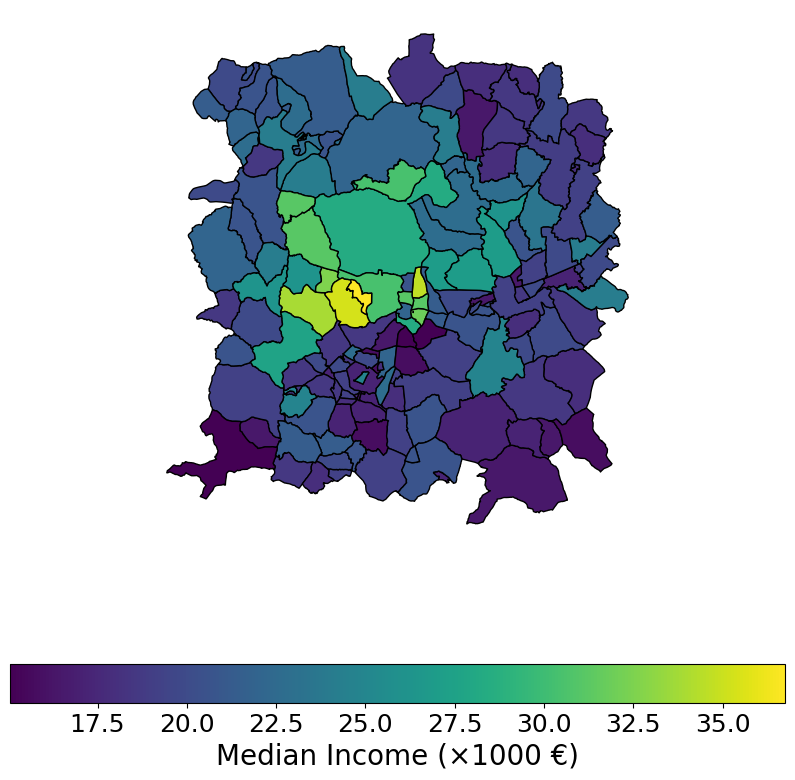

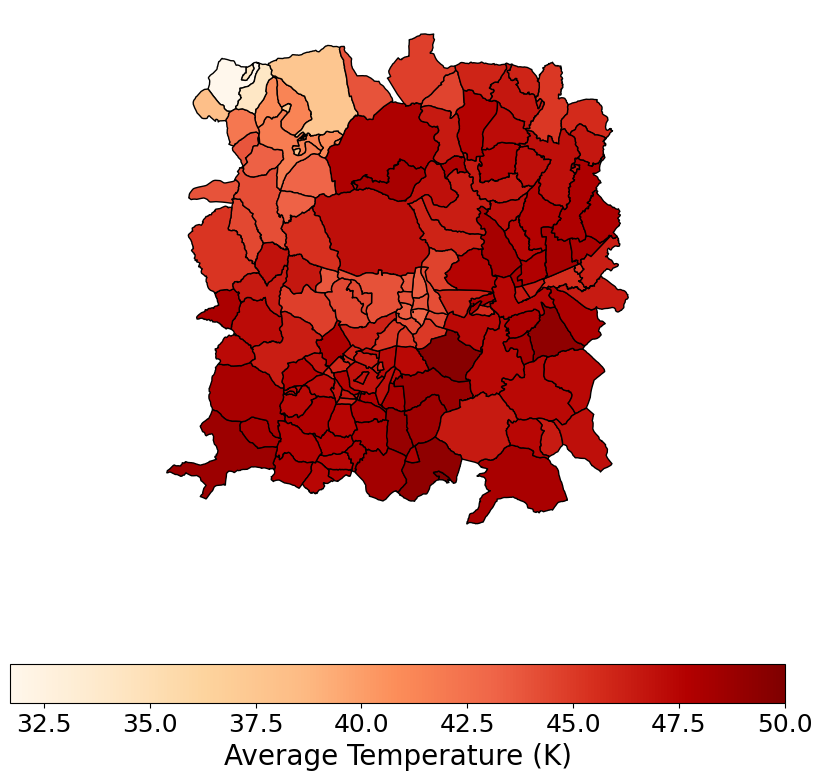

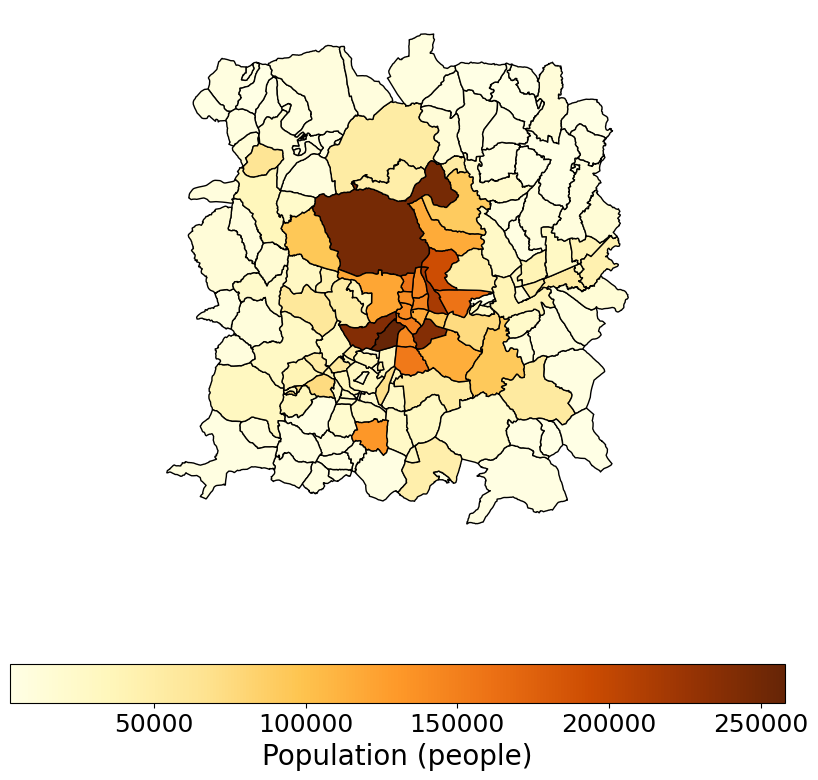

Processing Barcelona…


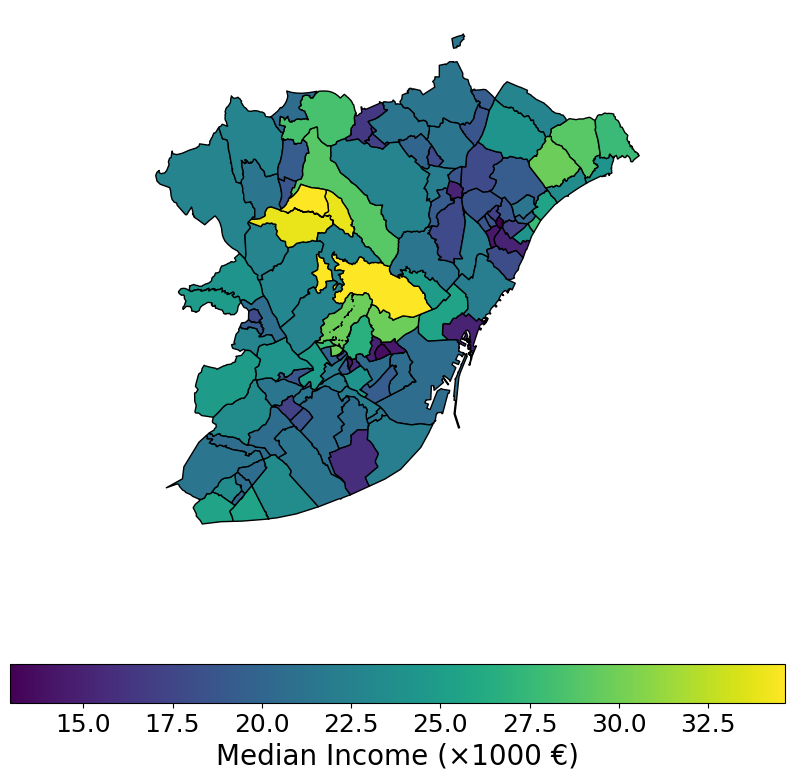

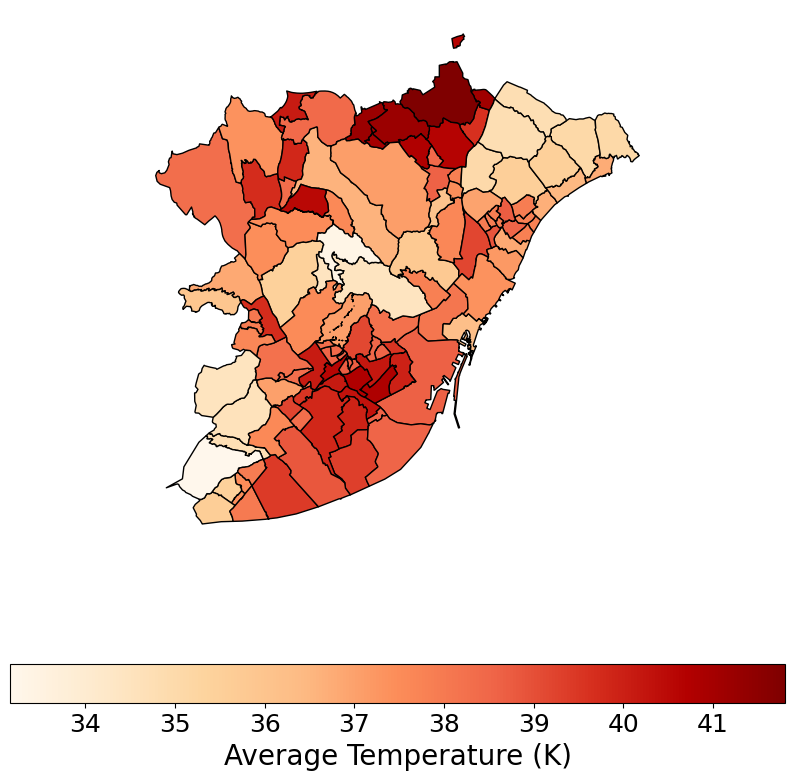

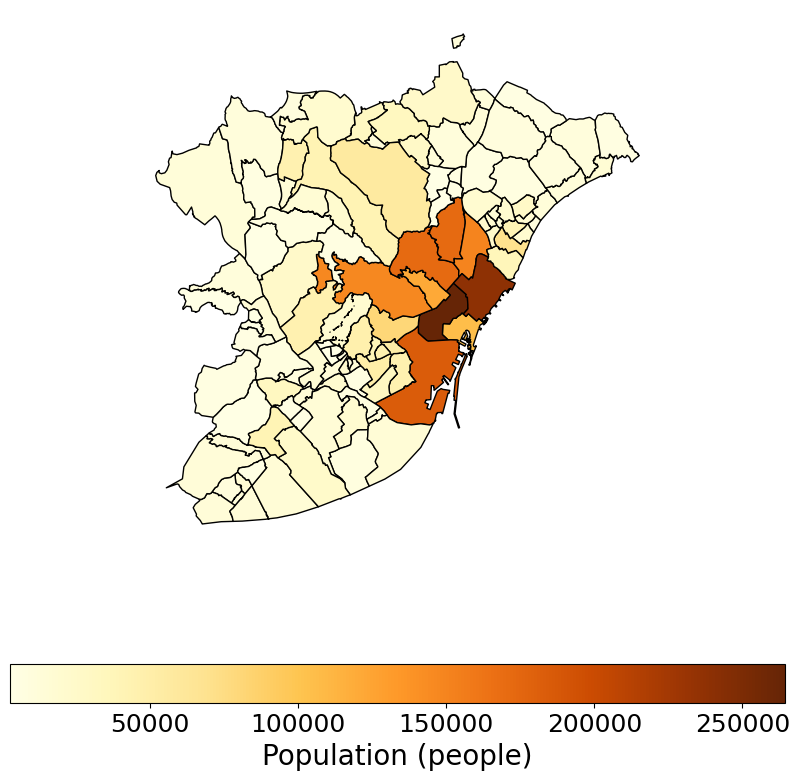

Processing Valencia…


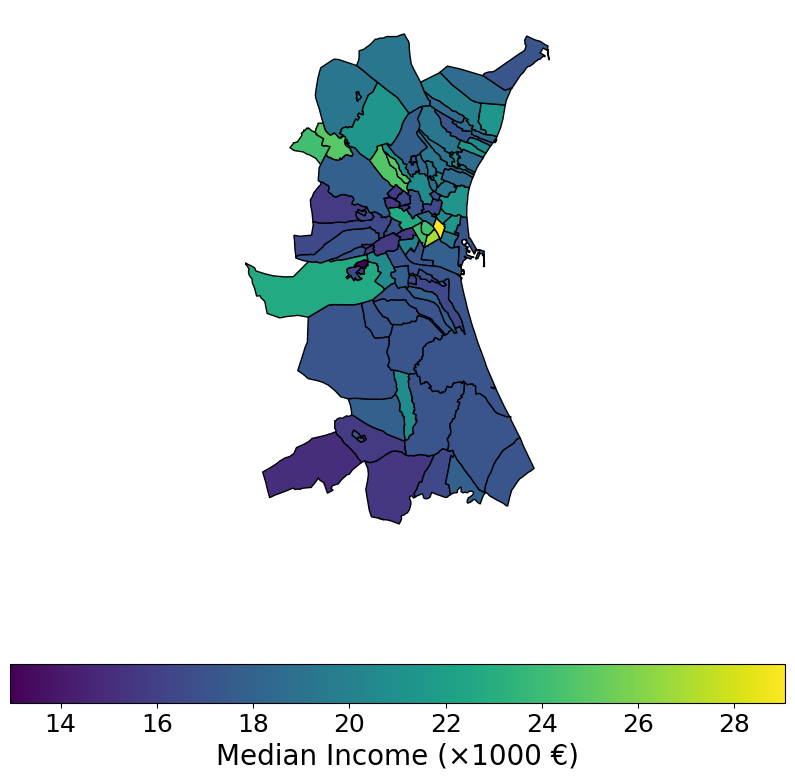

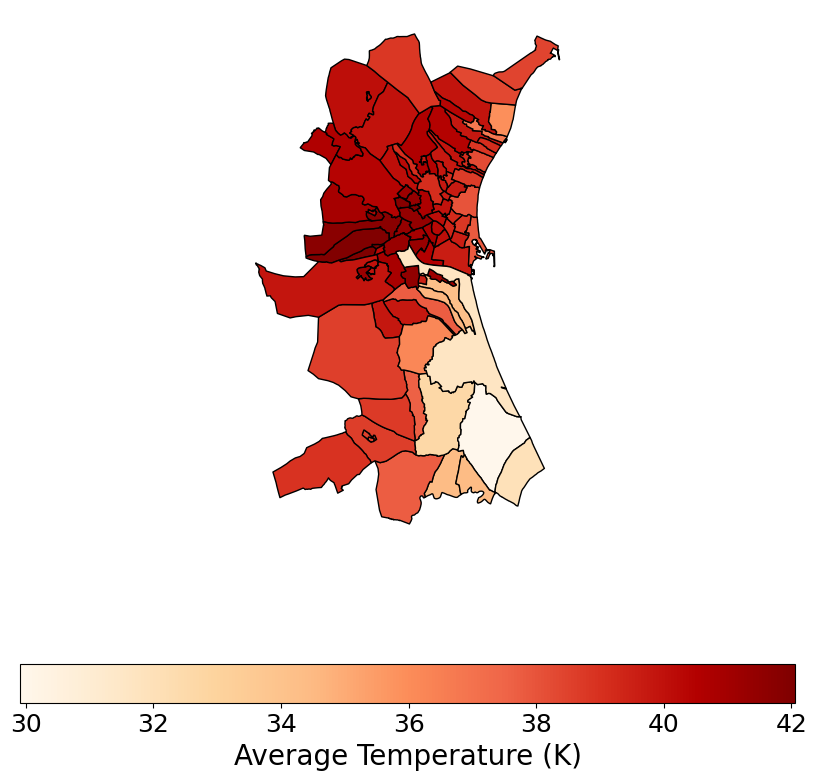

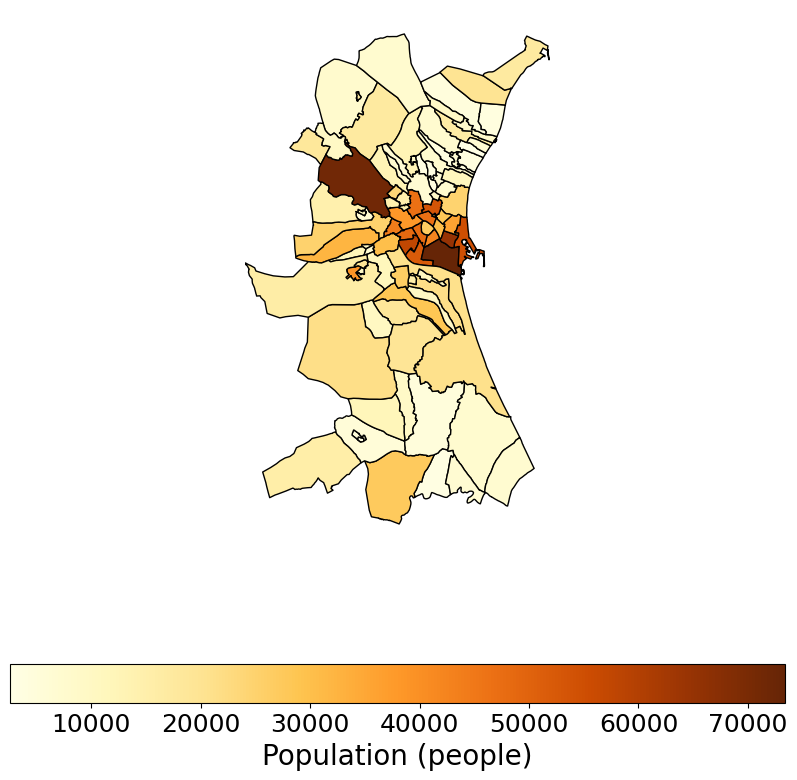

Processing Zaragoza…


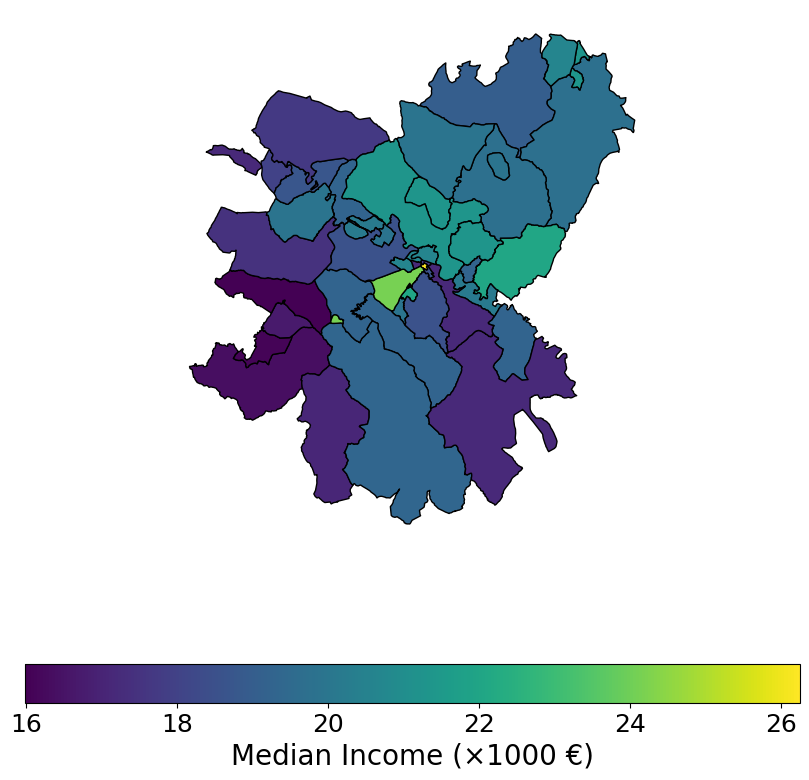

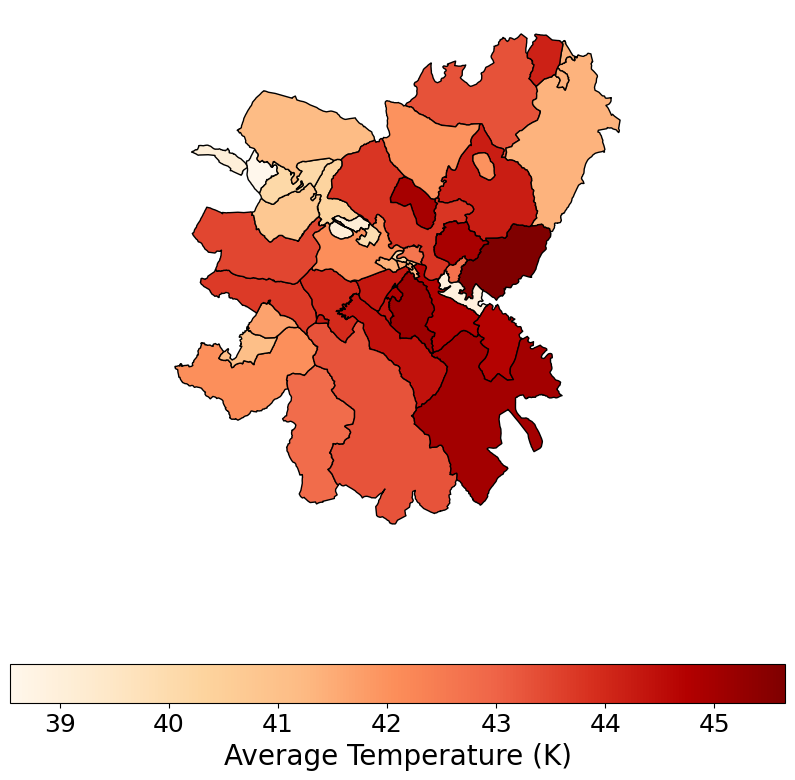

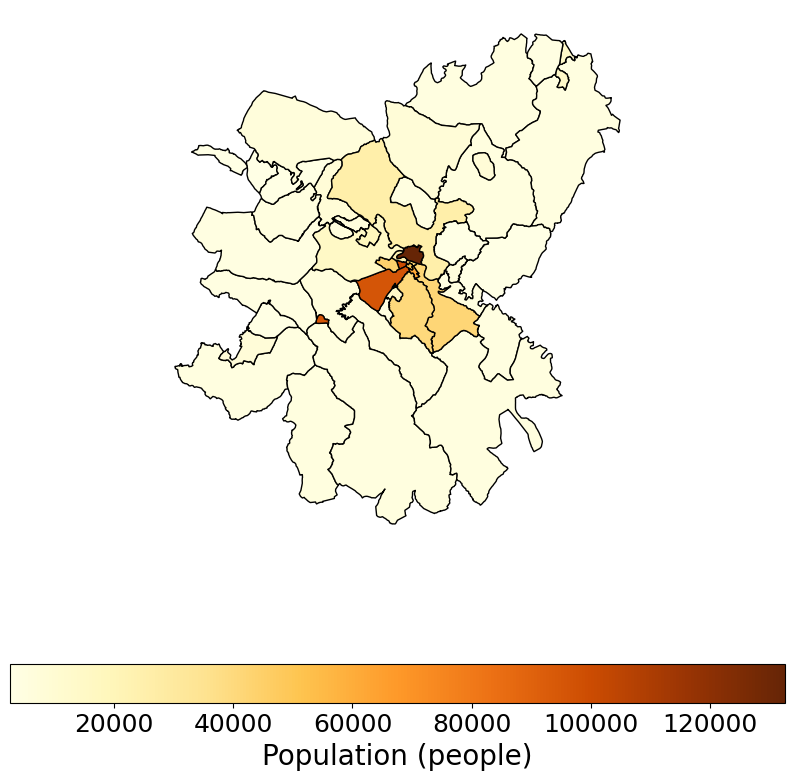

Processing Sevilla…


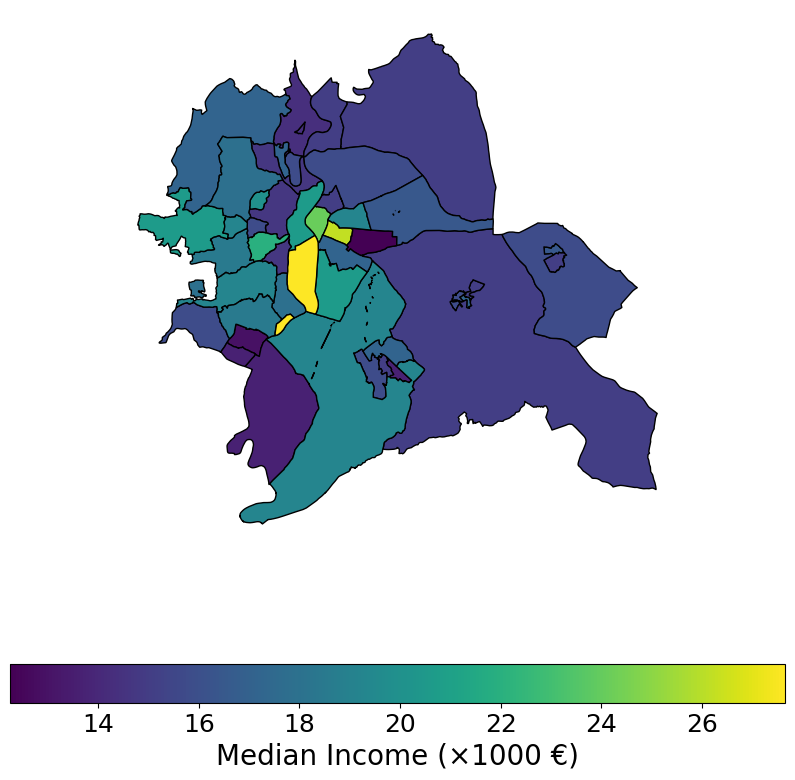

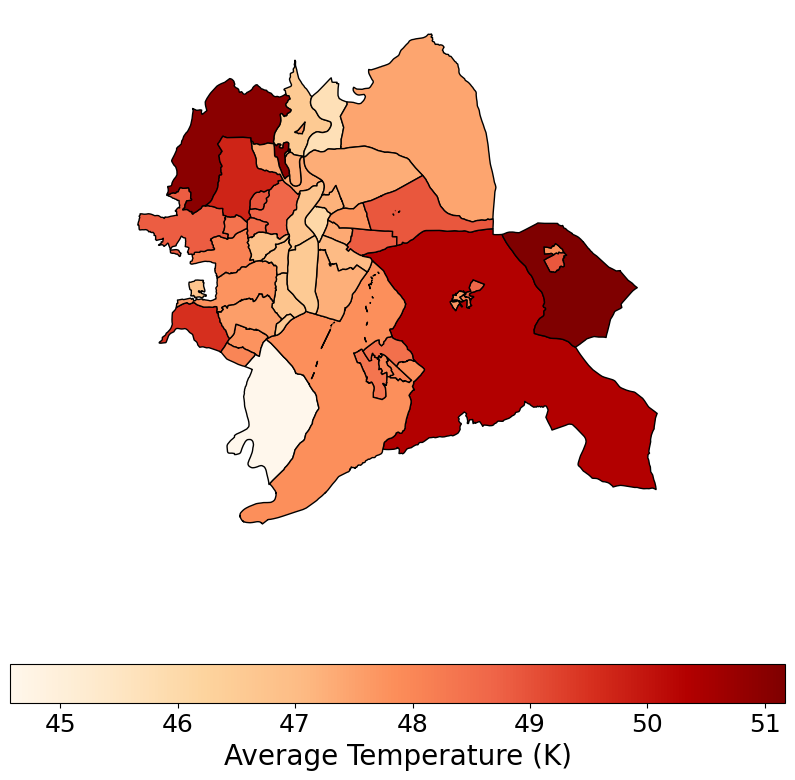

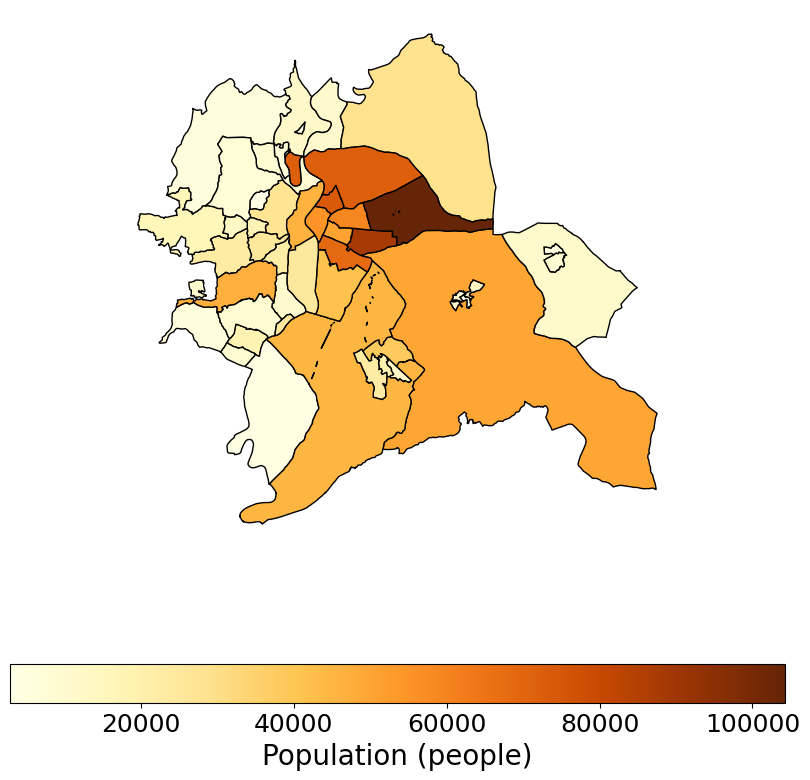

Processing Malaga…


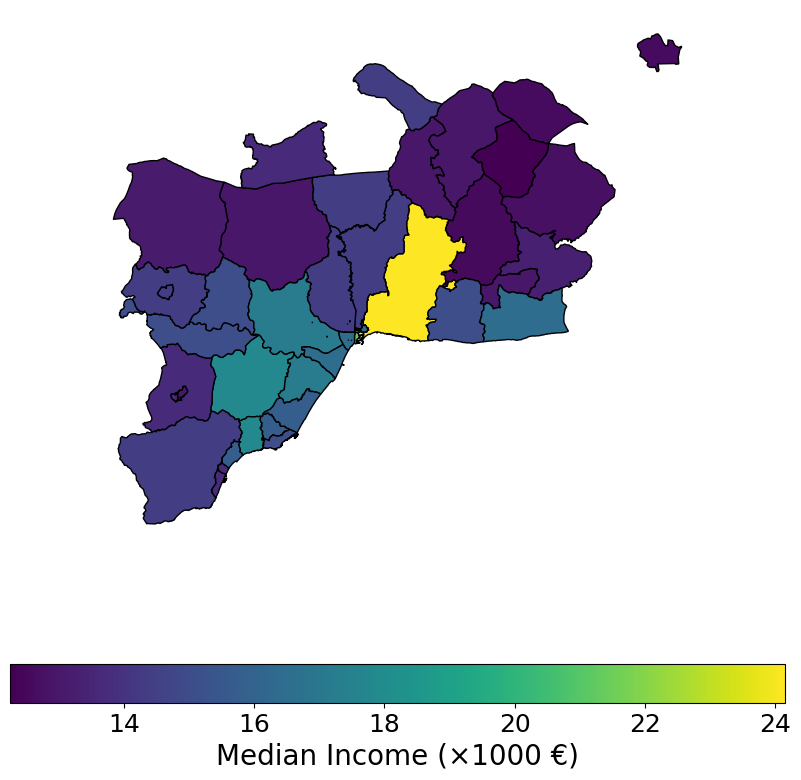

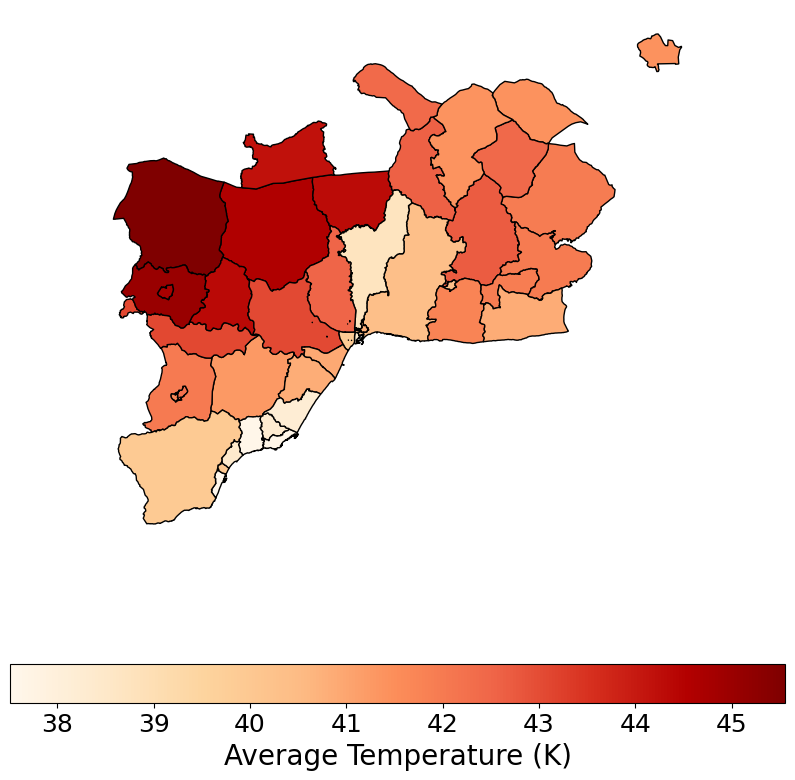

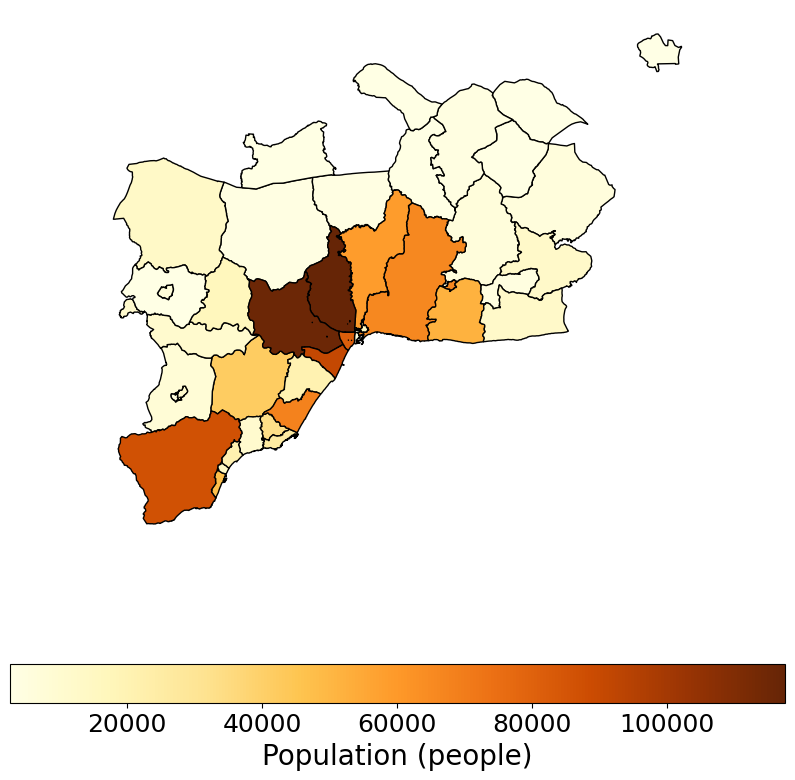

Processing Murcia…


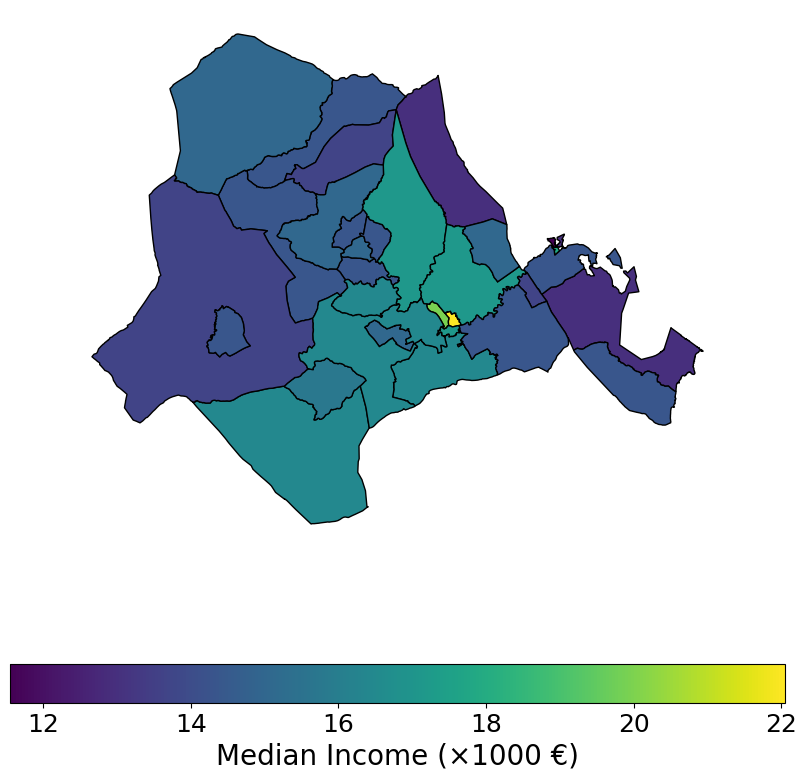

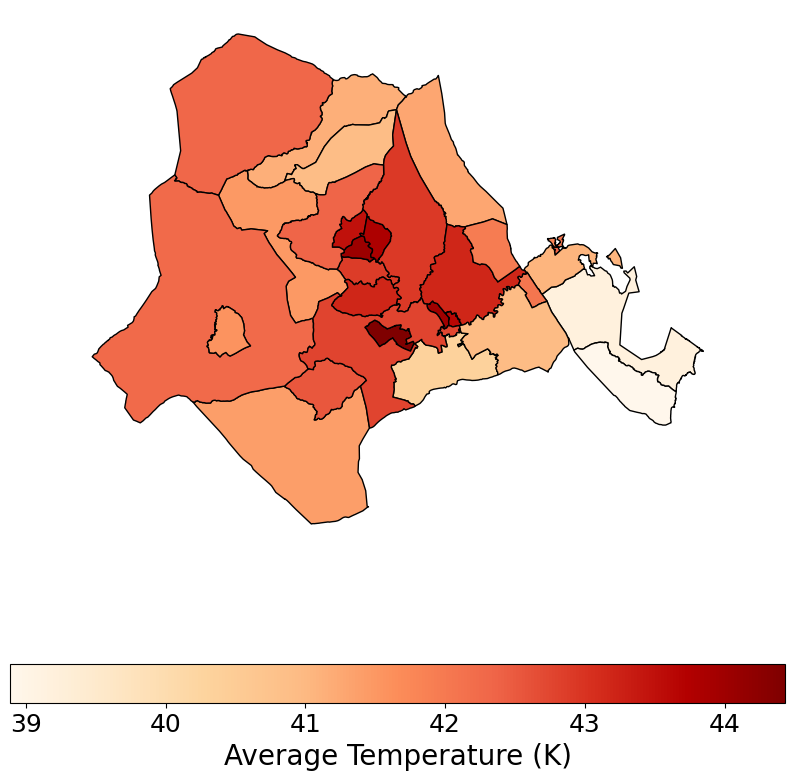

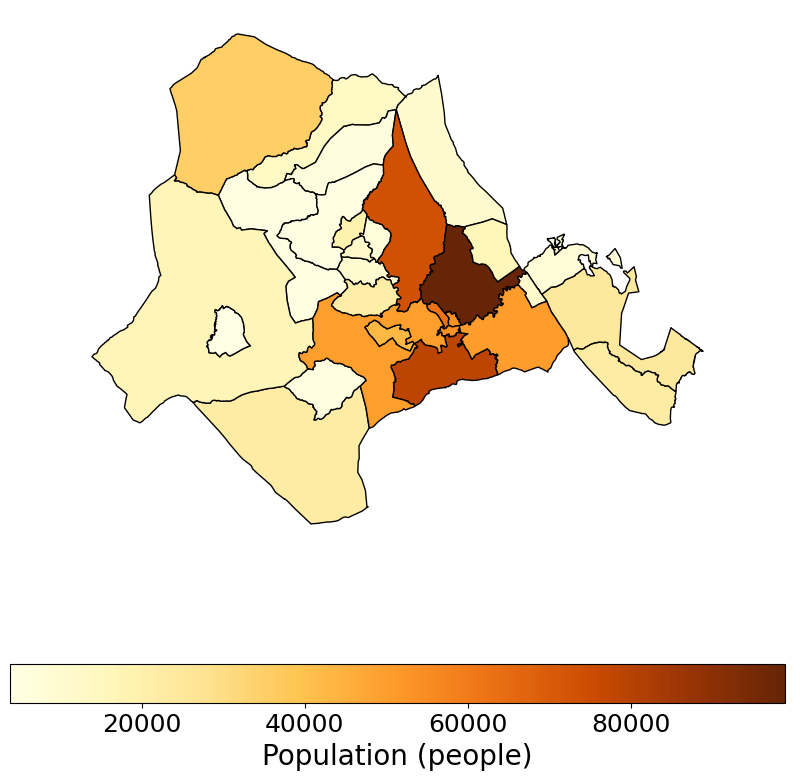

Processing Palma_de_Mallorca…


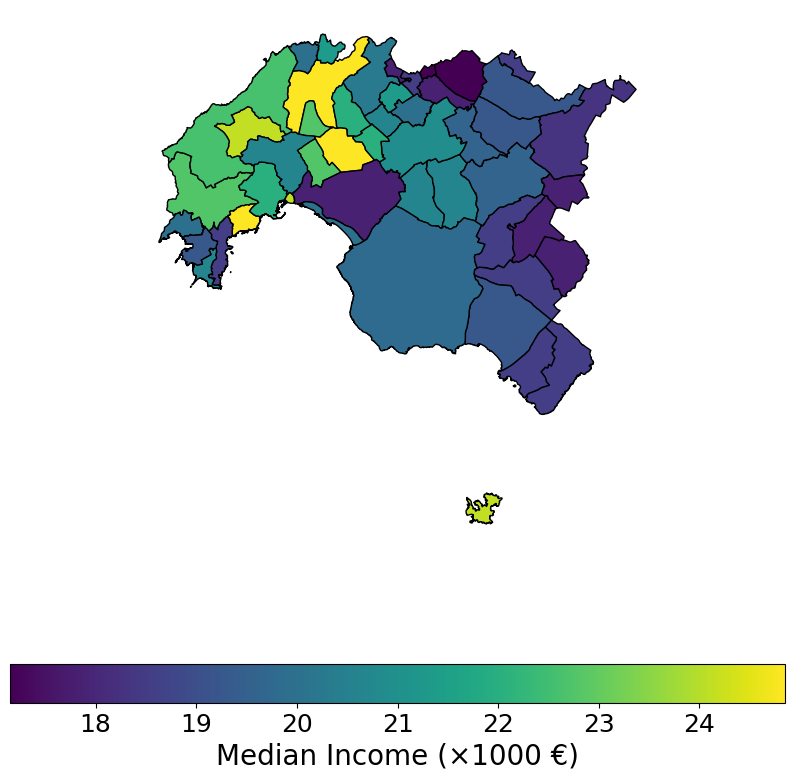

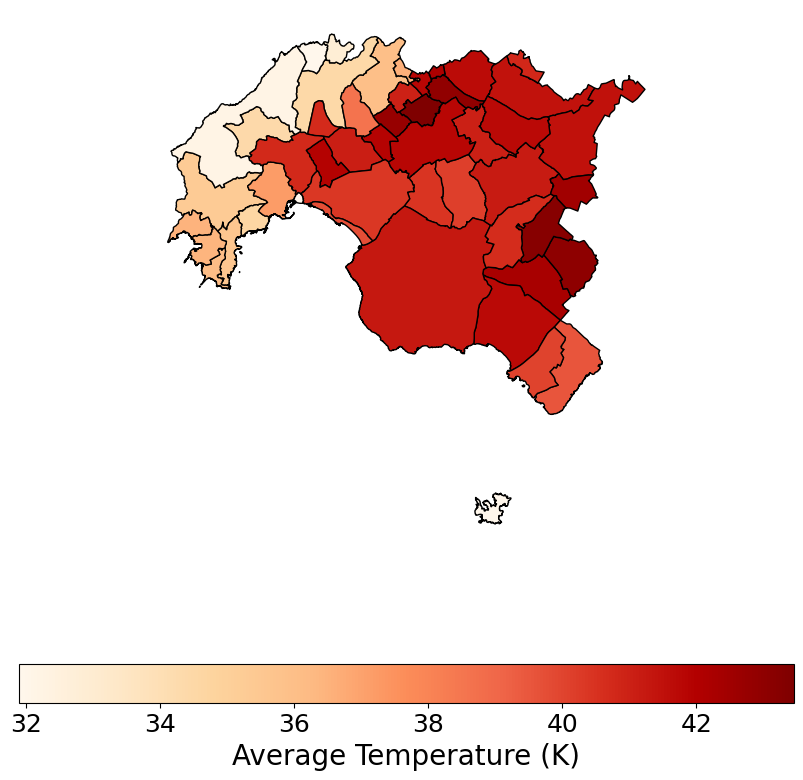

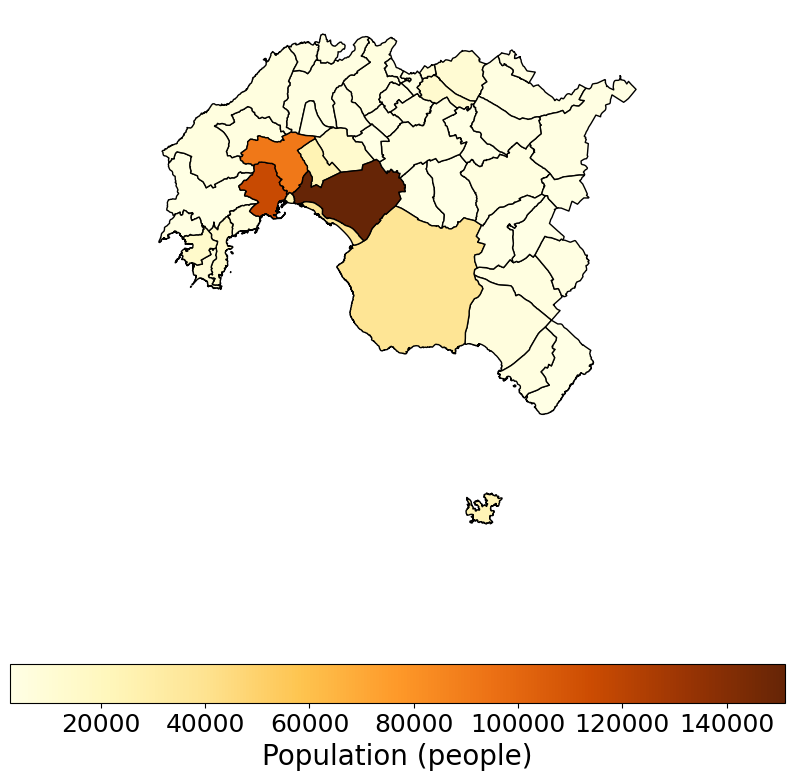

Processing Las_Palmas…


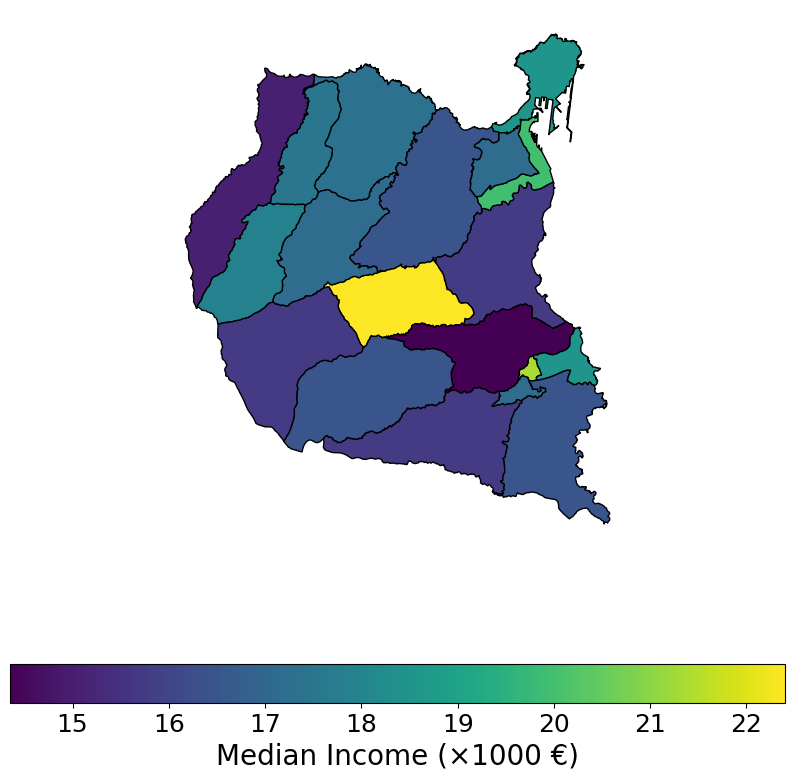

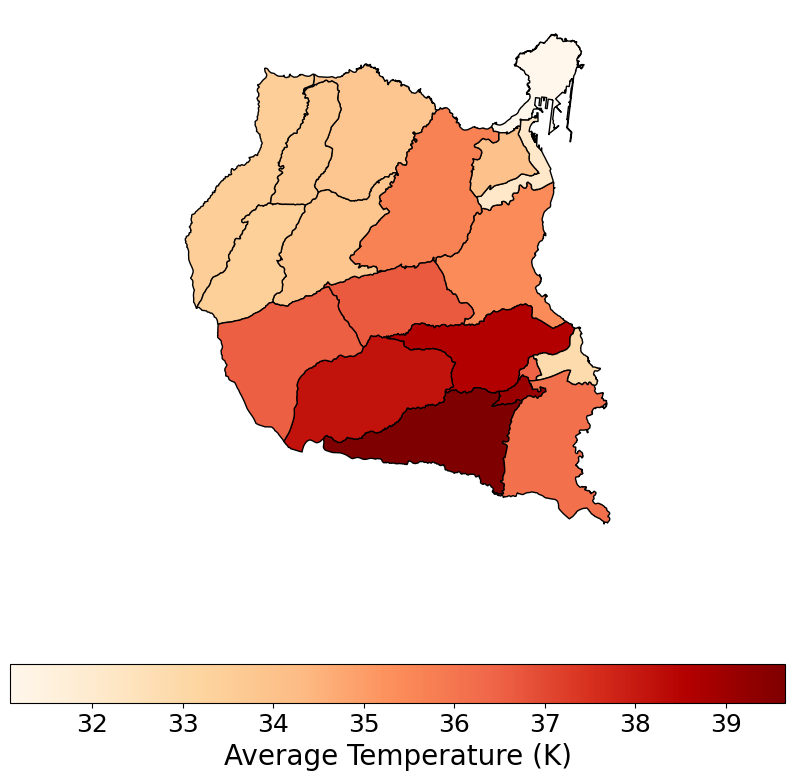

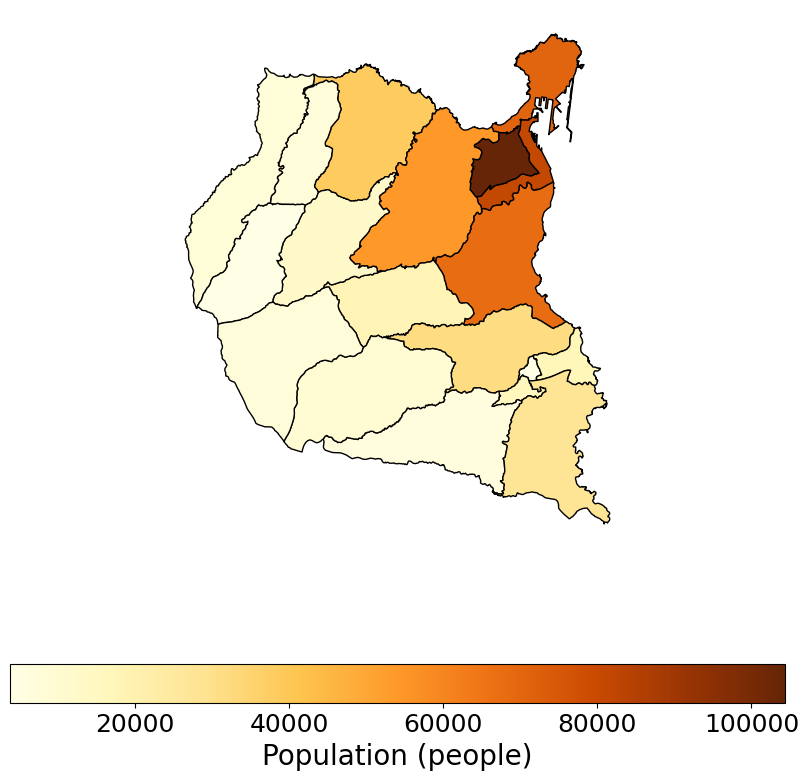

Processing Alicante…


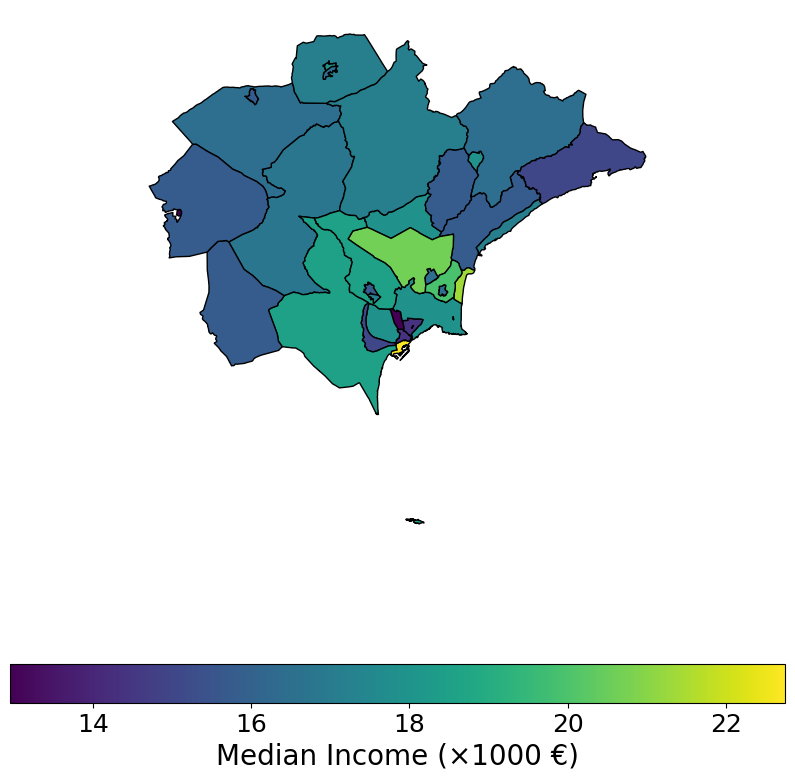

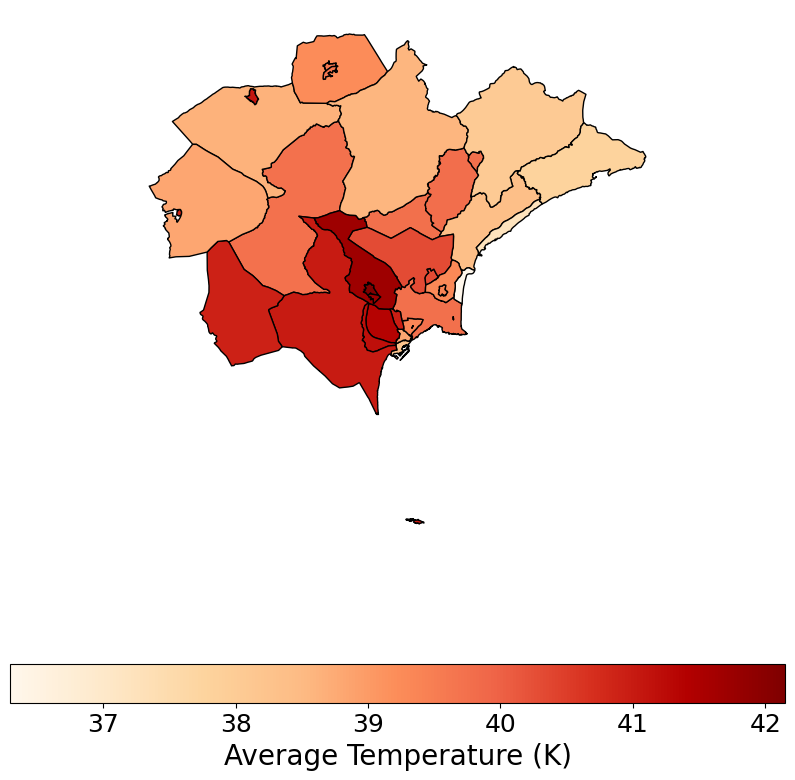

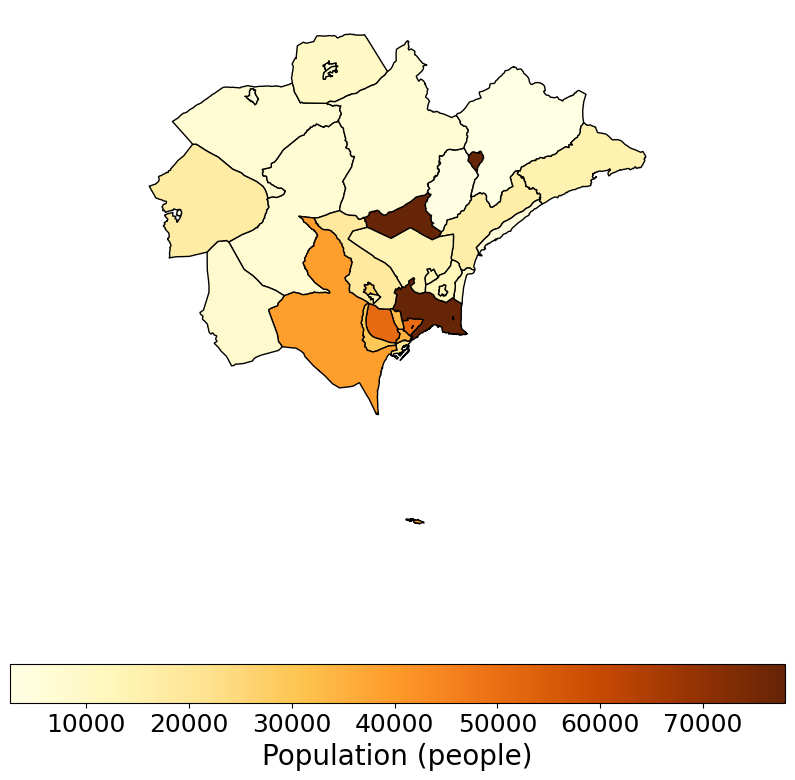

Processing Bilbao…


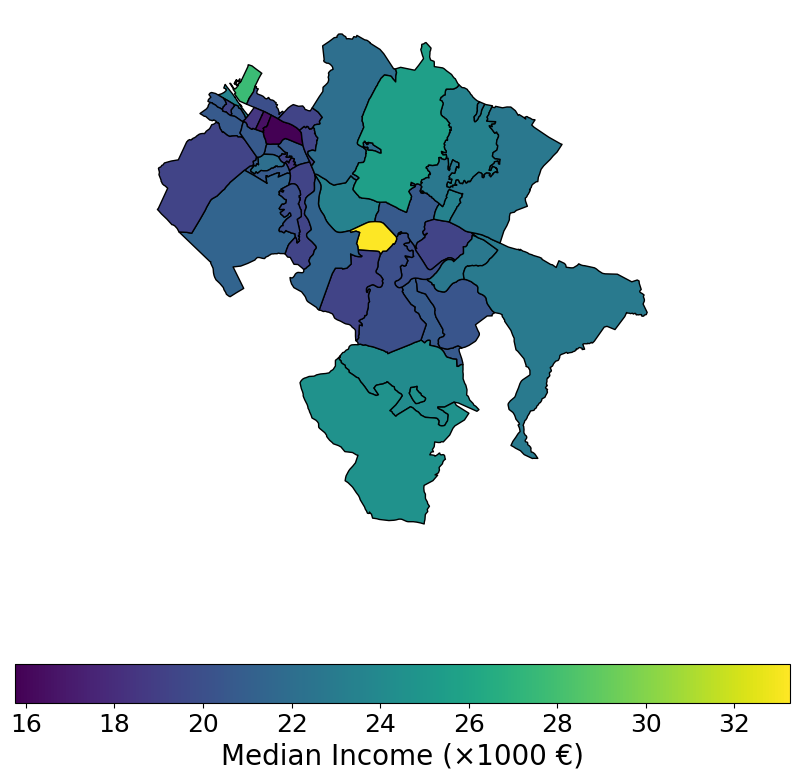

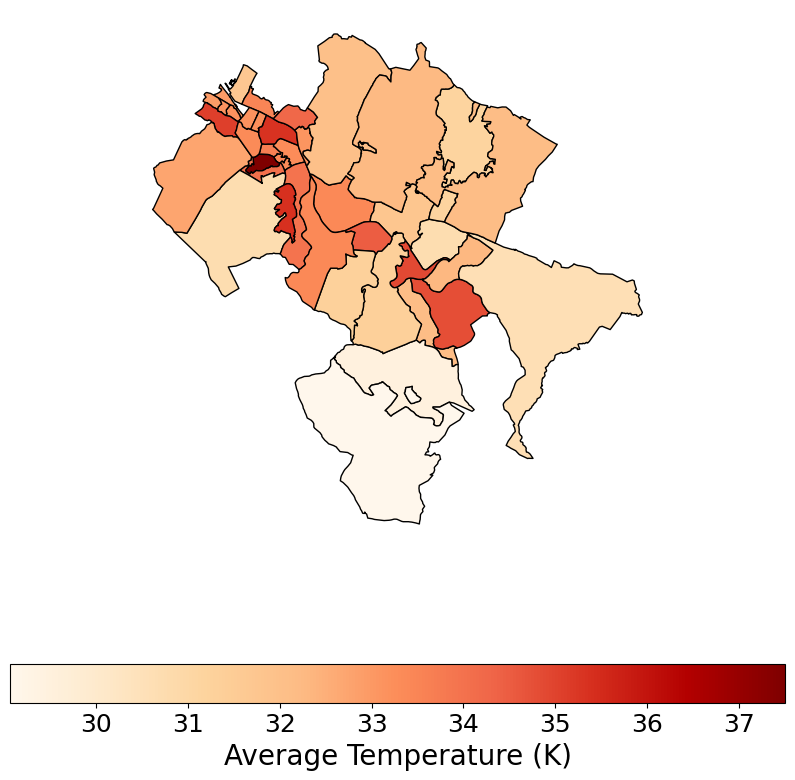

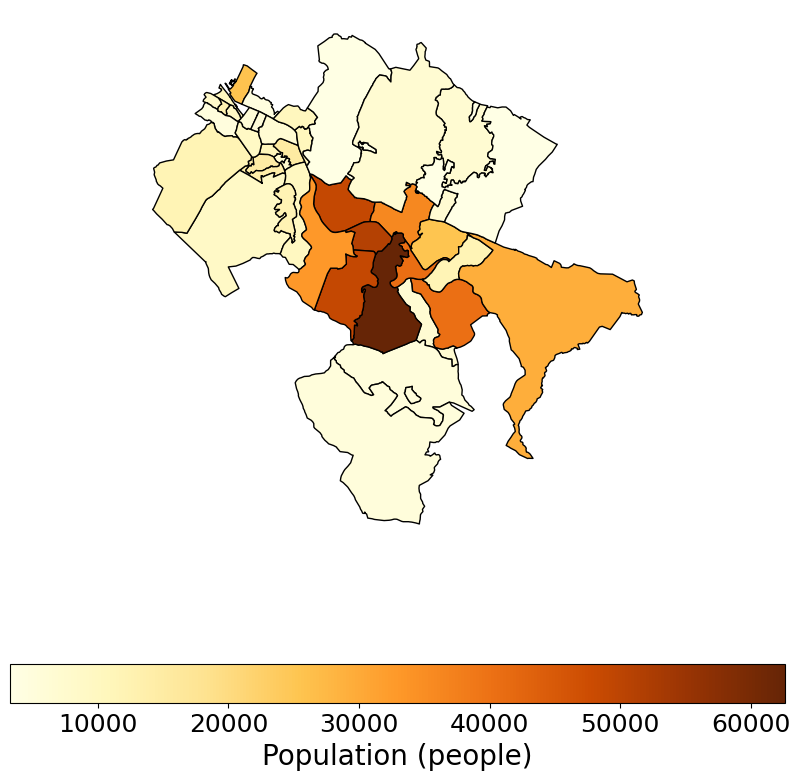

Processing Valladolid…


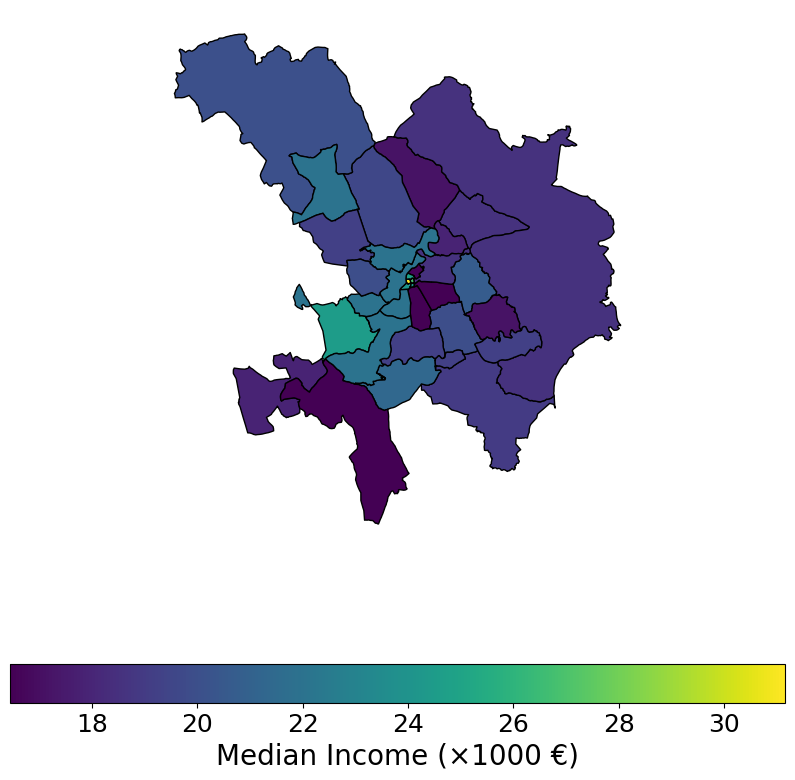

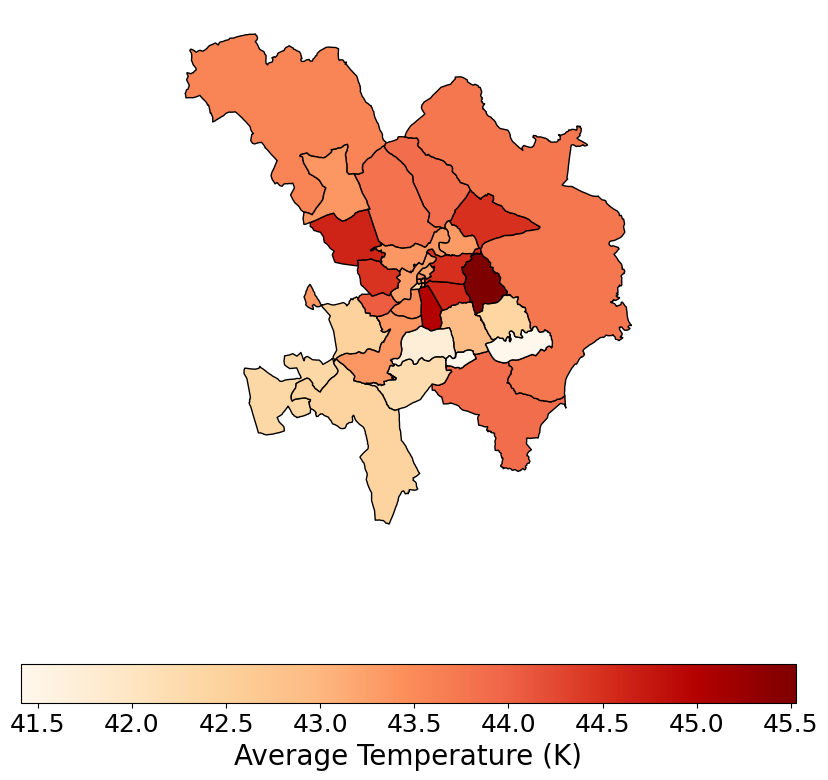

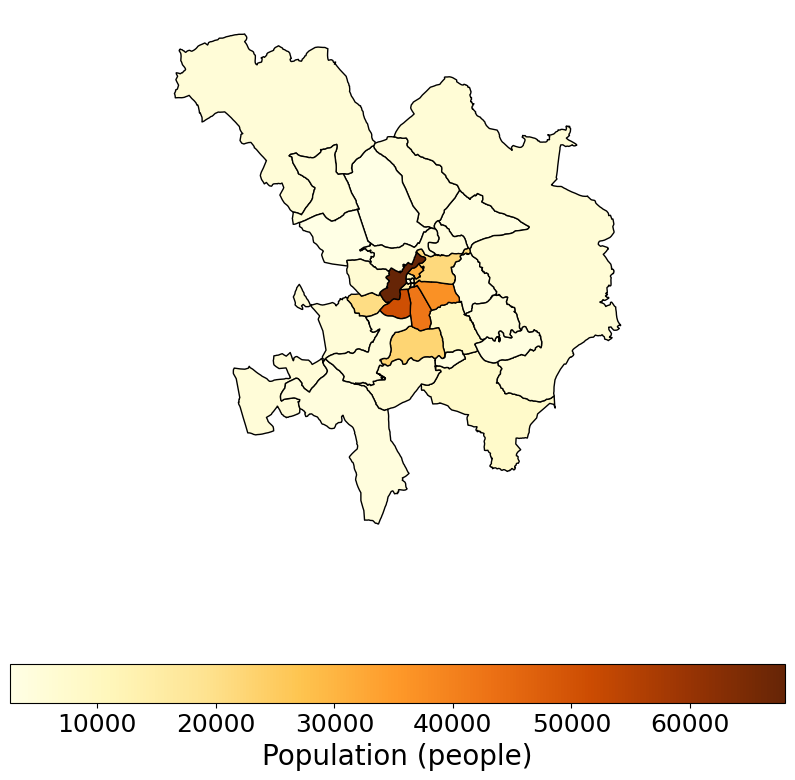

Processing Cordoba…


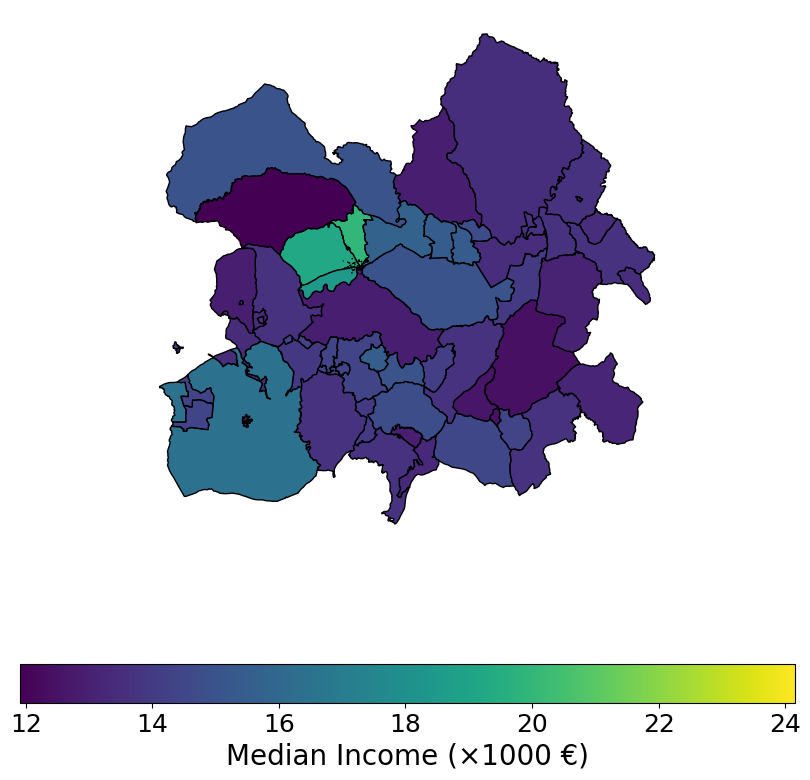

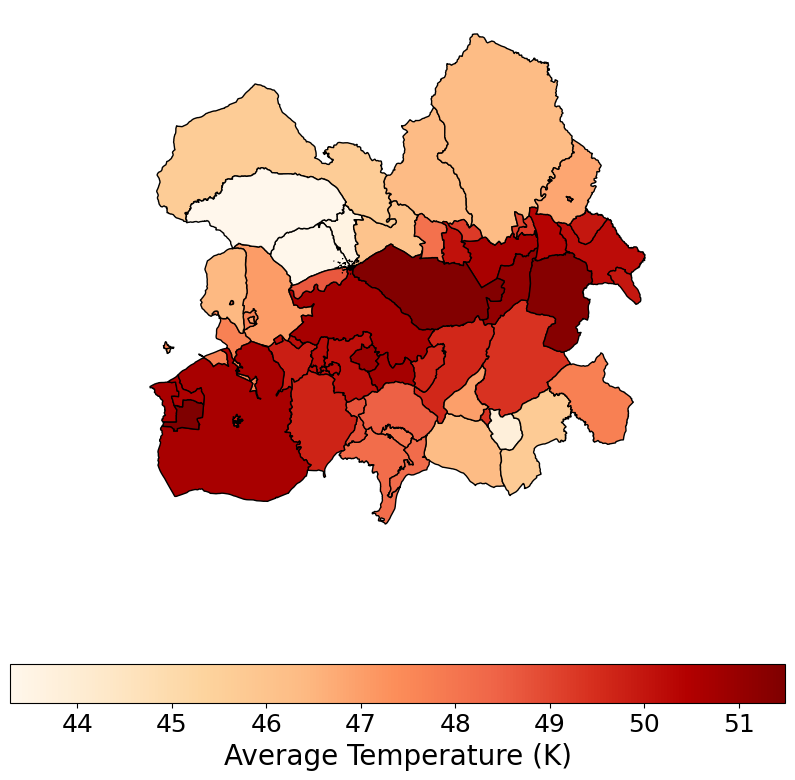

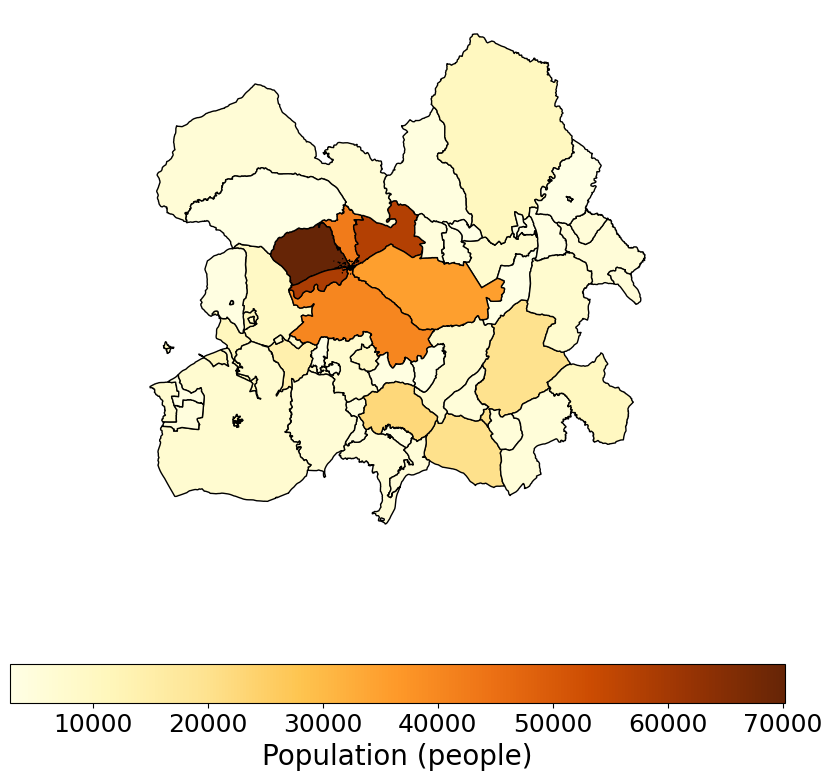

Processing Vigo…


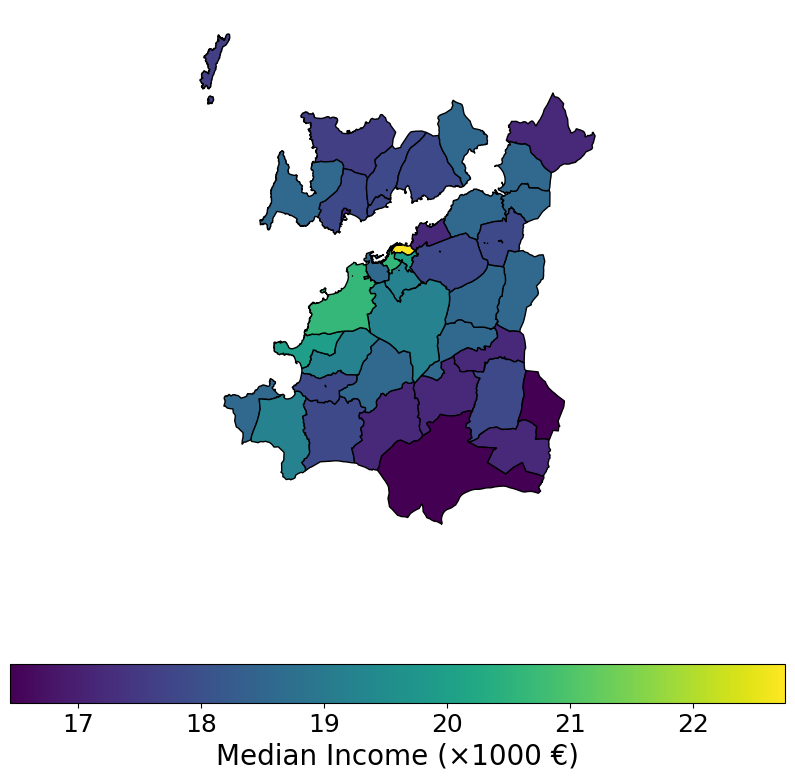

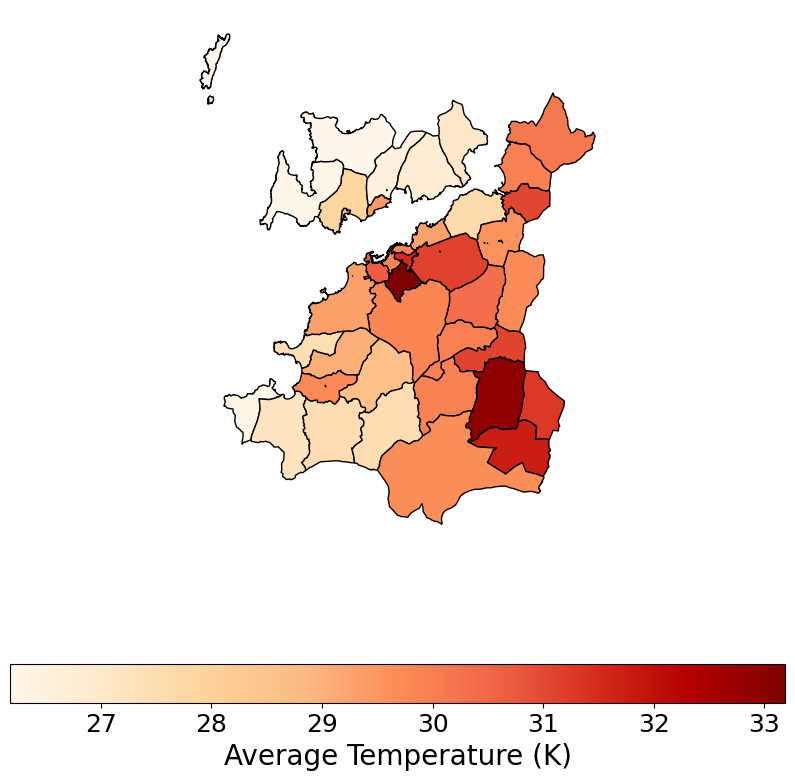

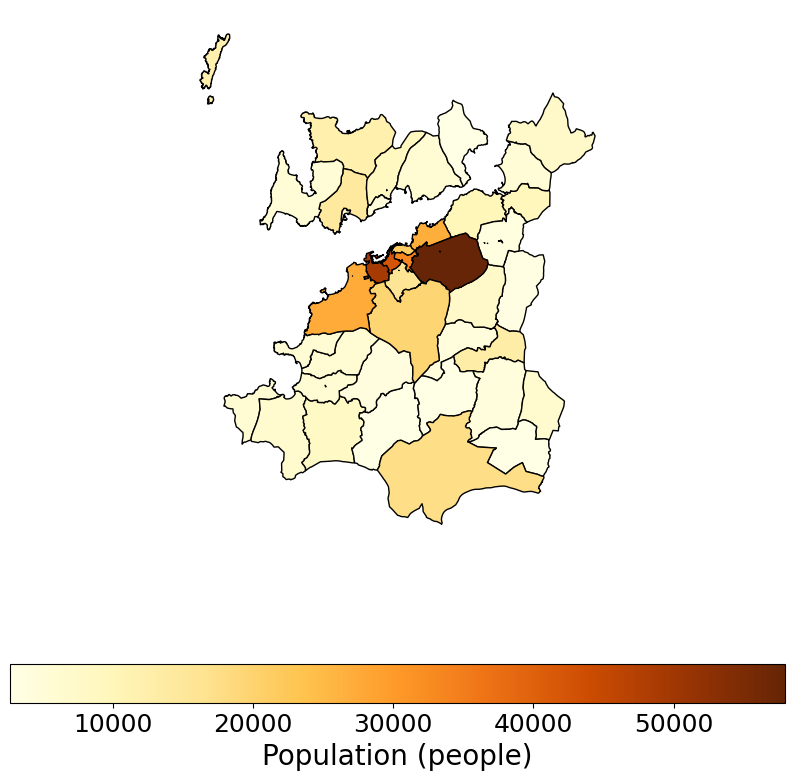

Processing Gijon…


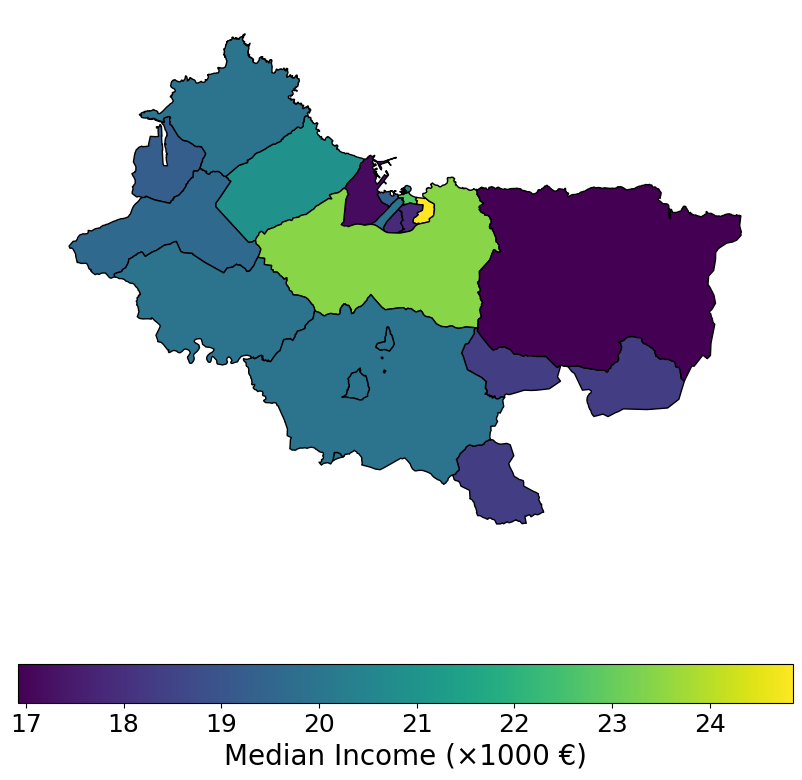

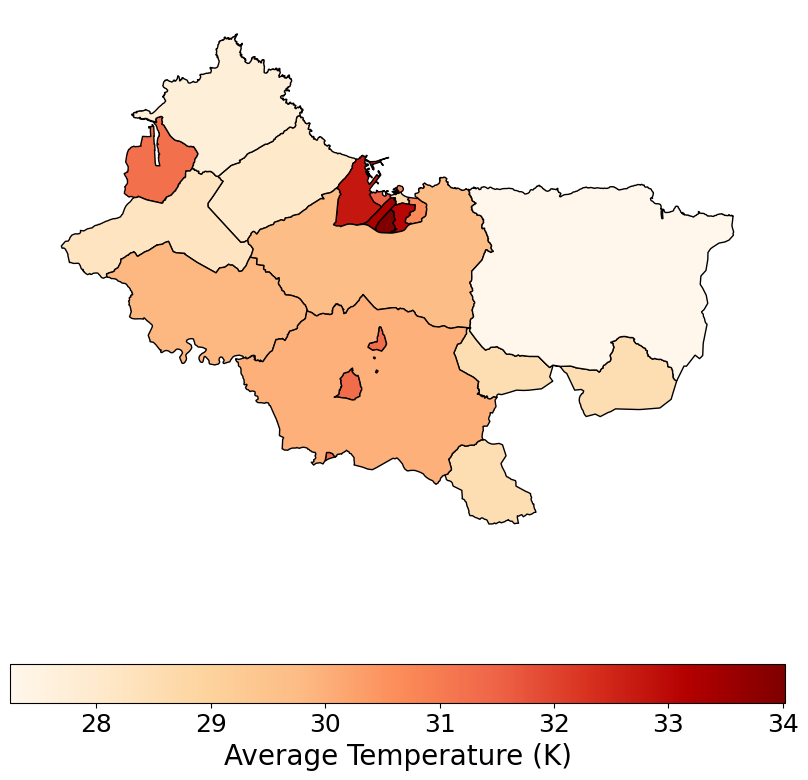

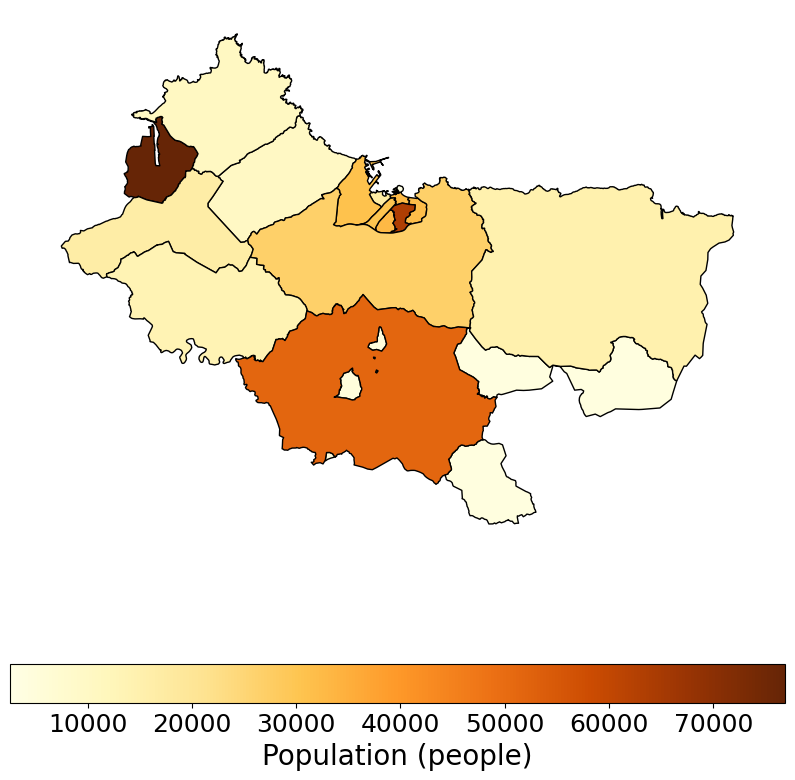

Processing Vitoria_Gasteiz…


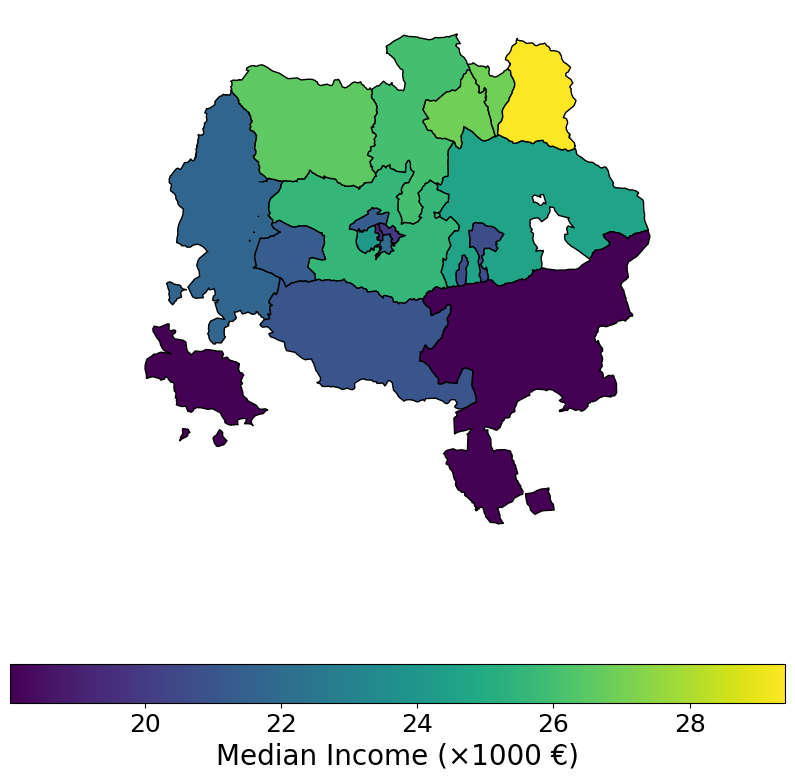

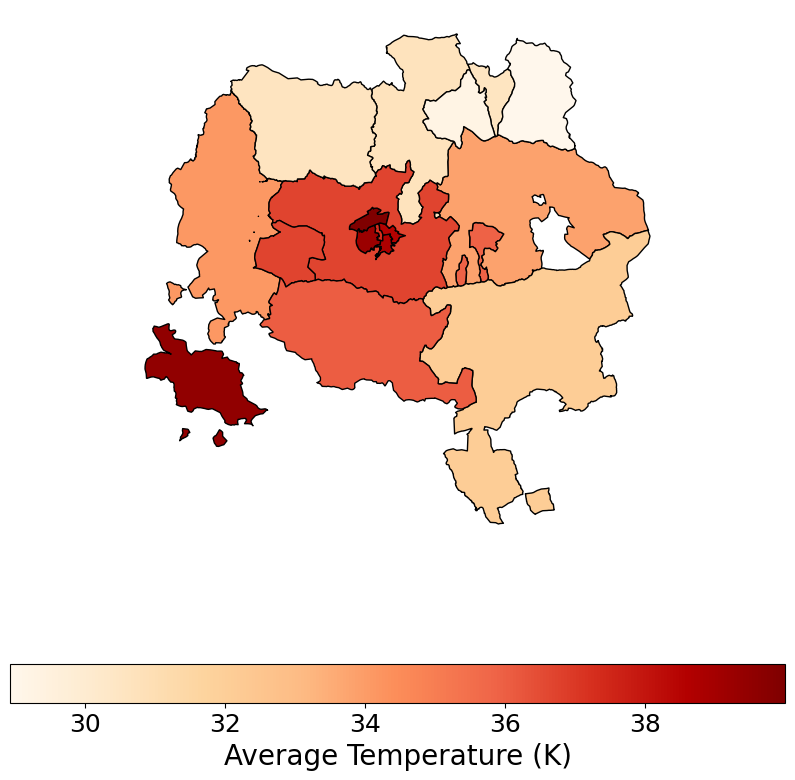

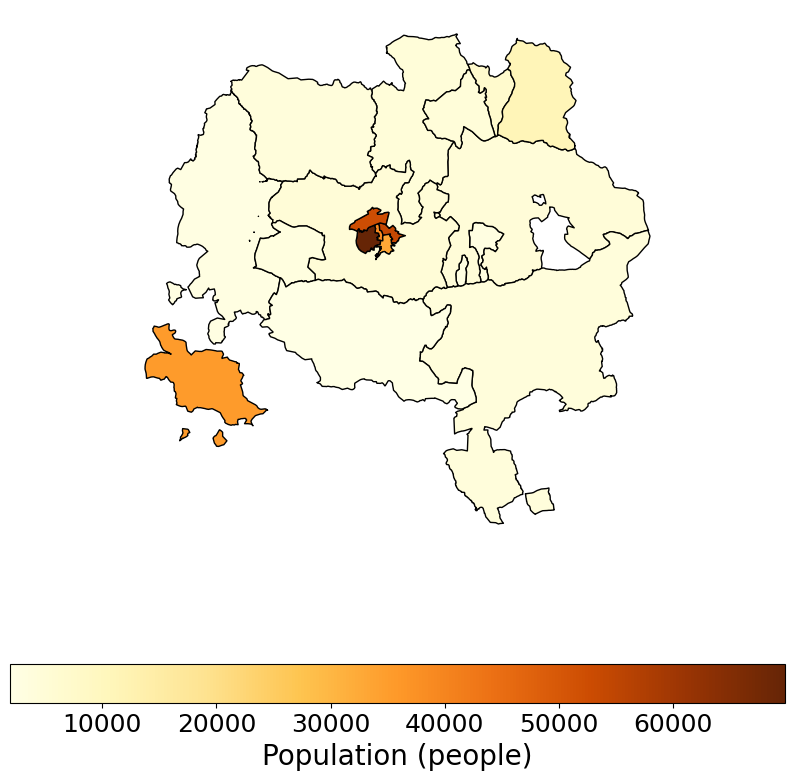

Processing A_Coruna…


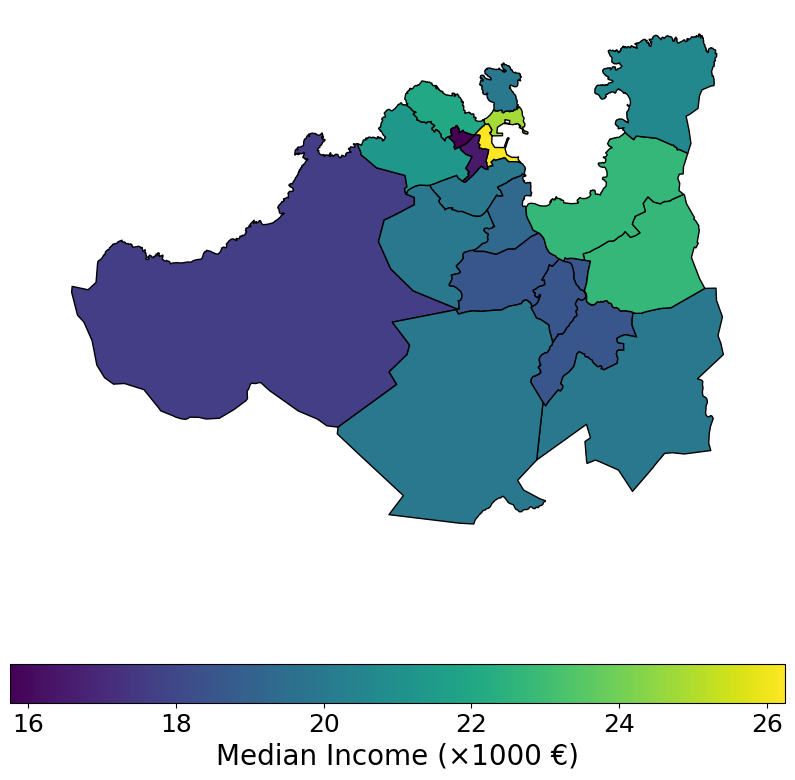

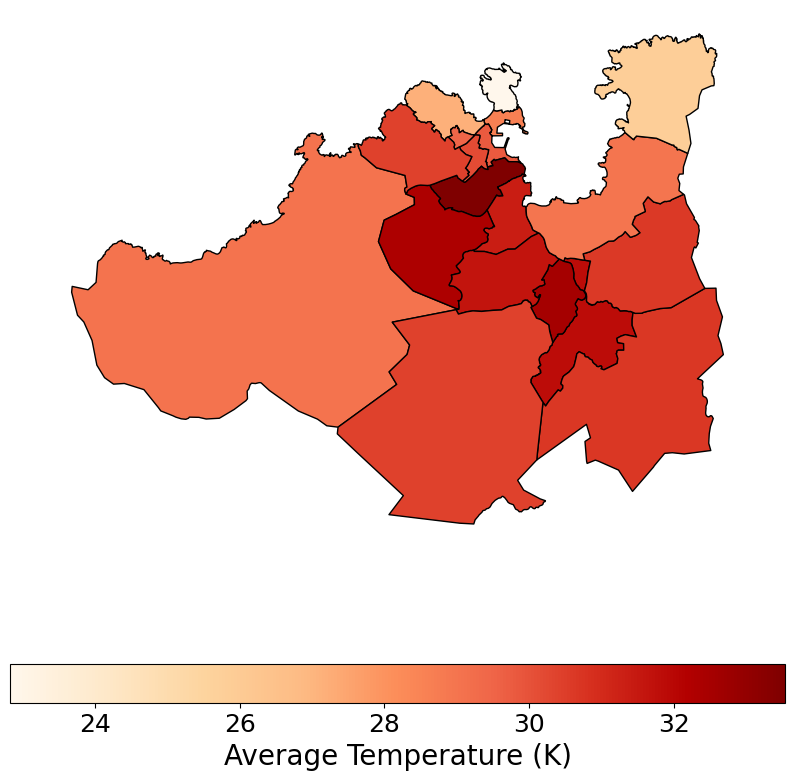

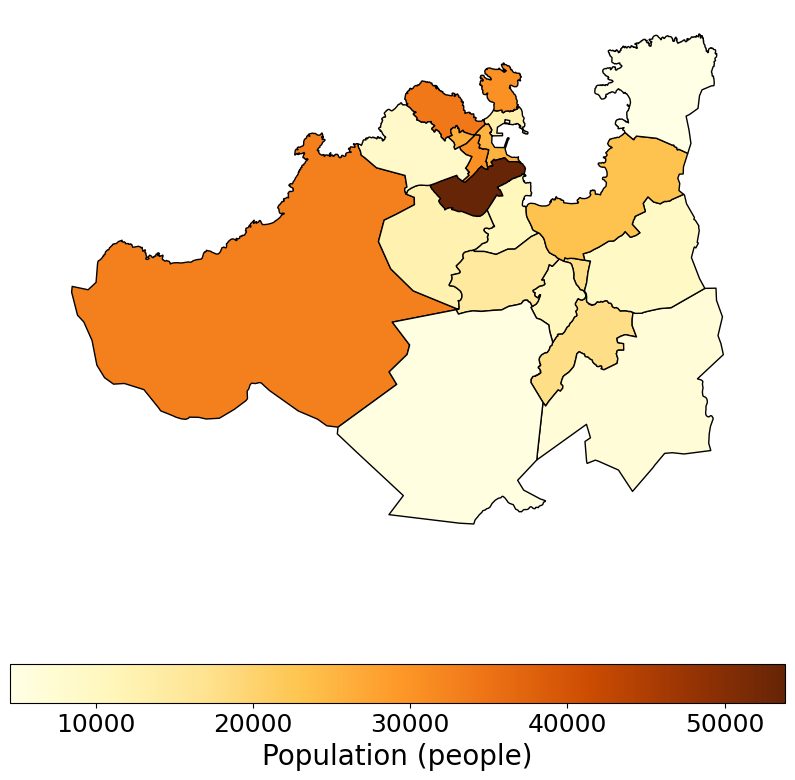

Processing Granada…


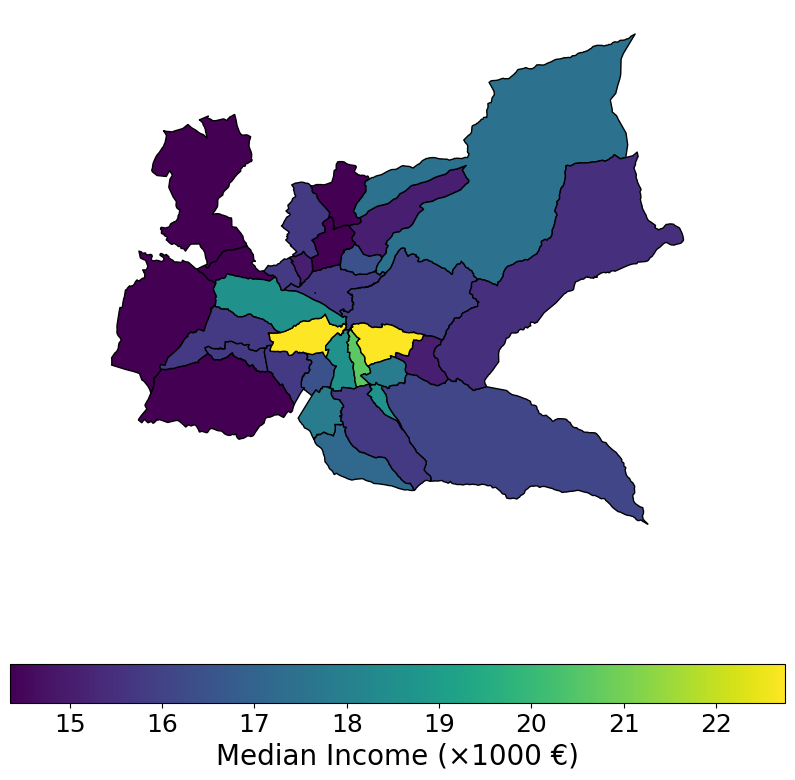

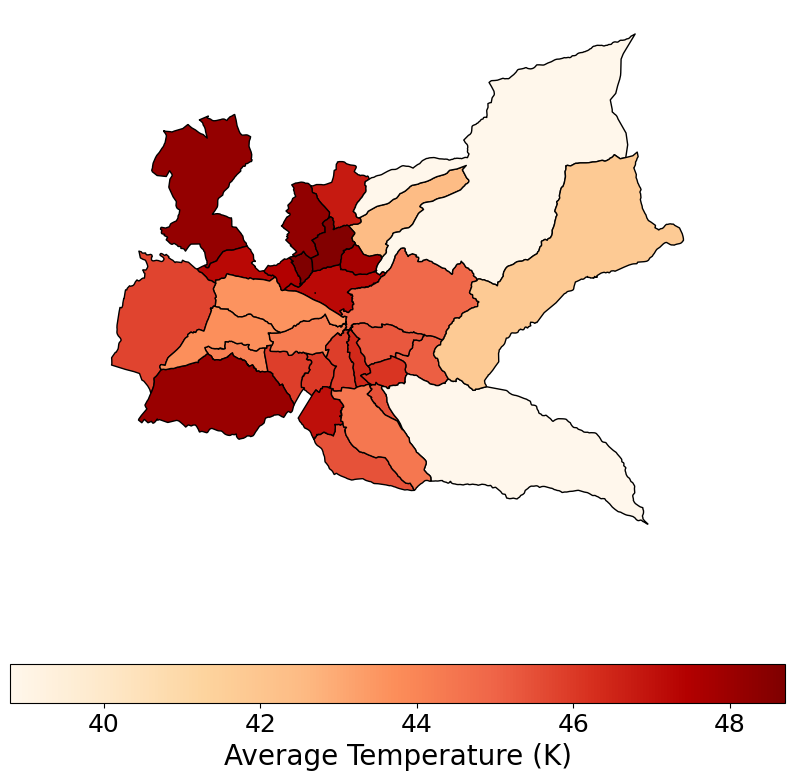

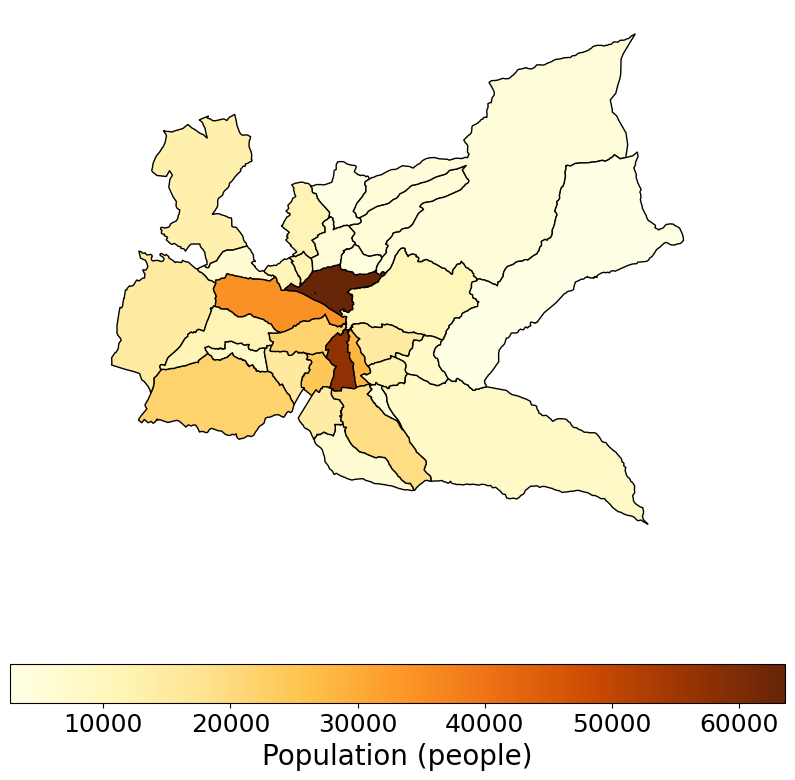

Processing Elche…


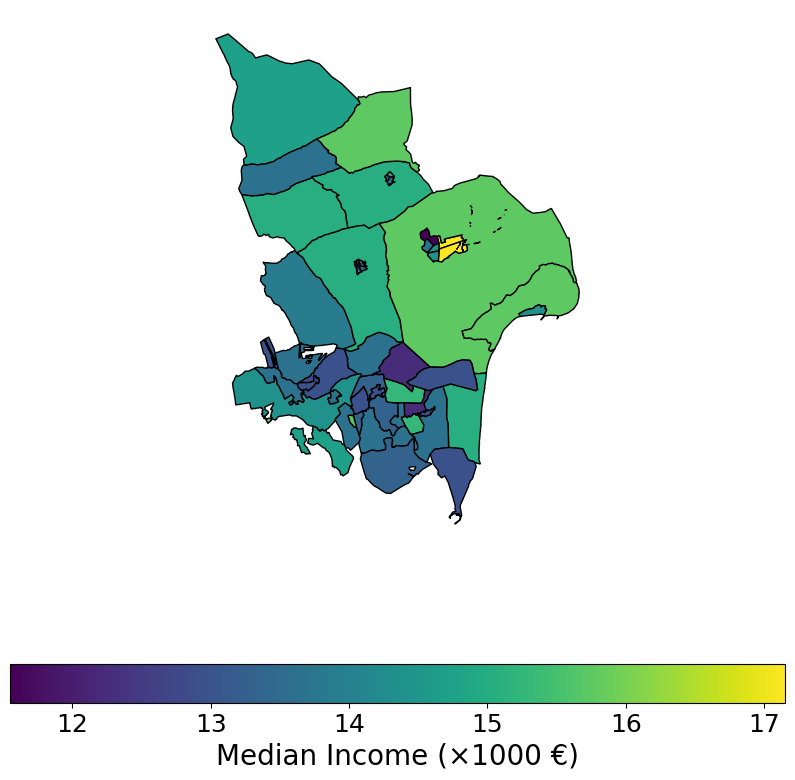

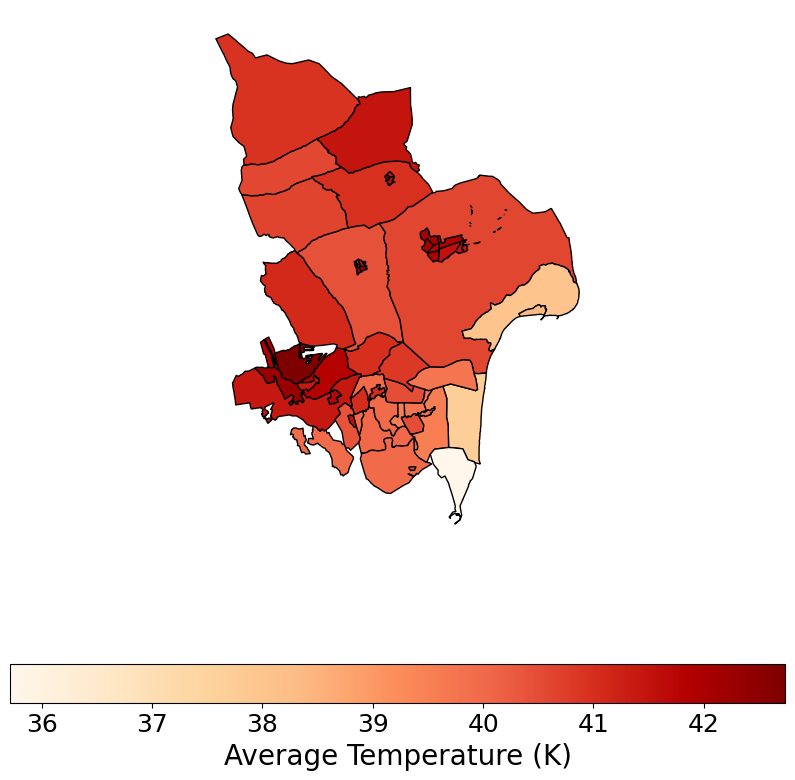

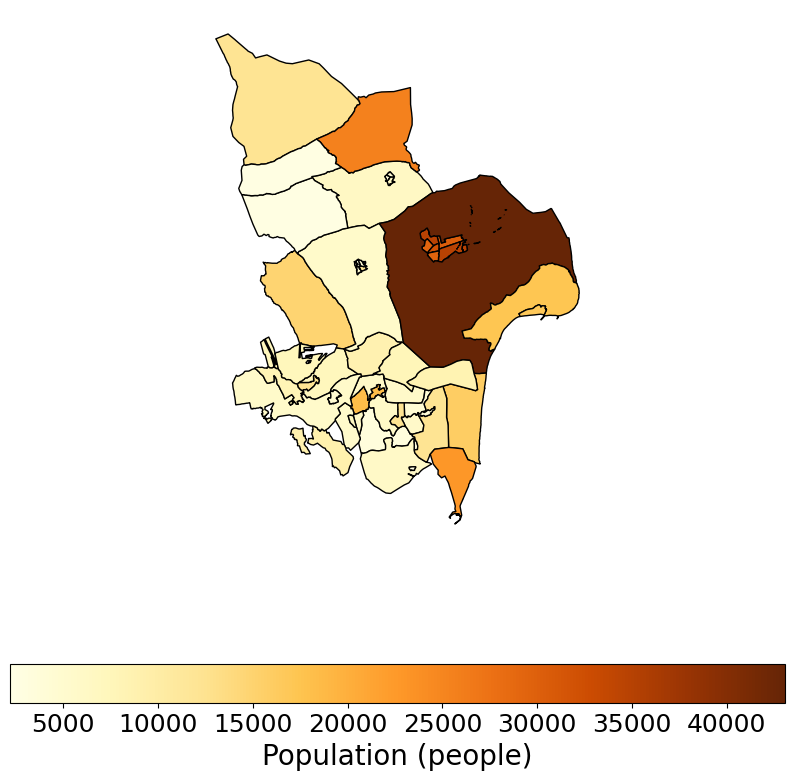

Processing Cartagena…


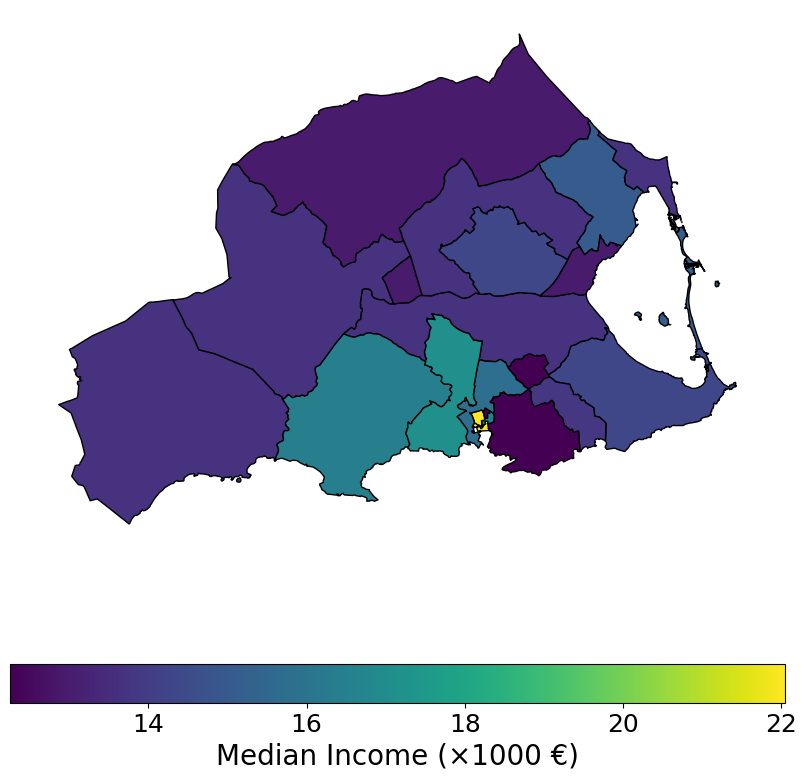

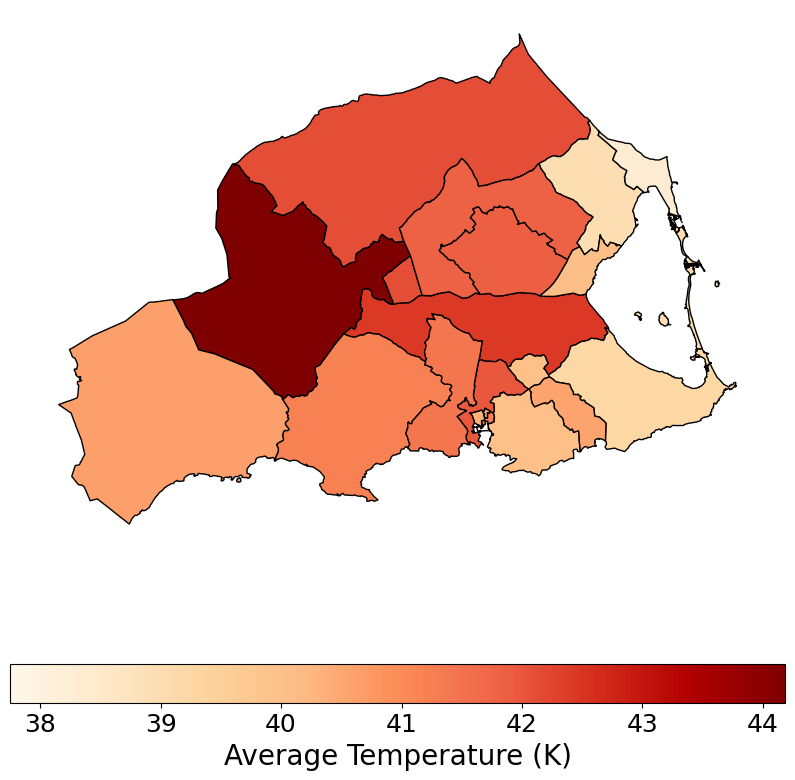

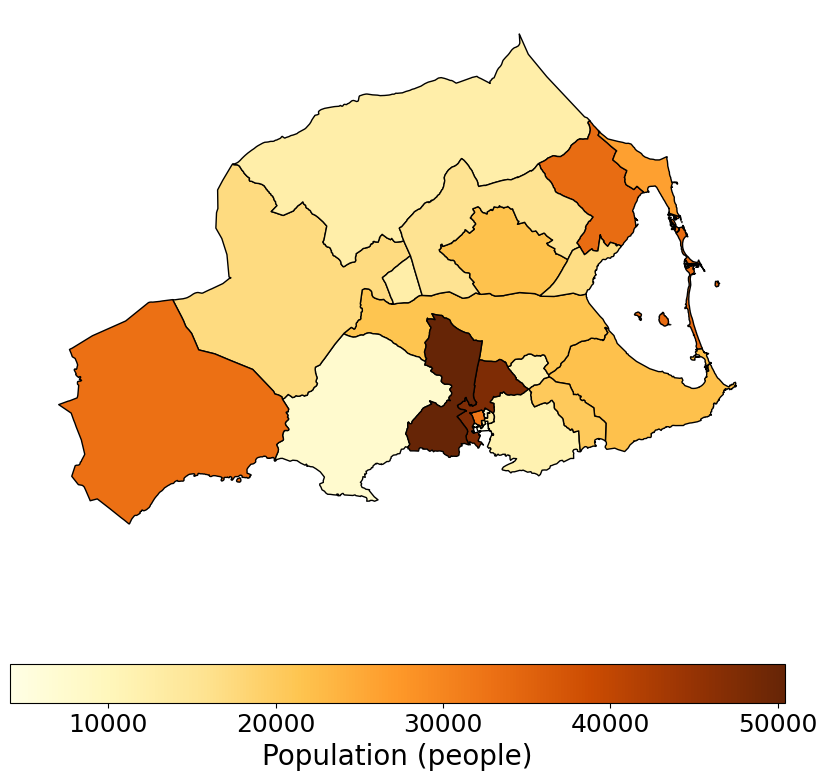

Processing Oviedo…


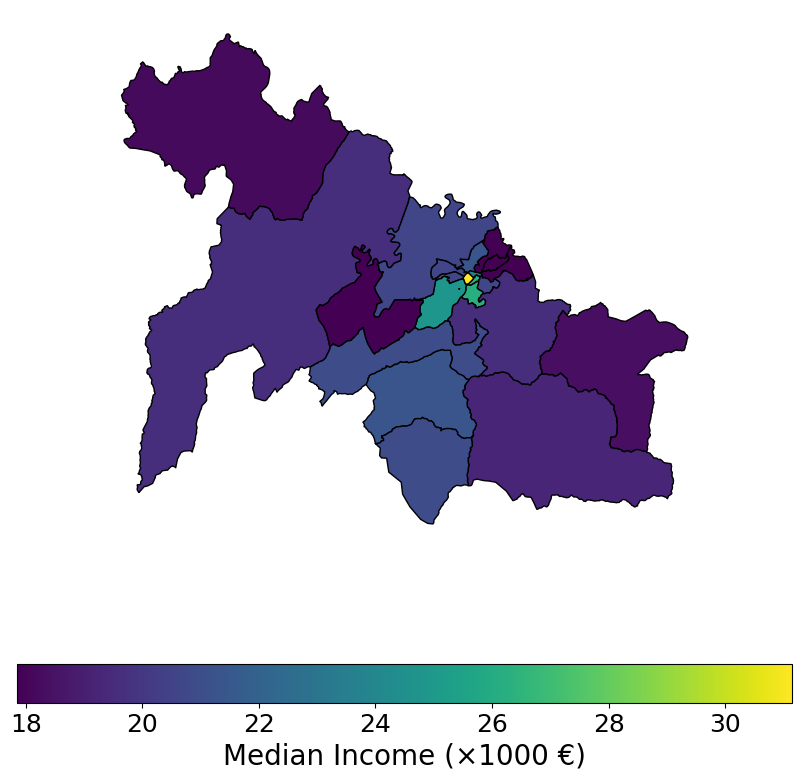

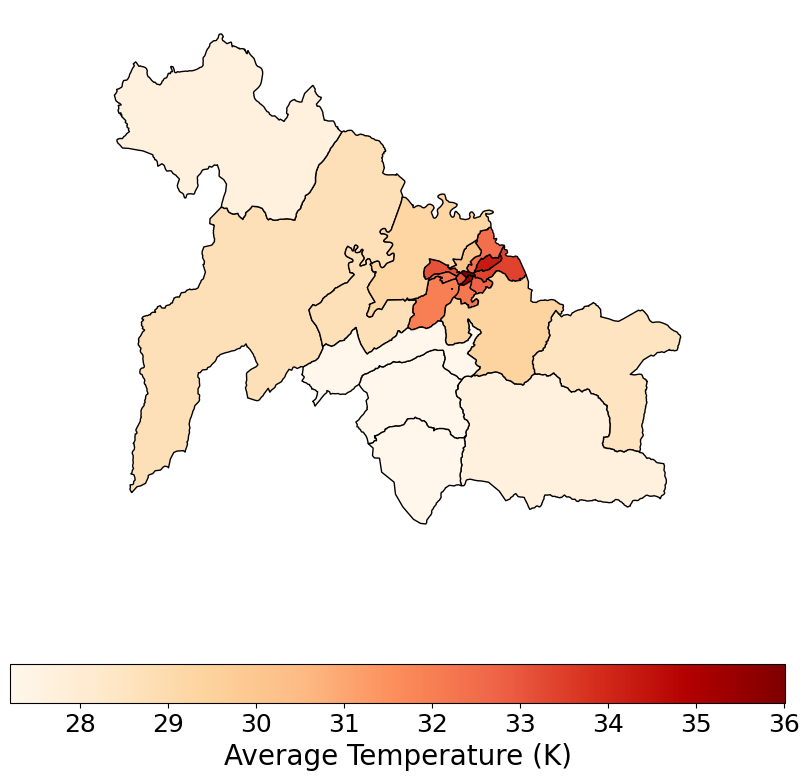

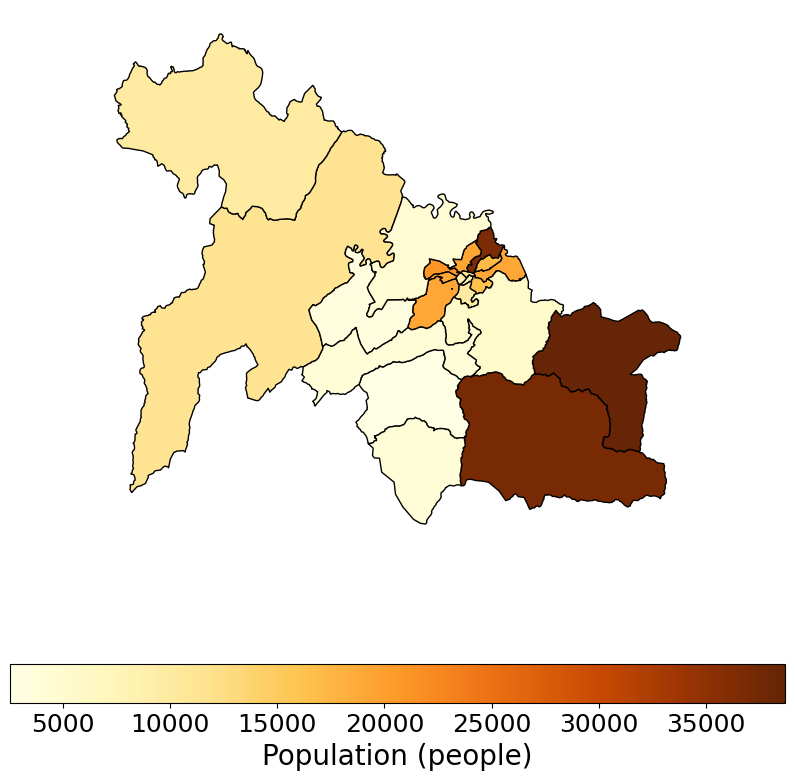

Processing Jerez_de_la_Frontera…


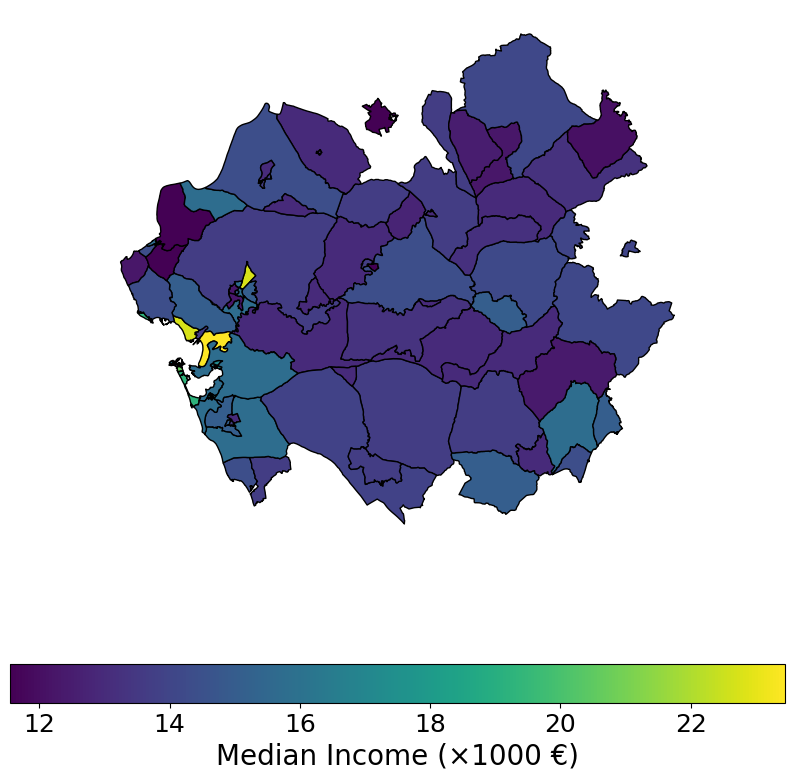

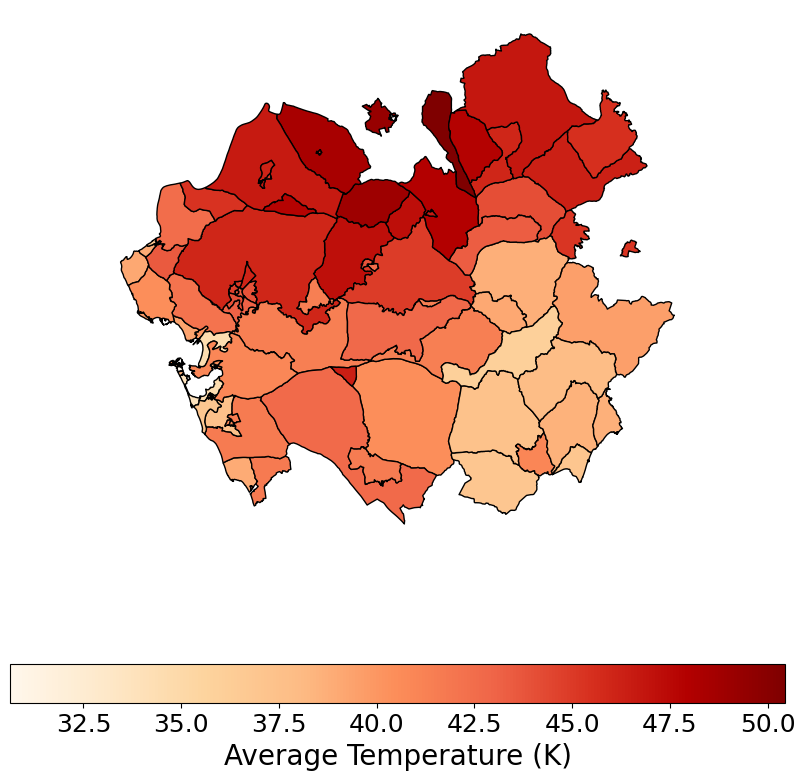

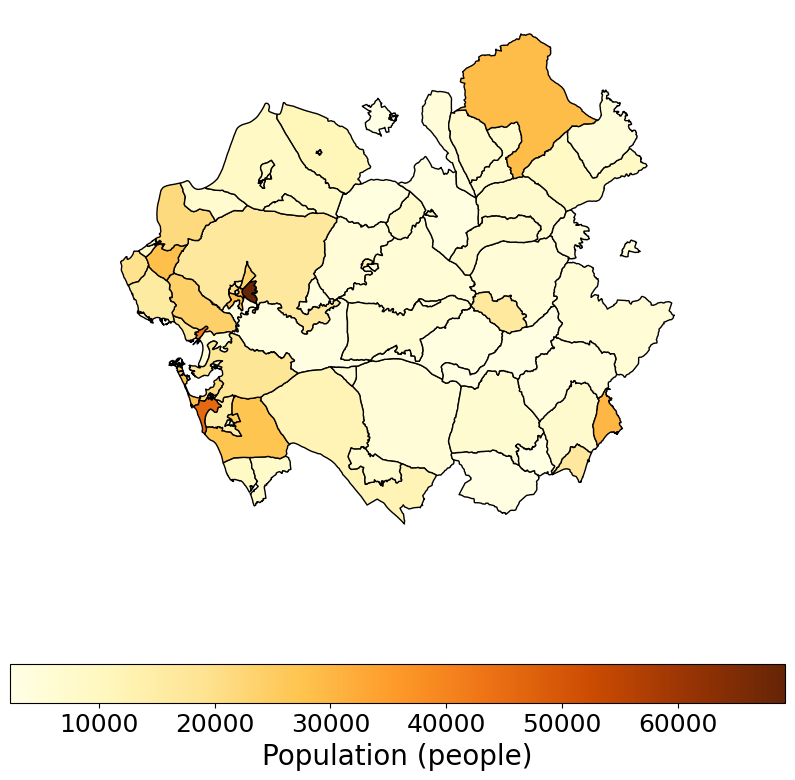

Processing Santa_Cruz_de_Tenerife…


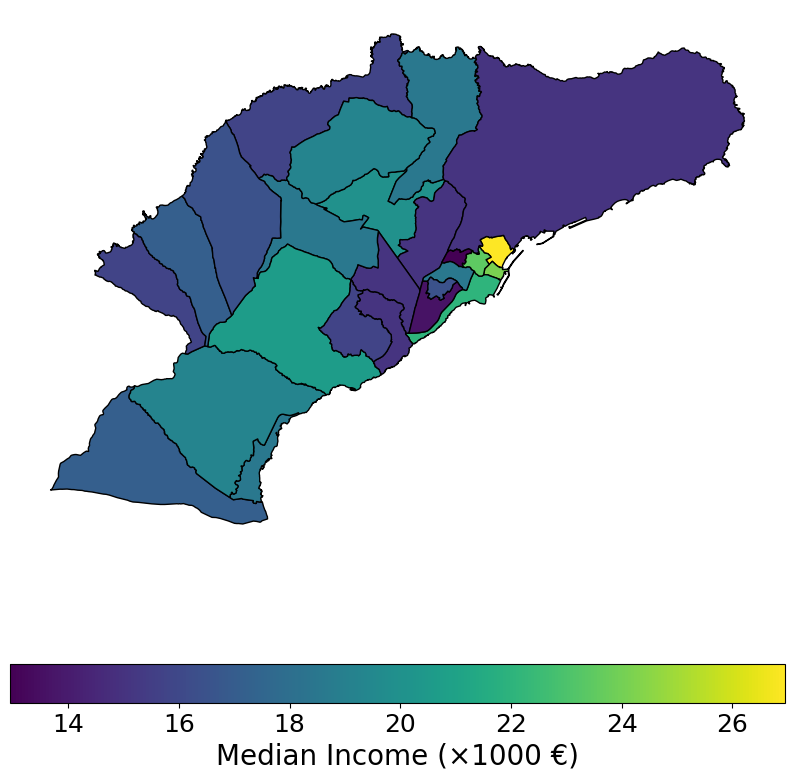

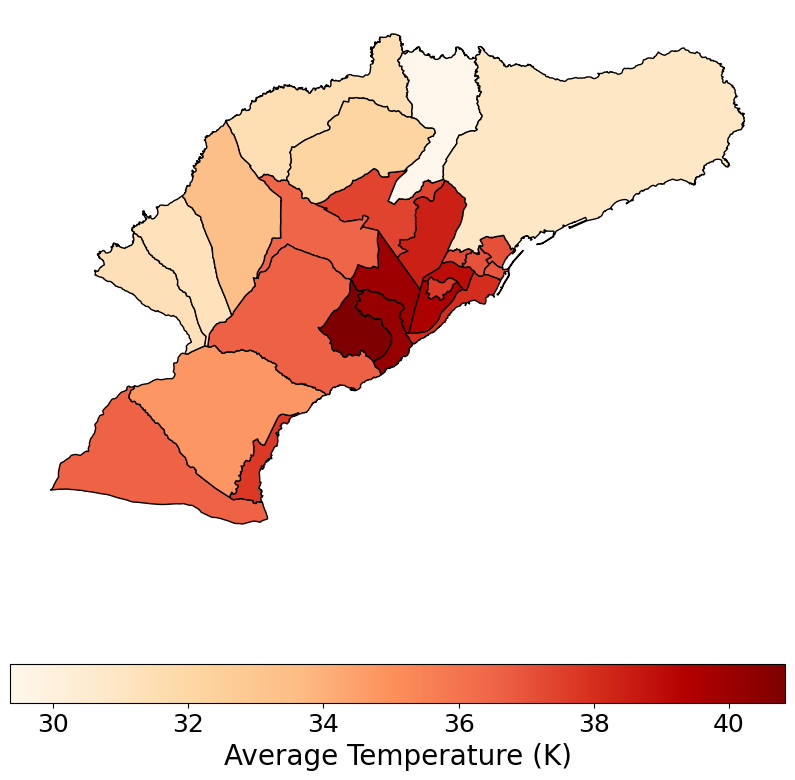

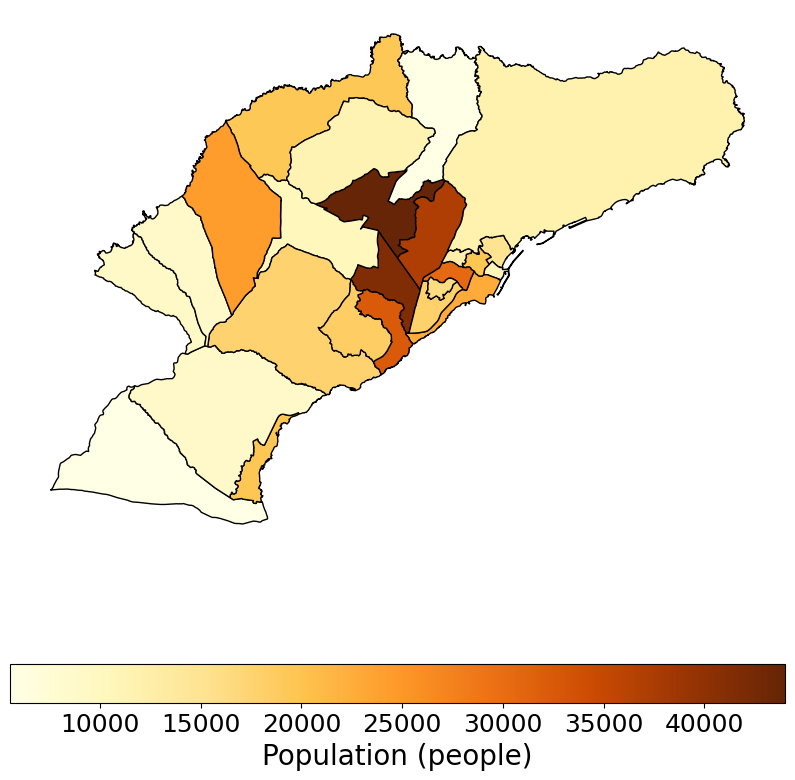

In [14]:
os.chdir(r'C:\Users\mduran\Desktop\PhD\PROJECT 2')

# 1) define your CRS strings
crs_trips = "EPSG:32630"  # the CRS of your results_districts (x,y in UTM30N)
crs_ll    = "EPSG:4326"   # the CRS of extended_bbox_dict (lon/lat)

# 2) turn each lon/lat box into UTM and record its bounds
bbox_utm_bounds = {}
for city, box_ll in extended_bbox_dict.items():
    # make a GeoSeries so we can .to_crs()
    box_utm = (
        gpd.GeoSeries([box_ll], crs=crs_ll)
           .to_crs(crs_trips)
           .iloc[0]
    )
    bbox_utm_bounds[city] = box_utm.bounds  # returns (minx, miny, maxx, maxy)


for city in cities:
    print(f"Processing {city}…")
    city_gdf = results_districts[city]        # already in UTM30N
    crs_metric = city_gdf.crs                  # should == crs_trips

    # unpack the UTM‐projected bbox
    minx, miny, maxx, maxy = bbox_utm_bounds[city]

    # filter districts by their centroid coords
    mask = (
        city_gdf['x'].between(minx, maxx) &
        city_gdf['y'].between(miny, maxy)
    )
    city_filtered = city_gdf[mask].copy()
    if city_filtered.empty:
        print(f"  → No districts left inside bbox for {city}, skipping.")
        continue

    # plotting (unchanged)…
    def plot_choro(gdf, column, cmap, title, units):
        fig, ax = plt.subplots(figsize=(10,10))
        gdf.plot(
            column=column, cmap=cmap, legend=True,
            ax=ax, edgecolor='black',
            legend_kwds={'label':f"{title} ({units})",'orientation':'horizontal'}
        )
        cbar = ax.get_figure().axes[-1]
        cbar.tick_params(labelsize=18)
        cbar.set_xlabel(f"{title} ({units})", fontsize=20)
        ax.set_axis_off()
        plt.show()

    plot_choro(city_filtered, 'median_revenue_per_consumption','viridis',
               'Median Income','×1000 €')
    plot_choro(city_filtered, 'avg_T','OrRd',
               'Average Temperature','K')
    plot_choro(city_filtered, 'population','YlOrBr',
               'Population','people')

In [15]:
pearson_income_LST = {}

for city in cities:
    city_gdf = results_districts[city]

    # bbox filter in UTM
    minx, miny, maxx, maxy = bbox_utm_bounds[city]
    mask = city_gdf['x'].between(minx, maxx) & city_gdf['y'].between(miny, maxy)
    d = city_gdf.loc[mask, ["avg_T", "median_revenue_per_consumption"]].dropna()

    n = len(d)
    if n >= 2 and d["avg_T"].nunique() > 1 and d["median_revenue_per_consumption"].nunique() > 1:
        r, p = pearsonr(d["avg_T"].to_numpy(), d["median_revenue_per_consumption"].to_numpy())
    else:
        r, p = np.nan, np.nan

    pearson_income_LST[city] = {"pearson_r": r, "p_value": p, "n": n}

# quick summary (optional)
vals = [v["pearson_r"] for v in pearson_income_LST.values() if not np.isnan(v["pearson_r"])]
if vals:
    print(f"Mean Pearson r (income–LST): {np.mean(vals):.3f} ± {np.std(vals, ddof=0):.3f}")

# ---- new: fraction of cities with negative r ----
total_cities = len(cities)
neg_count = sum(1 for v in pearson_income_LST.values()
                if (not np.isnan(v["pearson_r"])) and (v["pearson_r"] < 0))

valid_count = sum(1 for v in pearson_income_LST.values()
                  if not np.isnan(v["pearson_r"]))

frac_neg_over_all = neg_count / total_cities if total_cities else np.nan
frac_neg_over_valid = neg_count / valid_count if valid_count else np.nan

print(f"Cities with negative r: {neg_count}/{total_cities} "
      f"({frac_neg_over_all:.2f} of all)")


Mean Pearson r (income–LST): -0.157 ± 0.257
Cities with negative r: 17/23 (0.74 of all)


In [16]:
# Clip results_districts to the city box
for city, ddf in results_districts.items():
    bb = bbox_utm_bounds.get(city)
    if bb is None:
        continue

    minx, miny, maxx, maxy = bb
    mask = ddf['x'].between(minx, maxx) & ddf['y'].between(miny, maxy)
    results_districts[city] = ddf.loc[mask].copy()
    print(f"{city}: kept {len(results_districts[city])} / {len(ddf)} districts inside bbox")

A_Coruna: kept 19 / 21 districts inside bbox
Alicante: kept 31 / 43 districts inside bbox
Barcelona: kept 113 / 137 districts inside bbox
Bilbao: kept 41 / 60 districts inside bbox
Cartagena: kept 19 / 22 districts inside bbox
Cordoba: kept 60 / 77 districts inside bbox
Elche: kept 45 / 54 districts inside bbox
Gijon: kept 18 / 22 districts inside bbox
Granada: kept 31 / 45 districts inside bbox
Jerez_de_la_Frontera: kept 91 / 101 districts inside bbox
Las_Palmas: kept 19 / 23 districts inside bbox
Madrid: kept 149 / 194 districts inside bbox
Malaga: kept 42 / 55 districts inside bbox
Murcia: kept 32 / 35 districts inside bbox
Oviedo: kept 21 / 25 districts inside bbox
Palma_de_Mallorca: kept 48 / 57 districts inside bbox
Santa_Cruz_de_Tenerife: kept 25 / 28 districts inside bbox
Sevilla: kept 45 / 68 districts inside bbox
Valencia: kept 87 / 103 districts inside bbox
Valladolid: kept 31 / 40 districts inside bbox
Vigo: kept 39 / 49 districts inside bbox
Vitoria_Gasteiz: kept 18 / 24 d

In [17]:
if DISTRICTS_THRESHOLD:
    
    MIN_DISTRICTS = 20

    cities_filtered = [
        city for city in cities
        if city in results_districts and len(results_districts[city]) > MIN_DISTRICTS
    ]
    
    cities = cities_filtered
    
    print(f"{len(cities)} cities above threshold of {MIN_DISTRICTS} districts:")
    print(cities)


# OPEN MERGE DATA (mobility + districts)

In [18]:
os.chdir(r'C:\Users\mduran\Desktop\PhD\PROJECT 2\dataframes')

mobs = {}

for city in cities:
    # ------------------------------------------------------------------ #
    # 1 · READ all months & years at once, extracting year & month from 'd'
    # ------------------------------------------------------------------ #
    df = pd.concat([
        pd.read_csv(f'{city}_mob_daily{d}.csv', dtype={'origen': str, 'destino': str})
          .assign(
              year  = int(d[-4:]),     # e.g. '_06_2022' → 2022
              month = int(d[1:3])      # e.g. '_06_2022' → 06 → 6
          )
        for d in dates
    ], ignore_index=True)

    # quick check: annual avg origin‐temp
    yearly_avg = df.groupby('year')['avg_T_origen'].mean()
    print(f"\nAverage origin temperature per year in {city}:")
    print(yearly_avg.to_string(), "\n")

    # ------------------------------------------------------------------ #
    # 2 · BUILD a true date & weekday, then drop the pieces
    # ------------------------------------------------------------------ #
    df['day']     = df['day'].astype(int)
    df['date']    = pd.to_datetime(df[['year','month','day']])
    df['weekday'] = df['date'].dt.weekday
    df = df.drop(columns=['year','month','day'])

    # ------------------------------------------------------------------ #
    # 3 · COMPUTE long‐term district means ACROSS all months & years
    # ------------------------------------------------------------------ #
    env_cols = [
        'avg_T_origen', 'median_income_per_consumption_origen','population_origen'
    ]
    # first, each (year, month, district) gets one mean
    env_month = (
        df
          .groupby([df['date'].dt.year, df['date'].dt.month, 'origen'], as_index=False)[env_cols]
          .mean()
          .rename(columns={
              'origen':       'district_id',
              'avg_T_origen': 'avg_T',
              'median_income_per_consumption_origen':'income',
              'population_origen':'population'
          })
    )
    # then average those by district over *all* months
    env_mean = (
        env_month
          .groupby('district_id', as_index=False)
          .agg({
              'avg_T'     :'mean',
              'income'    :'mean',
              'population':'mean'
          })
    )

    # ------------------------------------------------------------------ #
    # 4 · MERGE the long‐term means back on to every row
    # ------------------------------------------------------------------ #
    # · origen
    df = (
        df
          .merge(env_mean, left_on='origen', right_on='district_id', how='left')
          .drop(columns=[
              'avg_T_origen', 'median_income_per_consumption_origen','population_origen',
              'district_id'
          ])
          .rename(columns={
              'avg_T'     : 'avg_T_origen',
              'income'    : 'median_income_per_consumption_origen',
              'population': 'population_origen'
          })
    )
    # · destino
    df = (
        df
          .merge(env_mean, left_on='destino', right_on='district_id', how='left')
          .drop(columns=[
              'avg_T','income','population','district_id'
          ])
          .rename(columns={
              'avg_T'     : 'avg_T_destino',
              'income'    : 'median_income_per_consumption_destino',
              'population': 'population_destino'
          })
    )

    # ------------------------------------------------------------------ #
    # 5 · FINAL AGGREGATION into mobs[city]
    # ------------------------------------------------------------------ #
    key_cols = [
        'date','origen','destino','weekday',
        'actividad_origen','actividad_destino',
        'renta','edad'
    ]
    fixed_cols = [
        'avg_T_origen','median_income_per_consumption_origen','population_origen',
        'avg_T_destino','median_income_per_consumption_destino','population_destino',
        'distance','x_orig','y_orig','x_dest','y_dest'
    ]
    agg = {'viajes':'sum'}
    agg.update({c:'first' for c in fixed_cols})

    mobs[city] = df.groupby(key_cols, as_index=False).agg(agg)
    print(f"{city}: {len(mobs[city]):,} filas  |  flows tot = {mobs[city]['viajes'].sum():,}")


Average origin temperature per year in Madrid:
year
2022    45.524718
2023    45.947597 



C:\Users\mduran\AppData\Local\Temp\ipykernel_30244\3007300498.py:41: FutureWarning: A grouping was used that is not in the columns of the DataFrame and so was excluded from the result. This grouping will be included in a future version of pandas. Add the grouping as a column of the DataFrame to silence this warning.
  .mean()


Madrid: 32,934,386 filas  |  flows tot = 2,325,687,335.3653426

Average origin temperature per year in Barcelona:
year
2022    37.818219
2023    38.229794 



C:\Users\mduran\AppData\Local\Temp\ipykernel_30244\3007300498.py:41: FutureWarning: A grouping was used that is not in the columns of the DataFrame and so was excluded from the result. This grouping will be included in a future version of pandas. Add the grouping as a column of the DataFrame to silence this warning.
  .mean()


Barcelona: 28,104,839 filas  |  flows tot = 1,655,719,096.4059978

Average origin temperature per year in Valencia:
year
2022    39.559859
2023    38.912617 



...

C:\Users\mduran\AppData\Local\Temp\ipykernel_27124\3007300498.py:41: FutureWarning: A grouping was used that is not in the columns of the DataFrame and so was excluded from the result. This grouping will be included in a future version of pandas. Add the grouping as a column of the DataFrame to silence this warning.
  .mean()


Jerez_de_la_Frontera: 7,609,935 filas  |  flows tot = 574,319,414.9393146



Average origin temperature per year in Santa_Cruz_de_Tenerife:
year
2022    36.73851
2023    36.26127 



C:\Users\mduran\AppData\Local\Temp\ipykernel_27124\3007300498.py:41: FutureWarning: A grouping was used that is not in the columns of the DataFrame and so was excluded from the result. This grouping will be included in a future version of pandas. Add the grouping as a column of the DataFrame to silence this warning.
  .mean()


Santa_Cruz_de_Tenerife: 3,908,454 filas  |  flows tot = 312,120,531.24921566


In [19]:
def mem_MB(df):
    return df.memory_usage(deep=True).sum() / 1_048_576   # 1 MiB

# ---------------------------------------------------------------
# columns to cast
# ---------------------------------------------------------------
cat_cols   = ['origen','destino',
              'actividad_origen','actividad_destino',
              'renta','edad']

float_cols = ['avg_T_origen','avg_T_destino',
              'population_origen','population_destino',
              'distance','x_orig','y_orig','x_dest','y_dest']

# ---------------------------------------------------------------
# 1 · loop over every city table
# ---------------------------------------------------------------
for city, df in mobs.items():
    print(f'\n{city}  — before : {mem_MB(df):,.1f} MB')

    # ---- categoricals -----------------------------------------
    for col in cat_cols:
        if col in df.columns:
            df[col] = df[col].astype('category')

    # ---- numeric down-cast ------------------------------------
    for col in float_cols:
        if col in df.columns:
            df[col] = df[col].astype('float32')           # halves RAM

    mobs[city] = df      # put back (unnecessary if modified in place)

    print(f'{city}  — after  : {mem_MB(df):,.1f} MB')


Madrid  — before : 13,932.0 MB
Madrid  — after  : 2,512.7 MB

Barcelona  — before : 11,890.5 MB
Barcelona  — after  : 2,144.3 MB

Valencia  — before : 7,267.0 MB
Valencia  — after  : 1,278.7 MB

Zaragoza  — before : 1,482.9 MB
Zaragoza  — after  : 259.8 MB

Sevilla  — before : 3,228.5 MB
Sevilla  — after  : 568.4 MB

Malaga  — before : 2,500.1 MB
Malaga  — after  : 438.6 MB

Murcia  — before : 1,261.4 MB
Murcia  — after  : 222.3 MB

Palma_de_Mallorca  — before : 1,644.7 MB
Palma_de_Mallorca  — after  : 288.3 MB

Las_Palmas  — before : 812.1 MB
Las_Palmas  — after  : 142.7 MB

Alicante  — before : 1,461.8 MB
Alicante  — after  : 256.1 MB

Bilbao  — before : 2,885.1 MB
Bilbao  — after  : 507.2 MB

Valladolid  — before : 1,265.7 MB
Valladolid  — after  : 221.9 MB

Cordoba  — before : 1,369.1 MB
Cordoba  — after  : 241.0 MB

Vigo  — before : 1,583.0 MB
Vigo  — after  : 277.4 MB

Gijon  — before : 837.4 MB
Gijon  — after  : 147.1 MB

Vitoria_Gasteiz  — before : 516.9 MB
Vitoria_Gasteiz  — 

Madrid  — after  : 2,512.7 MB



Barcelona  — before : 11,890.5 MB


Barcelona  — after  : 2,144.3 MB



Valencia  — before : 7,267.0 MB


...

Oviedo  — after  : 127.3 MB



Jerez_de_la_Frontera  — before : 3,225.5 MB


Jerez_de_la_Frontera  — after  : 566.1 MB



Santa_Cruz_de_Tenerife  — before : 1,655.7 MB


Santa_Cruz_de_Tenerife  — after  : 290.7 MB


In [20]:
# 1) CRS
crs_trips = "EPSG:32630"  # tus mobs.x_orig/y_orig están en UTM 30N
crs_ll    = "EPSG:4326"   # tus xmin/xmax/ymin/ymax en lon/lat

# 2) Reproyect
bbox_utm_bounds = {}
for city in mobs:
    poly_ll = Polygon([
        (xmin[city], ymin[city]),
        (xmin[city], ymax[city]),
        (xmax[city], ymax[city]),
        (xmax[city], ymin[city]),
    ])
    poly_utm = (
        gpd.GeoSeries([poly_ll], crs=crs_ll)
           .to_crs(crs_trips)
           .iloc[0]
    )
    bbox_utm_bounds[city] = poly_utm.bounds  # (minx, miny, maxx, maxy)

# 3) Check and filter
for city, df in mobs.items():
    
    # --- Check ---
    minx, miny, maxx, maxy = bbox_utm_bounds[city]
    origen_utm = df['x_orig'].between(minx, maxx) & df['y_orig'].between(miny, maxy)
    destino_utm = df['x_dest'].between(minx, maxx) & df['y_dest'].between(miny, maxy)
    print(f"{city} (UTM):   origen_dentro={origen_utm.sum()}, destino_dentro={destino_utm.sum()}")
    mask_both = origen_utm & destino_utm
    print(f"{city}: viajes_con_ambos_dentro={mask_both.sum()} / total={len(df)}\n")

    # --- Filter ---
    mobs[city] = df[mask_both].copy()


Madrid (UTM):   origen_dentro=30286461, destino_dentro=30415789
Madrid: viajes_con_ambos_dentro=28429838 / total=32934386

Barcelona (UTM):   origen_dentro=24939531, destino_dentro=24952743
Barcelona: viajes_con_ambos_dentro=22616024 / total=28104839

Valencia (UTM):   origen_dentro=15727298, destino_dentro=15831797
Valencia: viajes_con_ambos_dentro=14619041 / total=17189140

Zaragoza (UTM):   origen_dentro=3035342, destino_dentro=3061369
Zaragoza: viajes_con_ambos_dentro=2792406 / total=3492703

Sevilla (UTM):   origen_dentro=6450792, destino_dentro=6512857
Sevilla: viajes_con_ambos_dentro=5655196 / total=7641467

Malaga (UTM):   origen_dentro=5078565, destino_dentro=5122547
Malaga: viajes_con_ambos_dentro=4508197 / total=5896450

Murcia (UTM):   origen_dentro=2831578, destino_dentro=2844488
Murcia: viajes_con_ambos_dentro=2745015 / total=2987677

Palma_de_Mallorca (UTM):   origen_dentro=3304769, destino_dentro=3320995
Palma_de_Mallorca: viajes_con_ambos_dentro=2910033 / total=3875119

Madrid: viajes_con_ambos_dentro=28429838 / total=32934386



Barcelona (UTM):   origen_dentro=24939531, destino_dentro=24952743
Barcelona: viajes_con_ambos_dentro=22616024 / total=28104839



Valencia (UTM):   origen_dentro=15727298, destino_dentro=15831797
Valencia: viajes_con_ambos_dentro=14619041 / total=17189140



Zaragoza (UTM):   origen_dentro=3035342, destino_dentro=3061369
Zaragoza: viajes_con_ambos_dentro=2792406 / total=3492703



...

A_Coruna (UTM):   origen_dentro=2186794, destino_dentro=2179501
A_Coruna: viajes_con_ambos_dentro=2029009 / total=2356629

Granada (UTM):   origen_dentro=3829082, destino_dentro=3833865
Granada: viajes_con_ambos_dentro=3292294 / total=4549862



Elche (UTM):   origen_dentro=3104532, destino_dentro=3098633
Elche: viajes_con_ambos_dentro=2841677 / total=3465283

Cartagena (UTM):   origen_dentro=1978897, destino_dentro=1988201


Cartagena: viajes_con_ambos_dentro=1906786 / total=2137057

Oviedo (UTM):   origen_dentro=1554241, destino_dentro=1560085
Oviedo: viajes_con_ambos_dentro=1451924 / total=1710763



Jerez_de_la_Frontera (UTM):   origen_dentro=7019092, destino_dentro=7042034
Jerez_de_la_Frontera: viajes_con_ambos_dentro=6672257 / total=7609935



Santa_Cruz_de_Tenerife (UTM):   origen_dentro=3591335, destino_dentro=3602811
Santa_Cruz_de_Tenerife: viajes_con_ambos_dentro=3330013 / total=3908454



In [21]:
# Count unique 'origen' districts in each city’s DataFrame
district_counts = {
    city: df['origen'].nunique()
    for city, df in mobs.items()
}

district_counts_df = (
    pd.DataFrame.from_dict(district_counts, orient='index', columns=['num_districts'])
      .reset_index()
      .rename(columns={'index': 'city'})
)

print(district_counts_df)

                      city  num_districts
0                   Madrid            149
1                Barcelona            113
2                 Valencia             87
3                 Zaragoza             44
4                  Sevilla             45
5                   Malaga             42
6                   Murcia             32
7        Palma_de_Mallorca             48
8               Las_Palmas             19
9                 Alicante             31
10                  Bilbao             41
11              Valladolid             31
12                 Cordoba             60
13                    Vigo             39
14                   Gijon             18
15         Vitoria_Gasteiz             18
16                A_Coruna             19
17                 Granada             31
18                   Elche             44
19               Cartagena             19
20                  Oviedo             21
21    Jerez_de_la_Frontera             91
22  Santa_Cruz_de_Tenerife        

In [22]:
# check if there are one decimal values in 'viajes'

s = mobs[city]['viajes']

one_decimal_mask = (
    np.isclose(s * 10, np.round(s * 10)) &
    ~np.isclose(s * 100, np.round(s * 100))
)

one_decimal_mask.any()

np.False_

In [23]:
# Keep all trips whose destination is not home, matching RESULTS_SEGREGATION_modeling_good.ipynb.
# This is the mobility universe used by OBS, GRAVITY, and RADIATION below.
df_purpose = {}

for city, df in mobs.items():
    mask = df['actividad_destino'] != 'casa'
    df_purpose[city] = df.loc[mask].copy()

# SEGREGATION METRICS

In [24]:
os.chdir(r'C:\Users\mduran\Desktop\PhD\PROJECT 2')

def rho_assortativity(X_normalized):
    """
    Calculates the Pearson-correlation-based assortativity from a normalized matrix,
    whose row/col correspond to bin labels in [1..n_bins].
    """
    if X_normalized.size == 0 or np.nansum(X_normalized) == 0:
        return np.nan

    n_rows, n_cols = X_normalized.shape
    row_vals = np.arange(1, n_rows+1)  # e.g. 1..5 if n_bins=5
    col_vals = np.arange(1, n_cols+1)

    # sum_{i,j}( i*j*X_ij )
    sum_ij = 0.0
    for i in range(n_rows):
        for j in range(n_cols):
            sum_ij += row_vals[i] * col_vals[j] * X_normalized[i,j]

    # sum_i, sum_j
    sum_i = 0.0
    for i in range(n_rows):
        sum_i += row_vals[i] * np.sum(X_normalized[i,:])
    sum_j = 0.0
    for j in range(n_cols):
        sum_j += col_vals[j] * np.sum(X_normalized[:,j])

    numerator = sum_ij - (sum_i * sum_j)

    # denominator
    sum_i2 = 0.0
    for i in range(n_rows):
        sum_i2 += (row_vals[i]**2) * np.sum(X_normalized[i,:])
    sum_j2 = 0.0
    for j in range(n_cols):
        sum_j2 += (col_vals[j]**2) * np.sum(X_normalized[:,j])

    denom = np.sqrt(sum_i2 - sum_i**2) * np.sqrt(sum_j2 - sum_j**2)
    if denom == 0:
        return np.nan
    return round(numerator / denom, 3)

def total_exposure(X):
    """
    E = (sum_{i,j}(X_ij * j)) / (sum_{i,j}(X_ij)),
    where j in [1..n_bins] are the columns (destination bins).
    """
    total = X.values.sum()
    if total == 0:
        return np.nan

    weighted_sum = 0.0
    for j_bin in X.columns:  
        weighted_sum += j_bin * X[j_bin].sum()
    return round(weighted_sum / total, 3)

def exposure_directional_index(X_normalized):
    """
    R = (X_upper - X_lower)/(X_upper + X_lower),
    where X_upper = sum of X_ij for j>i, X_lower = sum of X_ij for j<i.
    X_norm is normalized so sum(X_norm)=1, with row/col in [1..n_bins].
    """
    if X_normalized.values.sum() == 0:
        return np.nan

    upper = 0.0
    lower = 0.0
    row_bins = X_normalized.index
    col_bins = X_normalized.columns

    for i_idx, i_bin in enumerate(row_bins):
        for j_idx, j_bin in enumerate(col_bins):
            val = X_normalized.iloc[i_idx, j_idx]
            if j_bin > i_bin:
                upper += val
            elif j_bin < i_bin:
                lower += val

    denom = upper + lower
    if denom == 0:
        return np.nan
    return round((upper - lower) / denom, 3)

def exposure_directional_index_row(X):
    """
    Compute the directional index R on a row-normalized basis.
    
    For each row i (representing an origin), normalize the row so that:
        p_ij = X[i, j] / sum_j X[i, j]
    Then, compute for each row:
        R_i = (sum_{j > i} p_ij - sum_{j < i} p_ij) / (sum_{j > i} p_ij + sum_{j < i} p_ij)
    Finally, return the average R across all rows that have trips.
    
    Parameters:
        X : pandas.DataFrame
            The OD matrix (raw trip counts) with rows and columns ordered 
            such that lower triangle corresponds to destinations with higher levels 
            (e.g., risk or income) compared to the origin.
    
    Returns:
        float
            The average directional index R (rounded to 3 decimals). Returns np.nan if no row contains trips.
    """
    r_values = []
    for i_idx, i_bin in enumerate(X.index):
        row_total = X.iloc[i_idx, :].sum()
        if row_total == 0:
            continue  # skip rows with no trips
        # Normalize the row
        p_row = X.iloc[i_idx, :] / row_total
        upper = 0.0
        lower = 0.0
        for j_idx, j_bin in enumerate(X.columns):
            if j_bin > i_bin:
                upper += p_row.iloc[j_idx]
            elif j_bin < i_bin:
                lower += p_row.iloc[j_idx]
        denom = upper + lower
        if denom == 0:
            continue
        r_values.append((upper - lower) / denom)
    
    if len(r_values) == 0:
        return np.nan
    return round(np.mean(r_values), 3)


In [25]:
import numpy as np
import pandas as pd


def compute_metrics_from_OD(
    df_od: pd.DataFrame,
    mapper_T: dict,
    group_col: str,
    group_values: list,
    n_bins: int = 10,
    group_label: str | None = None,
    sanity: bool = False
):
    """
    Calcula rho_T, E_T, R_T, R_T_row a partir de una OD (observada o modelada),
    separando por grupos sociales.

    Requisitos mínimos df_od:
      - 'origen', 'destino', 'viajes'
      - y group_col (p.ej. 'income' o 'renta' o 'edad')
        *Si no existe y group_values tiene solo 1 valor, se inyecta automáticamente.*

    mapper_T:
      {district_id -> Tbin} (Tbin en 1..n_bins)
    """

    if group_label is None:
        group_label = group_col

    df_od = df_od.copy()

    # --- 1) Robustez: si falta group_col pero me estás pidiendo SOLO 1 grupo, lo inyecto ---
    if group_col not in df_od.columns:
        if len(group_values) == 1:
            df_od[group_col] = group_values[0]
        else:
            raise KeyError(
                f"Falta la columna '{group_col}' en df_od. "
                f"Si estás pasando varios grupos ({len(group_values)}), df_od debe incluir esa columna."
            )

    # --- 2) Mapear bins térmicos (pueden salir NaN si algún distrito no está en mapper_T) ---
    df_od["Tbin_origin"] = df_od["origen"].map(mapper_T)
    df_od["Tbin_dest"]   = df_od["destino"].map(mapper_T)

    # Tirar filas donde no se puede asignar bin (si no, pivot/reindex mete cosas raras)
    df_od = df_od.dropna(subset=["Tbin_origin", "Tbin_dest"])

    # Asegurar enteros (tus bins son 1..n_bins)
    df_od["Tbin_origin"] = df_od["Tbin_origin"].astype("int16")
    df_od["Tbin_dest"]   = df_od["Tbin_dest"].astype("int16")

    # Asegurar viajes numérico
    df_od["viajes"] = pd.to_numeric(df_od["viajes"], errors="coerce").fillna(0.0)

    all_bins = list(range(1, n_bins + 1))
    rows = []

    for g in group_values:
        df_g = df_od[df_od[group_col] == g]

        if sanity:
            print(f"[METRICS sanity] {group_col}={g}: rows={len(df_g)} total_viajes={df_g['viajes'].sum()}")

        grouped = (df_g
                   .groupby(["Tbin_origin", "Tbin_dest"], observed=False)["viajes"]
                   .sum()
                   .reset_index())

        X_T = (grouped
               .pivot(index="Tbin_origin", columns="Tbin_dest", values="viajes")
               .fillna(0.0)
               .reindex(index=all_bins, columns=all_bins, fill_value=0.0))

        total = float(X_T.to_numpy().sum())
        X_T_norm = (X_T / total) if total > 0 else X_T

        # --- Tus funciones externas (asumo definidas) ---
        rho_T   = rho_assortativity(X_T_norm.to_numpy())
        E_T     = total_exposure(X_T)                         # usa niveles
        R_T     = exposure_directional_index(X_T_norm)        # espera normalizada (como comentas)
        R_T_row = exposure_directional_index_row(X_T)         # según tu definición (si esperara norm, cámbiala)

        rows.append({group_label: g, "metric": "rho_T",   "value": rho_T})
        rows.append({group_label: g, "metric": "E_T",     "value": E_T})
        rows.append({group_label: g, "metric": "R_T",     "value": R_T})
        rows.append({group_label: g, "metric": "R_T_row", "value": R_T_row})

        if sanity and total > 0:
            # sanity básico: la suma de X_T_norm debe ser 1
            s = float(X_T_norm.to_numpy().sum())
            if abs(s - 1.0) > 1e-6:
                print(f"[METRICS sanity] WARNING: sum(X_T_norm)={s} (esperado 1.0) para {group_col}={g}")

    return pd.DataFrame(rows)

# MONTHLY

In [26]:
keep_intra = False

mobs_total = {}

for city in cities:
    df = df_purpose[city].copy()

    # agregamos flujos, pero conservamos features OD
    agg = (
        df.groupby(['origen', 'destino', 'renta', 'edad'], observed=True)
          .agg({
              'viajes': 'sum',
              'distance': 'first',
              'population_origen': 'first',
              'population_destino': 'first'
          })
          .reset_index()
    )

    if not keep_intra:
        agg = agg.loc[agg['origen'] != agg['destino']].reset_index(drop=True)

    mobs_total[city] = agg

In [27]:
mobs_total[city]

,origen,destino,renta,edad,viajes,distance,population_origen,population_destino
0,38004,3801101,10-15,0-25,33968.680,6331.702148,5604.0,19616.0
1,38004,3801101,10-15,25-45,53736.762,6331.702148,5604.0,19616.0
2,38004,3801101,10-15,45-65,70708.144,6331.702148,5604.0,19616.0
3,38004,3801101,10-15,65-100,24156.432,6331.702148,5604.0,19616.0
4,38004,3801101,<10,0-25,8406.210,6331.702148,5604.0,19616.0
...,...,...,...,...,...,...,...,...
7189,38046,38043,<10,65-100,2641.674,7832.265137,11326.0,24346.0
7190,38046,38043,>15,0-25,1649.922,7832.265137,11326.0,24346.0
7191,38046,38043,>15,25-45,3795.904,7832.265137,11326.0,24346.0
7192,38046,38043,>15,45-65,3768.404,7832.265137,11326.0,24346.0


# BINNING DECILES

In [28]:
n_bins = 10

for city, df in results_districts.items():

    # skip if you already see the columns
    if {'Tbin','Popbin'}.issubset(df.columns):
        continue

    df = df.copy()                                     
    df['Tbin']   = pd.qcut(df['avg_T'],      q=n_bins,
                           labels=False).astype('Int8') + 1
    df['Popbin'] = pd.qcut(df['population'], q=n_bins,
                           labels=False).astype('Int8') + 1

    results_districts[city] = df

In [29]:
results_districts[city]

,city,ID,avg_T,median_revenue_per_consumption,population,geometry,x,y,Tbin,Popbin
1283,Zaragoza,22021_AM,43.306694,19.016667,4828.0,"POLYGON ((707348.264 4653932.159, 707232.259 4...",694575.342801,4.654830e+06,7,4
1285,Zaragoza,22116_AM,41.347500,19.745833,4811.0,"POLYGON ((711328.867 4621262.161, 710936.866 4...",713941.578708,4.644303e+06,4,4
1288,Zaragoza,2212503,41.420192,21.350000,13868.0,"MULTIPOLYGON (((715277.362 4658905.039, 715501...",714277.132195,4.661988e+06,4,7
1290,Zaragoza,2212505,44.127138,20.650000,3950.0,"POLYGON ((713998.89 4667397.433, 713909.888 46...",709477.385103,4.664003e+06,8,2
1299,Zaragoza,50008_AM,40.310519,19.250000,8581.0,"POLYGON ((658256.792 4625014.246, 657746.876 4...",656982.858273,4.629649e+06,2,7
1300,Zaragoza,50017_AM,45.647285,22.050000,2752.0,"POLYGON ((691728.671 4604697.455, 691477.669 4...",699768.452150,4.614071e+06,10,1
1301,Zaragoza,50018_AM,42.056994,16.362500,5085.0,"POLYGON ((638605.417 4577075.974, 638578.416 4...",637059.125374,4.586317e+06,5,4
1302,Zaragoza,50025,41.095348,16.100000,7983.0,"POLYGON ((635314.006 4589323.171, 635255.525 4...",636937.043571,4.592450e+06,3,7
1303,Zaragoza,50062_AM,38.902500,20.183333,4712.0,"POLYGON ((688372.689 4606027.518, 688438.692 4...",689087.300762,4.605783e+06,1,3
1304,Zaragoza,50066,44.404853,19.950000,4334.0,"POLYGON ((671057.152 4603717.311, 671113.152 4...",670442.222911,4.601786e+06,8,2


## OBSERVED

In [30]:
income_groups = ['<10', '10-15', '>15']
n_bins = 10

obs_income_list = []

for city in cities:
    ddf = results_districts[city]
    mapper_T = ddf.set_index('ID')['Tbin'].to_dict()
    df_city = mobs_total[city]


    df_metrics = compute_metrics_from_OD(
        df_od        = df_city,
        mapper_T     = mapper_T,
        group_col    = 'renta',
        group_values = income_groups,
        n_bins       = n_bins,
        group_label  = 'renta'   # nombre de la columna de salida
    )
    df_metrics['city']  = city
    df_metrics['model'] = 'OBS'

    obs_income_list.append(df_metrics)

df_obs_income = pd.concat(obs_income_list, ignore_index=True)

In [31]:
age_groups = ['0-25', '25-45', '45-65', '65-100']
n_bins = 10

obs_age_list = []

for city in cities:
    ddf = results_districts[city]
    mapper_T = ddf.set_index('ID')['Tbin'].to_dict()
    df_city = mobs_total[city]

    df_metrics_age = compute_metrics_from_OD(
        df_od        = df_city,
        mapper_T     = mapper_T,
        group_col    = 'edad',       # columna de la OD
        group_values = age_groups,   # categorías de edad
        n_bins       = n_bins,
        group_label  = 'edad'         # output name
    )
    df_metrics_age['city']  = city
    df_metrics_age['model'] = 'OBS'

    obs_age_list.append(df_metrics_age)

df_obs_age = pd.concat(obs_age_list, ignore_index=True)

# modeling

## gravity model

In [38]:
# exponential
dist_scale=1000
def make_design_exp(df_raw, *, min_flows=1):
    """
    Gravity design matrix with *exponential* distance decay.

    df_raw: OD of ONE city (already with distance, populations, SES, renta...)
            minimum columns:
               ['origen','destino','distance',
                'population_origen','population_destino',
                'viajes']

    min_flows: keep only OD pairs with viajes >= min_flows
    dist_scale: factor to rescale distance
                e.g. if distance is in meters, dist_scale=1000 → km

    Returns:
        - df_clean: cleaned OD (no intra, no dist=0, no inf/nan)
        - X: design matrix (with constant)
        - y: observed flows
        - O_obs: dict {origin -> total_outgoing_trips_observed}
                 computed on df_clean (same base used by the model).
    """
    df = df_raw.copy()

    # 1) minimum flows
    df = df[df['viajes'] >= min_flows]

    # 2) remove intra-district and zero distance
    df = df[(df['origen'] != df['destino']) & (df['distance'] > 0)]

    # 3) variables for exponential gravity
    #    distance (scaled) enters linearly in the log-link:
    #    log E[T_ij] = β0 + β_d * dist_scaled + β_o log(pop_i) + β_d log(pop_j)
    df['dist_exp']     = df['distance'] / dist_scale   # e.g. distance in km
    df['log_pop_dest'] = np.log(df['population_destino'])
    df['log_pop_orig'] = np.log(df['population_origen'])

    # 4) drop inf / nan in covariates
    needed = ['dist_exp', 'log_pop_dest', 'log_pop_orig']
    df = df.replace([np.inf, -np.inf], np.nan).dropna(subset=needed + ['viajes'])

    if df.empty:
        # Defensive: return empty structures if all rows got dropped
        return df, None, None, {}

    # 5) observed totals per origin (for the O_i constraint)
    O_obs = df.groupby('origen')['viajes'].sum().to_dict()

    # 6) design matrix
    X = sm.add_constant(df[needed], has_constant='add')
    y = df['viajes'].astype(float)

    return df, X, y, O_obs

#Power-law
def make_design(df_raw, *, min_flows=1):
    """
    df_raw: OD de UNA ciudad (ya con distance, populations, SES, renta...)
            columnas mínimas: ['origen','destino','distance',
                               'population_origen','population_destino',
                               'viajes']

    Devuelve:
        - df_clean: OD limpio (sin intra, sin dist=0, sin inf/nan)
        - X: matriz de diseño (con constante)
        - y: flujos observados
        - O_obs: dict {origen -> total_outgoing_trips_observed}
                 calculado SOBRE df_clean (misma base que el modelo).
    """
    df = df_raw.copy()

    # 1) mínimo de flujos
    df = df[df['viajes'] >= min_flows]

    # 2) quitar intra-distrito + distancia cero
    df = df[(df['origen'] != df['destino']) & (df['distance'] > 0)]

    # 3) variables del gravity
    df['log_dist']     = np.log(df['distance'])
    df['log_pop_dest'] = np.log(df['population_destino'])
    df['log_pop_orig'] = np.log(df['population_origen'])
    
    # 4) quitar inf / nan (en las covariables)
    needed = ['log_dist', 'log_pop_dest', 'log_pop_orig']
    df = df.replace([np.inf, -np.inf], np.nan).dropna(subset=needed + ['viajes'])

    # 5) totales observados por origen
    O_obs = df.groupby('origen')['viajes'].sum().to_dict()

    # 6) diseño
    X = sm.add_constant(df[needed], has_constant='add')
    y = df['viajes'].astype(float)

    return df, X, y, O_obs


def apply_origin_constraint(df_pred, col_raw, col_scaled, O_obs):
    """
    df_pred: DataFrame con al menos columnas ['origen', col_raw]
    col_raw: nombre de la columna de predicciones crudas (gravity)
    col_scaled: nombre de la nueva columna donde guardar las predicciones
                re-escaladas para que sumen O_obs[i] por origen.
    O_obs: dict {origen -> total observado} sobre la MISMA base.

    Modifica df_pred in-place y lo devuelve.
    """
    df_pred[col_scaled] = 0.0

    for o, g in df_pred.groupby('origen'):
        total_raw = g[col_raw].sum()
        Oi = O_obs.get(o, 0.0)

        if total_raw > 0 and Oi > 0:
            scale = Oi / total_raw
        else:
            scale = 0.0

        df_pred.loc[g.index, col_scaled] = g[col_raw] * scale

    return df_pred


In [39]:
# ============================================================
# GRAVITY: one global shared parameter vector
# - Fit one Poisson gravity model on total inter-district OD flows pooled across cities.
# - Apply the same fitted parameters to every city, income group, and age group.
# - Preserve each group's observed OD support and origin outflows O_i.
# ============================================================

income_groups = ['<10', '10-15', '>15']
n_bins = 10
distance_functional_form = 'power law'
GRAVITY_FIT_SCOPE = 'global_shared_across_all_cities_and_groups'


def aggregate_city_od_for_shared_gravity(df_city):
    """Aggregate all sociodemographic rows to one total-flow OD table for fitting."""
    df = df_city[df_city['origen'] != df_city['destino']].copy()
    df['viajes'] = pd.to_numeric(df['viajes'], errors='coerce').fillna(0.0)
    return (
        df.groupby(['origen', 'destino'], as_index=False, observed=True)
        .agg(
            viajes=('viajes', 'sum'),
            distance=('distance', 'first'),
            population_origen=('population_origen', 'first'),
            population_destino=('population_destino', 'first'),
        )
    )


def build_gravity_design(df_raw, distance_form='power law'):
    if distance_form == 'power law':
        df_clean, X, y, O_obs = make_design(df_raw, min_flows=1)
        cols = ['const', 'log_dist', 'log_pop_dest', 'log_pop_orig']
    elif distance_form == 'exponential':
        df_clean, X, y, O_obs = make_design_exp(df_raw, min_flows=1)
        cols = ['const', 'dist_exp', 'log_pop_dest', 'log_pop_orig']
    else:
        raise ValueError(f'Unknown distance_functional_form: {distance_form}')
    return df_clean, X, y, O_obs, cols


def fit_poisson_gravity(df_fit, distance_form='power law'):
    df_clean, X, y, _, cols = build_gravity_design(df_fit, distance_form)
    if df_clean.empty:
        raise ValueError('No valid OD rows available for global gravity fit.')
    model = sm.GLM(y, X[cols], family=sm.families.Poisson()).fit(maxiter=200)
    return model, cols, df_clean


# Fit exactly one model using total flows pooled across all cities.
global_fit_frames = []
for city in cities:
    df_fit_city = aggregate_city_od_for_shared_gravity(mobs_total[city])
    df_fit_city['fit_city'] = city
    global_fit_frames.append(df_fit_city)

df_fit_global = pd.concat(global_fit_frames, ignore_index=True)
global_gravity_model, global_gravity_cols, df_fit_global_clean = fit_poisson_gravity(
    df_fit_global,
    distance_form=distance_functional_form,
)

df_gravity_shared_params = pd.DataFrame([{
    'fit_scope': GRAVITY_FIT_SCOPE,
    'n_fit_od_rows': len(df_fit_global_clean),
    'n_cities': len(cities),
    **global_gravity_model.params.to_dict(),
}])
print(f'Global shared gravity model fitted on {len(df_fit_global_clean):,} total-flow OD rows from {len(cities)} cities')
display(df_gravity_shared_params)


# Apply the global parameters to income-group OD supports.
all_models_metrics = []
all_preds = []

for city in cities:
    print(f'\n=== {city} | INCOME | global shared parameters ===')

    df_city = mobs_total[city].copy()
    df_city = df_city[df_city['origen'] != df_city['destino']].copy()
    mapper_T = results_districts[city].set_index('ID')['Tbin'].to_dict()

    for inc in income_groups:
        # Match RESULTS_SEGREGATION_modeling_good.ipynb: one row per OD-income
        # before applying the shared gravity parameters.
        df_inc_all = (
            df_city[df_city['renta'] == inc]
            .groupby(['origen', 'destino', 'renta'], observed=True, dropna=False)
            .agg(
                viajes=('viajes', 'sum'),
                distance=('distance', 'first'),
                population_origen=('population_origen', 'first'),
                population_destino=('population_destino', 'first'),
            )
            .reset_index()
        )
        if df_inc_all.empty:
            continue

        df_clean, X_all, y_all, O_obs, cols_group = build_gravity_design(
            df_inc_all,
            distance_form=distance_functional_form,
        )
        if df_clean.empty:
            continue
        if cols_group != global_gravity_cols:
            raise ValueError(f'Design columns differ for {city}, income {inc}.')

        df_pred = df_clean.copy()
        df_pred['viajes_hat_M1_raw'] = global_gravity_model.predict(X_all[global_gravity_cols])
        df_pred = apply_origin_constraint(
            df_pred,
            col_raw='viajes_hat_M1_raw',
            col_scaled='viajes_hat_M1',
            O_obs=O_obs,
        )
        df_pred['city'] = city
        df_pred['gravity_fit_scope'] = GRAVITY_FIT_SCOPE
        all_preds.append(df_pred)

        df_obs_input = df_clean[['origen', 'destino', 'renta', 'viajes']].copy()
        df_obs_metrics = compute_metrics_from_OD(
            df_od=df_obs_input,
            mapper_T=mapper_T,
            group_col='renta',
            group_values=[inc],
            n_bins=n_bins,
            group_label='renta',
        )
        df_obs_metrics['city'] = city
        df_obs_metrics['model'] = 'OBS'
        all_models_metrics.append(df_obs_metrics)

        df_m1_input = (
            df_pred[['origen', 'destino', 'renta', 'viajes_hat_M1']]
            .rename(columns={'viajes_hat_M1': 'viajes'})
            .copy()
        )
        df_m1_metrics = compute_metrics_from_OD(
            df_od=df_m1_input,
            mapper_T=mapper_T,
            group_col='renta',
            group_values=[inc],
            n_bins=n_bins,
            group_label='renta',
        )
        df_m1_metrics['city'] = city
        df_m1_metrics['model'] = 'GRAVITY'
        all_models_metrics.append(df_m1_metrics)


df_models_income = pd.concat(all_models_metrics, ignore_index=True)
df_preds_income = pd.concat(all_preds, ignore_index=True)


Global shared gravity model fitted on 72,379 total-flow OD rows from 23 cities


,fit_scope,n_fit_od_rows,n_cities,const,log_dist,log_pop_dest,log_pop_orig
0,global_shared_across_all_cities_and_groups,72379,23,10.446198,-1.28017,0.561907,0.669532



=== Madrid | INCOME | global shared parameters ===


C:\Users\mduran\AppData\Local\Temp\ipykernel_30244\240387517.py:95: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  O_obs = df.groupby('origen')['viajes'].sum().to_dict()
C:\Users\mduran\AppData\Local\Temp\ipykernel_30244\240387517.py:116: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for o, g in df_pred.groupby('origen'):
C:\Users\mduran\AppData\Local\Temp\ipykernel_30244\240387517.py:95: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence thi


=== Barcelona | INCOME | global shared parameters ===


...


=== Jerez_de_la_Frontera | INCOME | global shared parameters ===


C:\Users\mduran\AppData\Local\Temp\ipykernel_30244\240387517.py:95: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  O_obs = df.groupby('origen')['viajes'].sum().to_dict()
C:\Users\mduran\AppData\Local\Temp\ipykernel_30244\240387517.py:116: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for o, g in df_pred.groupby('origen'):
C:\Users\mduran\AppData\Local\Temp\ipykernel_30244\240387517.py:95: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence thi


=== Santa_Cruz_de_Tenerife | INCOME | global shared parameters ===


C:\Users\mduran\AppData\Local\Temp\ipykernel_30244\240387517.py:95: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  O_obs = df.groupby('origen')['viajes'].sum().to_dict()
C:\Users\mduran\AppData\Local\Temp\ipykernel_30244\240387517.py:116: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for o, g in df_pred.groupby('origen'):
C:\Users\mduran\AppData\Local\Temp\ipykernel_30244\240387517.py:95: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence thi

C:\Users\mduran\AppData\Local\Temp\ipykernel_27124\240387517.py:95: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  O_obs = df.groupby('origen')['viajes'].sum().to_dict()
C:\Users\mduran\AppData\Local\Temp\ipykernel_27124\240387517.py:116: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for o, g in df_pred.groupby('origen'):
C:\Users\mduran\AppData\Local\Temp\ipykernel_27124\240387517.py:95: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence thi

In [41]:
# Apply the same global parameters to age-group OD supports.
age_groups = ['0-25', '25-45', '45-65', '65-100']
n_bins = 10

all_models_metrics_age = []
all_preds_age = []

for city in cities:
    print(f'\n=== {city} | AGE | global shared parameters ===')

    df_city = mobs_total[city].copy()
    df_city = df_city[df_city['origen'] != df_city['destino']].copy()
    mapper_T = results_districts[city].set_index('ID')['Tbin'].to_dict()

    for age in age_groups:
        df_age_all = df_city[df_city['edad'] == age].copy()
        if df_age_all.empty:
            continue

        df_clean, X_all, y_all, O_obs, cols_group = build_gravity_design(
            df_age_all,
            distance_form=distance_functional_form,
        )
        if df_clean.empty:
            continue
        if cols_group != global_gravity_cols:
            raise ValueError(f'Design columns differ for {city}, age {age}.')

        df_pred = df_clean.copy()
        df_pred['viajes_hat_M1_raw'] = global_gravity_model.predict(X_all[global_gravity_cols])
        df_pred = apply_origin_constraint(
            df_pred,
            col_raw='viajes_hat_M1_raw',
            col_scaled='viajes_hat_M1',
            O_obs=O_obs,
        )
        df_pred['city'] = city
        df_pred['gravity_fit_scope'] = GRAVITY_FIT_SCOPE
        all_preds_age.append(df_pred)

        df_obs_input = df_clean[['origen', 'destino', 'edad', 'viajes']].copy()
        df_obs_metrics = compute_metrics_from_OD(
            df_od=df_obs_input,
            mapper_T=mapper_T,
            group_col='edad',
            group_values=[age],
            n_bins=n_bins,
            group_label='edad',
        )
        df_obs_metrics['city'] = city
        df_obs_metrics['model'] = 'OBS'
        all_models_metrics_age.append(df_obs_metrics)

        df_m1_input = (
            df_pred[['origen', 'destino', 'edad', 'viajes_hat_M1']]
            .rename(columns={'viajes_hat_M1': 'viajes'})
            .copy()
        )
        df_m1_metrics = compute_metrics_from_OD(
            df_od=df_m1_input,
            mapper_T=mapper_T,
            group_col='edad',
            group_values=[age],
            n_bins=n_bins,
            group_label='edad',
        )
        df_m1_metrics['city'] = city
        df_m1_metrics['model'] = 'GRAVITY'
        all_models_metrics_age.append(df_m1_metrics)


df_models_age = pd.concat(all_models_metrics_age, ignore_index=True)
df_preds_age = pd.concat(all_preds_age, ignore_index=True)



=== Madrid | AGE | global shared parameters ===


C:\Users\mduran\AppData\Local\Temp\ipykernel_30244\240387517.py:95: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  O_obs = df.groupby('origen')['viajes'].sum().to_dict()
C:\Users\mduran\AppData\Local\Temp\ipykernel_30244\240387517.py:116: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for o, g in df_pred.groupby('origen'):
C:\Users\mduran\AppData\Local\Temp\ipykernel_30244\240387517.py:95: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence thi


=== Barcelona | AGE | global shared parameters ===


C:\Users\mduran\AppData\Local\Temp\ipykernel_30244\240387517.py:95: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  O_obs = df.groupby('origen')['viajes'].sum().to_dict()
C:\Users\mduran\AppData\Local\Temp\ipykernel_30244\240387517.py:116: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for o, g in df_pred.groupby('origen'):
C:\Users\mduran\AppData\Local\Temp\ipykernel_30244\240387517.py:95: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence thi


=== Valencia | AGE | global shared parameters ===


...


=== Santa_Cruz_de_Tenerife | AGE | global shared parameters ===


C:\Users\mduran\AppData\Local\Temp\ipykernel_30244\240387517.py:95: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  O_obs = df.groupby('origen')['viajes'].sum().to_dict()
C:\Users\mduran\AppData\Local\Temp\ipykernel_30244\240387517.py:116: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for o, g in df_pred.groupby('origen'):
C:\Users\mduran\AppData\Local\Temp\ipykernel_30244\240387517.py:95: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence thi

C:\Users\mduran\AppData\Local\Temp\ipykernel_27124\240387517.py:95: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  O_obs = df.groupby('origen')['viajes'].sum().to_dict()
C:\Users\mduran\AppData\Local\Temp\ipykernel_27124\240387517.py:116: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for o, g in df_pred.groupby('origen'):
C:\Users\mduran\AppData\Local\Temp\ipykernel_27124\240387517.py:95: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence thi


=== Santa_Cruz_de_Tenerife | AGE | global shared parameters ===


C:\Users\mduran\AppData\Local\Temp\ipykernel_27124\240387517.py:95: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  O_obs = df.groupby('origen')['viajes'].sum().to_dict()
C:\Users\mduran\AppData\Local\Temp\ipykernel_27124\240387517.py:116: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for o, g in df_pred.groupby('origen'):
C:\Users\mduran\AppData\Local\Temp\ipykernel_27124\240387517.py:95: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence thi

## radiation model

In [43]:
from scipy.spatial.distance import cdist

# ---------- 1) Build nodes from results_districts ----------
def build_city_nodes(results_districts_city: pd.DataFrame):
    """Return nodes with ID, x, y, pop (para el radiation)."""
    nodes = (results_districts_city
             .rename(columns={'population': 'pop'})
             [['ID', 'x', 'y', 'pop']]
             .drop_duplicates('ID')
             .set_index('ID'))
    return nodes

# ---------- 2) Radiation kernel precomputation (once per city) ----------
def radiation_kernel(nodes: pd.DataFrame):
    """
    nodes: index=ID, cols ['x','y','pop']

    Devuelve:
      - node_ids: lista de IDs de distrito (mismo orden que en la matriz)
      - base: matriz M×M con los pesos de radiation (sin parámetros)

    Después, en la predicción haremos:
       T_ij^rad ≈ O_i * base_ij (luego reescalamos por fila para que
       sum_j T_ij^rad = O_i exactamente).
    """
    XY  = nodes[['x', 'y']].to_numpy(float)
    POP = nodes['pop'].to_numpy(float)
    M   = len(nodes)
    node_ids = nodes.index.to_list()

    # distancias euclídeas entre centroides
    D = cdist(XY, XY)  # M×M

    # s_ij: población estrictamente dentro del radio d_ij alrededor de i,
    # excluyendo i y j
    order      = np.argsort(D, axis=1)          # índices ordenados por distancia desde i
    P_sorted   = POP[order]                     # pops en ese orden
    cumsum_pop = np.cumsum(P_sorted, axis=1)    # incluye pop(i) primero
    inv_order  = np.empty_like(order)
    inv_order[np.arange(M)[:, None], order] = np.arange(M)[None, :]
    r = inv_order

    # s_ij = suma de pop de nodos más cercanos que j, excluyendo i
    s = np.where(
        r > 0,
        np.take_along_axis(cumsum_pop, r-1, axis=1) - POP[:, None],
        0.0
    )
    s = np.clip(s, 0.0, None)

    m_i  = POP[:, None]
    m_j  = POP[None, :]
    Mtot = POP.sum()

    # corrección de tamaño finito
    with np.errstate(divide='ignore', invalid='ignore'):
        finite_fac = 1.0 / (1.0 - (m_i / max(Mtot, 1e-12)))
        finite_fac = np.where(np.isfinite(finite_fac), finite_fac, 0.0)

    num  = m_i * m_j
    den  = (m_i + s) * (m_i + m_j + s)
    base = np.divide(num, den, out=np.zeros_like(num, float), where=(den > 0))
    base *= finite_fac

    # NO intra-district trips en el modelo → diagonal a 0
    np.fill_diagonal(base, 0.0)

    # opcional: renormalizar filas para que sum_j base_ij = 1 (excepto filas sin vecinos)
    row_sums = base.sum(axis=1, keepdims=True)
    base = np.divide(base, row_sums, out=np.zeros_like(base), where=(row_sums > 0))

    return node_ids, base

In [44]:
def radiation_predict_with_kernel(df_od: pd.DataFrame, node_ids, base: np.ndarray,
                                  sanity: bool = False, sanity_prefix: str = "", tol: float = 1e-6):
    """
    df_od: columnas ['origen','destino','viajes'] (ya filtrado al grupo)
    Devuelve df con columna 'viajes_hat_RAD' en el mismo soporte OD.
    """
    if df_od.empty:
        out = df_od.copy()
        out["viajes_hat_RAD"] = 0.0
        return out

    df = df_od.copy()
    df = df[df["origen"] != df["destino"]].copy()

    node_ids = pd.Index([str(x) for x in node_ids])
    id_to_row = {nid: i for i, nid in enumerate(node_ids)}

    df["o_str"] = df["origen"].astype(str)
    df["d_str"] = df["destino"].astype(str)
    df["viajes"] = pd.to_numeric(df["viajes"], errors="coerce").fillna(0.0)

    # O_i (outflow) observado EN ESTE DF => grupo-específico si df_od está filtrado por grupo
    O_out = (df.groupby("o_str", observed=True)["viajes"]
               .sum()
               .reindex(node_ids)
               .fillna(0.0)
               .to_numpy())

    i_pos = df["o_str"].map(id_to_row)
    j_pos = df["d_str"].map(id_to_row)
    mask = i_pos.notna() & j_pos.notna()

    viajes_hat = np.zeros(len(df), dtype=float)
    if not mask.any():
        df["viajes_hat_RAD"] = viajes_hat
        return df.drop(columns=["o_str", "d_str"], errors="ignore")

    ii = i_pos[mask].astype(int).to_numpy()
    jj = j_pos[mask].astype(int).to_numpy()

    p_ij = base[ii, jj].astype(float)

    denom = np.bincount(ii, weights=p_ij, minlength=base.shape[0])
    denom_i = denom[ii]
    O_i = O_out[ii]

    with np.errstate(divide="ignore", invalid="ignore"):
        hat = np.divide(O_i * p_ij, denom_i, out=np.zeros_like(p_ij), where=(denom_i > 0))

    viajes_hat[mask] = hat
    df["viajes_hat_RAD"] = viajes_hat

    # --- sanity: por origen, suma_j hat_ij debe igualar O_i (si denom>0)
    if sanity:
        hat_out = (df.loc[mask].groupby("o_str", observed=True)["viajes_hat_RAD"]
                     .sum().reindex(node_ids).fillna(0.0).to_numpy())
        valid = denom > 0
        max_abs_err = float(np.max(np.abs(hat_out[valid] - O_out[valid]))) if np.any(valid) else 0.0
        total_obs = float(np.sum(O_out))
        total_hat = float(np.sum(hat_out))
        prefix = f"[SANITY {sanity_prefix}] " if sanity_prefix else "[SANITY] "
        if max_abs_err > tol or abs(total_obs - total_hat) > 10 * tol:
            print(prefix + f"WARNING: max|sum_hat-O|={max_abs_err:.6g}, total_obs={total_obs:.6g}, total_hat={total_hat:.6g}")
        else:
            print(prefix + f"OK: max_abs_err={max_abs_err:.6g}, total_obs={total_obs:.6g}, total_hat={total_hat:.6g}")

    return df.drop(columns=["o_str", "d_str"], errors="ignore")


def sanity_check_no_crossjoin(df_preds: pd.DataFrame, group_col_out: str):
    """
    Detecta el síntoma de cross join:
    para un mismo (city,origen,destino) aparecen múltiples valores del grupo.
    """
    if df_preds.empty:
        return
    bad = (df_preds.groupby(["city","origen","destino"])[group_col_out].nunique())
    if (bad > 1).any():
        print(f"[SANITY INTEGRITY] ERROR: mezcla de grupos en el mismo OD para '{group_col_out}'. "
              f"Probable merge/cross-join aguas abajo.")
        print(bad[bad > 1].head(10))
    else:
        print(f"[SANITY INTEGRITY] OK: sin mezcla de '{group_col_out}' dentro del mismo OD.")


def run_radiation_all_cities_group(
    mobs_total: dict,
    results_districts: dict,
    *,
    cities: list,
    group_col_in: str,         # columna REAL en mobs_total[city] (p.ej. 'renta' o 'income' o 'edad')
    group_values: list,
    group_col_out: str = None, # nombre de la columna en la salida (si None, = group_col_in)
    n_bins: int = 10,
    sanity: bool = True
):
    if group_col_out is None:
        group_col_out = group_col_in

    all_rad_preds   = []
    all_rad_metrics = []

    for city in cities:
        print(f"Radiation para {city} ({group_col_out})")

        nodes = build_city_nodes(results_districts[city])
        node_ids, base = radiation_kernel(nodes)
        mapper_T = results_districts[city].set_index('ID')['Tbin'].to_dict()

        src = mobs_total[city]
        if group_col_in not in src.columns:
            raise KeyError(f"mobs_total['{city}'] no tiene la columna '{group_col_in}'")

        for gval in group_values:
            # 1) filtrar por grupo
            df_g = src.loc[src[group_col_in] == gval, ['origen','destino','viajes']].copy()
            df_g = df_g[df_g['origen'] != df_g['destino']].copy()
            df_g['viajes'] = pd.to_numeric(df_g['viajes'], errors='coerce').fillna(0.0)

            # 2) colapsar OD
            df_g = (df_g.groupby(['origen','destino'], as_index=False, observed=False)['viajes']
                        .sum())

            if sanity:
                print(f"{city} {gval} rows: {len(df_g)} sum(viajes): {df_g['viajes'].sum()} unique origins: {df_g['origen'].nunique()}")

            # 3) predecir
            d_rad = radiation_predict_with_kernel(
                df_od=df_g, node_ids=node_ids, base=base,
                sanity=sanity, sanity_prefix=f"{city} {group_col_out} {gval}"
            )

            # 4) etiquetar
            d_rad['city'] = city
            d_rad[group_col_out] = gval
            all_rad_preds.append(d_rad)

            # 5) métricas (IMPORTANTE: incluir columna de grupo)
            df_for_metrics = (d_rad[['origen','destino', group_col_out, 'viajes_hat_RAD']]
                              .rename(columns={'viajes_hat_RAD':'viajes'}))

            rad_metrics = (compute_metrics_from_OD(
                    df_od=df_for_metrics,
                    mapper_T=mapper_T,
                    group_col=group_col_out,        # existe en df_for_metrics
                    group_values=[gval],
                    n_bins=n_bins,
                    group_label=group_col_out,
                    sanity=False
                )
                .assign(model='RADIATION', city=city)
            )
            all_rad_metrics.append(rad_metrics)

    df_rad_preds   = pd.concat(all_rad_preds, ignore_index=True) if all_rad_preds else pd.DataFrame()
    df_rad_metrics = pd.concat(all_rad_metrics, ignore_index=True) if all_rad_metrics else pd.DataFrame()
    return df_rad_preds, df_rad_metrics

In [45]:
# --- income ---
df_rad_preds_income, df_rad_income = run_radiation_all_cities_group(
    mobs_total=mobs_total,
    results_districts=results_districts,
    cities=cities,
    group_col_in='renta',
    group_values=income_groups,
    group_col_out='renta',
    n_bins=n_bins,
    sanity=True
)

# --- edad ---
df_rad_preds_age, df_rad_age = run_radiation_all_cities_group(
    mobs_total=mobs_total,
    results_districts=results_districts,
    cities=cities,
    group_col_in='edad',
    group_values=age_groups,
    group_col_out='edad',
    n_bins=n_bins,
    sanity=True
)


Radiation para Madrid (renta)
Madrid <10 rows: 37636 sum(viajes): 25493408.728032984 unique origins: 194
[SANITY Madrid renta <10] OK: max_abs_err=1.86265e-09, total_obs=2.54934e+07, total_hat=2.54934e+07
Madrid 10-15 rows: 37636 sum(viajes): 596865960.5872798 unique origins: 194
[SANITY Madrid renta 10-15] OK: max_abs_err=7.45058e-09, total_obs=5.96866e+08, total_hat=5.96866e+08
Madrid >15 rows: 37636 sum(viajes): 357624138.6654951 unique origins: 194
[SANITY Madrid renta >15] OK: max_abs_err=9.31323e-09, total_obs=3.57624e+08, total_hat=3.57624e+08
Radiation para Barcelona (renta)
Barcelona <10 rows: 18769 sum(viajes): 46226774.658 unique origins: 137
[SANITY Barcelona renta <10] OK: max_abs_err=2.79397e-09, total_obs=4.62268e+07, total_hat=4.62268e+07
Barcelona 10-15 rows: 18769 sum(viajes): 414075143.454 unique origins: 137
[SANITY Barcelona renta 10-15] OK: max_abs_err=9.31323e-09, total_obs=4.14075e+08, total_hat=4.14075e+08
Barcelona >15 rows: 18769 sum(viajes): 254400309.006 un

Zaragoza >15 rows: 3844 sum(viajes): 29104688.574387807 unique origins: 62
[SANITY Zaragoza renta >15] OK: max_abs_err=1.86265e-09, total_obs=2.91047e+07, total_hat=2.91047e+07
Radiation para Sevilla (renta)
Sevilla <10 rows: 4624 sum(viajes): 51456878.03859742 unique origins: 68
[SANITY Sevilla renta <10] OK: max_abs_err=4.65661e-10, total_obs=5.14569e+07, total_hat=5.14569e+07
Sevilla 10-15 rows: 4624 sum(viajes): 145584839.21300724 unique origins: 68
[SANITY Sevilla renta 10-15] OK: max_abs_err=1.86265e-09, total_obs=1.45585e+08, total_hat=1.45585e+08
Sevilla >15 rows: 4624 sum(viajes): 20400339.93485349 unique origins: 68
[SANITY Sevilla renta >15] OK: max_abs_err=9.31323e-10, total_obs=2.04003e+07, total_hat=2.04003e+07
Radiation para Malaga (renta)
Malaga <10 rows: 3025 sum(viajes): 97536741.50952578 unique origins: 55
[SANITY Malaga renta <10] OK: max_abs_err=1.86265e-09, total_obs=9.75367e+07, total_hat=9.75367e+07
Malaga 10-15 rows: 3025 sum(viajes): 134893854.32742816 unique 

Bilbao 10-15 rows: 3600 sum(viajes): 80982875.26696138 unique origins: 60
[SANITY Bilbao renta 10-15] OK: max_abs_err=2.79397e-09, total_obs=8.09829e+07, total_hat=8.09829e+07
Bilbao >15 rows: 3600 sum(viajes): 46918743.893464684 unique origins: 60
[SANITY Bilbao renta >15] OK: max_abs_err=1.86265e-09, total_obs=4.69187e+07, total_hat=4.69187e+07
Radiation para Valladolid (renta)
Valladolid <10 rows: 1600 sum(viajes): 294786.6755094217 unique origins: 40
[SANITY Valladolid renta <10] OK: max_abs_err=7.27596e-12, total_obs=294787, total_hat=294787
Valladolid 10-15 rows: 1600 sum(viajes): 47699248.4294765 unique origins: 40
[SANITY Valladolid renta 10-15] OK: max_abs_err=9.31323e-10, total_obs=4.76992e+07, total_hat=4.76992e+07
Valladolid >15 rows: 1600 sum(viajes): 37124917.78446044 unique origins: 40
[SANITY Valladolid renta >15] OK: max_abs_err=1.86265e-09, total_obs=3.71249e+07, total_hat=3.71249e+07
Radiation para Cordoba (renta)
Cordoba <10 rows: 5929 sum(viajes): 34683017.63083895

Granada 10-15 rows: 2025 sum(viajes): 66250265.33590788 unique origins: 45
[SANITY Granada renta 10-15] OK: max_abs_err=1.86265e-09, total_obs=6.62503e+07, total_hat=6.62503e+07
Granada >15 rows: 2025 sum(viajes): 7385647.483779192 unique origins: 45
[SANITY Granada renta >15] OK: max_abs_err=5.82077e-11, total_obs=7.38565e+06, total_hat=7.38565e+06
Radiation para Elche (renta)
Elche <10 rows: 2809 sum(viajes): 45051065.08873078 unique origins: 53
[SANITY Elche renta <10] OK: max_abs_err=9.31323e-10, total_obs=4.50511e+07, total_hat=4.50511e+07
Elche 10-15 rows: 2809 sum(viajes): 48019386.78094505 unique origins: 53
[SANITY Elche renta 10-15] OK: max_abs_err=1.86265e-09, total_obs=4.80194e+07, total_hat=4.80194e+07
Elche >15 rows: 2809 sum(viajes): 2107442.666001639 unique origins: 53
[SANITY Elche renta >15] OK: max_abs_err=5.82077e-11, total_obs=2.10744e+06, total_hat=2.10744e+06
Radiation para Cartagena (renta)
Cartagena <10 rows: 484 sum(viajes): 31443990.593088947 unique origins: 

Madrid 25-45 rows: 37636 sum(viajes): 310532123.94001937 unique origins: 194
[SANITY Madrid edad 25-45] OK: max_abs_err=4.65661e-09, total_obs=3.10532e+08, total_hat=3.10532e+08
Madrid 45-65 rows: 37636 sum(viajes): 311356892.99301714 unique origins: 194
[SANITY Madrid edad 45-65] OK: max_abs_err=4.65661e-09, total_obs=3.11357e+08, total_hat=3.11357e+08
Madrid 65-100 rows: 37636 sum(viajes): 114384255.97322771 unique origins: 194
[SANITY Madrid edad 65-100] OK: max_abs_err=1.86265e-09, total_obs=1.14384e+08, total_hat=1.14384e+08
Radiation para Barcelona (edad)
Barcelona 0-25 rows: 18769 sum(viajes): 173830212.298 unique origins: 137
[SANITY Barcelona edad 0-25] OK: max_abs_err=7.45058e-09, total_obs=1.7383e+08, total_hat=1.7383e+08
Barcelona 25-45 rows: 18769 sum(viajes): 223502870.19000003 unique origins: 137
[SANITY Barcelona edad 25-45] OK: max_abs_err=1.11759e-08, total_obs=2.23503e+08, total_hat=2.23503e+08
Barcelona 45-65 rows: 18769 sum(viajes): 217105903.252 unique origins: 13

[SANITY Zaragoza edad 0-25] OK: max_abs_err=4.65661e-10, total_obs=3.54115e+07, total_hat=3.54115e+07
Zaragoza 25-45 rows: 3844 sum(viajes): 41436433.210929394 unique origins: 62
[SANITY Zaragoza edad 25-45] OK: max_abs_err=4.65661e-10, total_obs=4.14364e+07, total_hat=4.14364e+07
Zaragoza 45-65 rows: 3844 sum(viajes): 46829332.15843766 unique origins: 62
[SANITY Zaragoza edad 45-65] OK: max_abs_err=9.31323e-10, total_obs=4.68293e+07, total_hat=4.68293e+07
Zaragoza 65-100 rows: 3844 sum(viajes): 21299415.622150432 unique origins: 62
[SANITY Zaragoza edad 65-100] OK: max_abs_err=2.32831e-10, total_obs=2.12994e+07, total_hat=2.12994e+07
Radiation para Sevilla (edad)
Sevilla 0-25 rows: 4624 sum(viajes): 54970481.531153984 unique origins: 68
[SANITY Sevilla edad 0-25] OK: max_abs_err=9.31323e-10, total_obs=5.49705e+07, total_hat=5.49705e+07
Sevilla 25-45 rows: 4624 sum(viajes): 65449850.95476273 unique origins: 68
[SANITY Sevilla edad 25-45] OK: max_abs_err=9.31323e-10, total_obs=6.54499e+

Radiation para Las_Palmas (edad)
Las_Palmas 0-25 rows: 529 sum(viajes): 30442081.065744918 unique origins: 23
[SANITY Las_Palmas edad 0-25] OK: max_abs_err=1.39698e-09, total_obs=3.04421e+07, total_hat=3.04421e+07
Las_Palmas 25-45 rows: 529 sum(viajes): 39870519.45045094 unique origins: 23
[SANITY Las_Palmas edad 25-45] OK: max_abs_err=9.31323e-10, total_obs=3.98705e+07, total_hat=3.98705e+07
Las_Palmas 45-65 rows: 529 sum(viajes): 47594745.274884015 unique origins: 23
[SANITY Las_Palmas edad 45-65] OK: max_abs_err=9.31323e-10, total_obs=4.75947e+07, total_hat=4.75947e+07
Las_Palmas 65-100 rows: 529 sum(viajes): 18728484.87000341 unique origins: 23
[SANITY Las_Palmas edad 65-100] OK: max_abs_err=4.65661e-10, total_obs=1.87285e+07, total_hat=1.87285e+07
Radiation para Alicante (edad)
Alicante 0-25 rows: 1849 sum(viajes): 30573132.178188056 unique origins: 43
[SANITY Alicante edad 0-25] OK: max_abs_err=4.65661e-10, total_obs=3.05731e+07, total_hat=3.05731e+07
Alicante 25-45 rows: 1849 su

[SANITY Cordoba edad 65-100] OK: max_abs_err=9.31323e-10, total_obs=1.3077e+07, total_hat=1.3077e+07
Radiation para Vigo (edad)
Vigo 0-25 rows: 2304 sum(viajes): 21943676.87475469 unique origins: 48
[SANITY Vigo edad 0-25] OK: max_abs_err=4.65661e-10, total_obs=2.19437e+07, total_hat=2.19437e+07
Vigo 25-45 rows: 2304 sum(viajes): 28604218.44944951 unique origins: 48
[SANITY Vigo edad 25-45] OK: max_abs_err=4.65661e-10, total_obs=2.86042e+07, total_hat=2.86042e+07
Vigo 45-65 rows: 2304 sum(viajes): 37975916.83651298 unique origins: 48
[SANITY Vigo edad 45-65] OK: max_abs_err=4.65661e-10, total_obs=3.79759e+07, total_hat=3.79759e+07
Vigo 65-100 rows: 2304 sum(viajes): 19348088.582716722 unique origins: 48
[SANITY Vigo edad 65-100] OK: max_abs_err=4.65661e-10, total_obs=1.93481e+07, total_hat=1.93481e+07
Radiation para Gijon (edad)
Gijon 0-25 rows: 484 sum(viajes): 20361298.139704153 unique origins: 22
[SANITY Gijon edad 0-25] OK: max_abs_err=4.65661e-10, total_obs=2.03613e+07, total_hat=

Elche 25-45 rows: 2809 sum(viajes): 26786723.360885687 unique origins: 53
[SANITY Elche edad 25-45] OK: max_abs_err=1.39698e-09, total_obs=2.67867e+07, total_hat=2.67867e+07
Elche 45-65 rows: 2809 sum(viajes): 30617911.28238354 unique origins: 53
[SANITY Elche edad 45-65] OK: max_abs_err=9.31323e-10, total_obs=3.06179e+07, total_hat=3.06179e+07
Elche 65-100 rows: 2809 sum(viajes): 13640795.847563168 unique origins: 53
[SANITY Elche edad 65-100] OK: max_abs_err=6.98492e-10, total_obs=1.36408e+07, total_hat=1.36408e+07
Radiation para Cartagena (edad)
Cartagena 0-25 rows: 484 sum(viajes): 23568753.284527592 unique origins: 22
[SANITY Cartagena edad 0-25] OK: max_abs_err=4.65661e-10, total_obs=2.35688e+07, total_hat=2.35688e+07
Cartagena 25-45 rows: 484 sum(viajes): 24028769.899215125 unique origins: 22
[SANITY Cartagena edad 25-45] OK: max_abs_err=4.65661e-10, total_obs=2.40288e+07, total_hat=2.40288e+07
Cartagena 45-65 rows: 484 sum(viajes): 25333075.491158437 unique origins: 22
[SANITY 

# RESULTS

In [50]:
# df_models (que ya tienes) contiene OBS, Gravity, Gravity+SES
# añadimos RAD:

df_models_income_full = pd.concat(
    [df_models_income, df_rad_income],
    ignore_index=True
)

df_models_age_full = pd.concat(
    [df_models_age, df_rad_age],
    ignore_index=True
)


In [54]:
# ---------- goodness-of-fit helpers ----------
def cpc(obs, pred):
    obs = np.asarray(obs, float)
    pred = np.asarray(pred, float)
    num = 2.0 * np.minimum(obs, pred).sum()
    den = obs.sum() + pred.sum()
    return float(num / den) if den > 0 else np.nan

def best_fit_slope(obs, pred, log1p=True):
    x = np.log1p(obs) if log1p else np.asarray(obs, float)
    y = np.log1p(pred) if log1p else np.asarray(pred, float)
    X = np.column_stack([np.ones_like(x), x])
    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    return float(beta[1])

def compare_flows_metrics(df_obs, df_pred, *, value_col_obs='viajes', value_col_pred):
    keys = ['origen','destino']
    m = (df_obs[keys + [value_col_obs]]
         .merge(df_pred[keys + [value_col_pred]], on=keys, how='outer')
         .fillna(0.0))
    obs  = m[value_col_obs].to_numpy()
    pred = m[value_col_pred].to_numpy()
    return {'CPC': cpc(obs, pred), 'slope': best_fit_slope(obs, pred, log1p=True)}

In [55]:
def make_comparison_table(df_models_full, group_col):
    """
    df_models_full: columnas tipo
        ['city', group_col, 'metric', 'model', 'value']

    group_col: 'income' o 'age'
    """
    idx_cols = ['city', group_col, 'metric']

    tbl = (df_models_full
           .pivot_table(index=idx_cols,
                        columns='model', values='value',
                        aggfunc='first')
           .reset_index()
           .rename_axis(None, axis=1))

    # ordenar columnas si existen
    ordered = [c for c in ['city', group_col, 'metric',
                           'OBS','GRAVITY', 'RADIATION']
               if c in tbl.columns]
    return tbl[ordered]


def make_fit_table_general(
    cities,
    groups,
    mobs_total,
    group_col_obs,        # 'renta' o 'edad' en mobs_total
    df_preds_full=None,
    group_col_pred=None,  # 'income' o 'age' en df_preds_full
    df_rad_preds=None,
    rad_group_col=None    # 'income' o 'age' en df_rad_preds
):
    """
    Devuelve un df con columnas:
      ['city','group','model','CPC','slope']
    """
    if group_col_pred is None:
        group_col_pred = group_col_obs
    if rad_group_col is None:
        rad_group_col = group_col_pred

    rows = []

    for city in cities:
        for g in groups:

            # --- OBSERVADOS ---
            df_obs_ci = mobs_total[city].loc[
                mobs_total[city][group_col_obs] == g,
                ['origen','destino','viajes']
            ]
            if df_obs_ci.empty:
                continue

            # ---------- Gravity ----------
            if df_preds_full is not None and 'viajes_hat_M1' in df_preds_full.columns:
                mask_g1 = (
                    (df_preds_full['city'] == city) &
                    (df_preds_full[group_col_pred] == g)
                )
                g1 = df_preds_full.loc[mask_g1,
                                       ['origen','destino','viajes_hat_M1']]
                if not g1.empty:
                    m = compare_flows_metrics(
                        df_obs_ci, g1,
                        value_col_obs='viajes',
                        value_col_pred='viajes_hat_M1'
                    )
                    rows.append({
                        'city':  city,
                        'group': g,
                        'model': 'GRAVITY',
                        'CPC':   m['CPC'],
                        'slope': m['slope']
                    })
                    
            # ---------- Radiation ----------
            if df_rad_preds is not None and 'viajes_hat_RAD' in df_rad_preds.columns:
                mask_r = (
                    (df_rad_preds['city'] == city) &
                    (df_rad_preds[rad_group_col] == g)
                )
                r = df_rad_preds.loc[mask_r,
                                     ['origen','destino','viajes_hat_RAD']]
                if not r.empty:
                    m = compare_flows_metrics(
                        df_obs_ci, r,
                        value_col_obs='viajes',
                        value_col_pred='viajes_hat_RAD'
                    )
                    rows.append({
                        'city':  city,
                        'group': g,
                        'model': 'RADIATION',
                        'CPC':   m['CPC'],
                        'slope': m['slope']
                    })

    return pd.DataFrame(rows)

In [56]:
tbl_income = make_comparison_table(df_models_income_full, group_col='renta')
tbl_age    = make_comparison_table(df_models_age_full,   group_col='edad')

print(tbl_income.head())
print(tbl_age.head())

       city  renta   metric    OBS  GRAVITY  RADIATION
0  A_Coruna  10-15      E_T  5.272    5.340      5.774
1  A_Coruna  10-15      R_T -0.087   -0.080      0.103
2  A_Coruna  10-15  R_T_row  0.068    0.045      0.332
3  A_Coruna  10-15    rho_T  0.173    0.118      0.333
4  A_Coruna    <10      E_T  4.742    5.173      5.331
       city   edad   metric    OBS  GRAVITY  RADIATION
0  A_Coruna   0-25      E_T  5.327    5.365      5.815
1  A_Coruna   0-25      R_T  0.017    0.044      0.253
2  A_Coruna   0-25  R_T_row  0.073    0.053      0.332
3  A_Coruna   0-25    rho_T  0.151    0.117      0.339
4  A_Coruna  25-45      E_T  5.243    5.315      5.709


In [59]:
fit_income = make_fit_table_general(
    cities        = cities,
    groups        = income_groups,
    mobs_total    = mobs_total,
    group_col_obs = 'renta',          # en mobs_total
    df_preds_full = df_preds_income,  # OD con viajes_hat_M1/M2 y columna 'income'
    group_col_pred= 'renta',
    df_rad_preds  = df_rad_preds_income,
    rad_group_col = 'renta'
)

In [60]:
fit_age = make_fit_table_general(
    cities        = cities,
    groups        = age_groups,
    mobs_total    = mobs_total,
    group_col_obs = 'edad',           # en mobs_total
    df_preds_full = df_preds_age,     # OD con viajes_hat_M1/M2 y columna 'age'
    group_col_pred= 'edad',
    df_rad_preds  = df_rad_preds_age,
    rad_group_col = 'edad'
)

In [61]:
fit_wide_income_CPC   = fit_income.pivot(index=['city','group'], columns='model', values='CPC')
fit_wide_income_slope = fit_income.pivot(index=['city','group'], columns='model', values='slope')

fit_wide_age_CPC   = fit_age.pivot(index=['city','group'], columns='model', values='CPC')
fit_wide_age_slope = fit_age.pivot(index=['city','group'], columns='model', values='slope')

## VISUALIZATION

In [63]:
def build_comparison(df_models_full, group_col):
    """
    df_models_full: ['city', group_col, 'metric', 'model', 'value']
    group_col: 'income' o 'age'
    """
    comparison = (df_models_full
                  .pivot_table(index=['city', group_col, 'metric'],
                               columns='model', values='value',
                               aggfunc='first')
                  .reset_index())
    comparison = comparison.rename_axis(None, axis=1)
    return comparison

In [67]:
def ci95(series):
    s = pd.Series(series, dtype=float).dropna().to_numpy()
    n = len(s)
    if n == 0:
        return (np.nan, np.nan, 0)
    mean = s.mean()
    se   = s.std(ddof=1) / np.sqrt(n) if n > 1 else 0.0
    return mean, 1.96 * se, n

def build_CPC_slope_table(fit_df):
    rows = []
    for (g, m), sub in fit_df.groupby(['group', 'model'], observed=True):
        mean_cpc, ci_cpc, n_cpc       = ci95(sub['CPC'])
        mean_slope, ci_slope, n_slope = ci95(sub['slope'])

        rows.append({
            'group'      : g,
            'model'      : m,
            'CPC_mean'   : mean_cpc,
            'CPC_ci95'   : ci_cpc,
            'CPC_n'      : n_cpc,
            'slope_mean' : mean_slope,
            'slope_ci95' : ci_slope,
            'slope_n'    : n_slope
        })

    summary = pd.DataFrame(rows)

    canonical = ['GRAVITY', 'GRAVITY + SES', 'RADIATION']
    models = [m for m in canonical if m in summary['model'].unique()]
    summary['model'] = pd.Categorical(summary['model'],
                                      categories=models,
                                      ordered=True)
    summary = summary.sort_values(['group', 'model'])
    return summary

def summary_to_latex(fit_df, caption="CPC and slope by income group and model",
                     label="tab:cpc_slope_income", digits=3):
    summary = build_CPC_slope_table(fit_df)

    fmt = lambda mean, ci: f"{mean:.{digits}f} $\\pm$ {ci:.{digits}f}"

    summary['CPC (mean$\\pm$95\\% CI)'] = summary.apply(
        lambda r: fmt(r['CPC_mean'], r['CPC_ci95']), axis=1
    )
    summary['Slope (mean$\\pm$95\\% CI)'] = summary.apply(
        lambda r: fmt(r['slope_mean'], r['slope_ci95']), axis=1
    )

    table_df = summary[['group', 'model',
                        'CPC (mean$\\pm$95\\% CI)',
                        'Slope (mean$\\pm$95\\% CI)']]

    tabular = table_df.to_latex(
        index=False,
        escape=False,
        column_format='llcc'   # 2 left + 2 centered columns
    )

    # build LaTeX table environment without putting \begin{table} in an f-string placeholder
    latex = (
        "\\begin{table}[ht]\n"
        "\\centering\n"
        f"{tabular}\n"
        f"\\caption{{{caption}}}\n"
        f"\\label{{{label}}}\n"
        "\\end{table}"
    )

    return latex

latex_code_income = summary_to_latex(
    fit_income,
    caption="CPC and slope across cities by income group and model",
    label="tab:cpc_slope_income"
)

latex_code_age = summary_to_latex(
    fit_age,
    caption="CPC and slope across cities by age group and model",
    label="tab:cpc_slope_income"
)


print(latex_code_income)
print(latex_code_age)

\begin{table}[ht]
\centering
\begin{tabular}{llcc}
\toprule
group & model & CPC (mean$\pm$95\% CI) & Slope (mean$\pm$95\% CI) \\
\midrule
10-15 & GRAVITY & 0.387 $\pm$ 0.004 & 0.650 $\pm$ 0.025 \\
10-15 & RADIATION & 0.336 $\pm$ 0.008 & 1.024 $\pm$ 0.011 \\
<10 & GRAVITY & 0.385 $\pm$ 0.006 & 0.626 $\pm$ 0.032 \\
<10 & RADIATION & 0.320 $\pm$ 0.010 & 0.985 $\pm$ 0.017 \\
>15 & GRAVITY & 0.384 $\pm$ 0.005 & 0.687 $\pm$ 0.029 \\
>15 & RADIATION & 0.325 $\pm$ 0.009 & 1.019 $\pm$ 0.012 \\
\bottomrule
\end{tabular}

\caption{CPC and slope across cities by income group and model}
\label{tab:cpc_slope_income}
\end{table}
\begin{table}[ht]
\centering
\begin{tabular}{llcc}
\toprule
group & model & CPC (mean$\pm$95\% CI) & Slope (mean$\pm$95\% CI) \\
\midrule
0-25 & GRAVITY & 0.448 $\pm$ 0.017 & 0.381 $\pm$ 0.036 \\
0-25 & RADIATION & 0.327 $\pm$ 0.010 & 0.899 $\pm$ 0.032 \\
25-45 & GRAVITY & 0.449 $\pm$ 0.018 & 0.398 $\pm$ 0.042 \\
25-45 & RADIATION & 0.328 $\pm$ 0.010 & 0.894 $\pm$ 0.037 \\
45

In [77]:
def plot_metric_bar_city_grid(
    comparison_tbl,
    metric_name,
    group_col,
    group_label,
    group_order,
    ylabel,
    cities=None,          # lista de ciudades; si None usa todas las del df
    ncols=5,
    ylim=None,
    models=('OBS','GRAVITY','RADIATION'),
    model_colors=None,
    figsize_per_ax=(3.2, 2.8),
    legend_mode='once'    # 'once' (solo en primer panel) o 'none'
):
    """
    Facetas por ciudad: barras por grupo×modelo en cada subpanel.
    """

    if model_colors is None:
        model_colors = {
            'OBS'      : '#ced4da',
            'GRAVITY'  : '#25a18e',
            'RADIATION': '#fca311',
        }

    sub = comparison_tbl[comparison_tbl['metric'] == metric_name].copy()
    if sub.empty:
        print(f"[plot_metric_bar_city_grid] No rows for metric={metric_name}")
        return

    if cities is None:
        cities = sorted(sub['city'].unique())
    else:
        cities = [c for c in cities if c in sub['city'].unique()]

    value_cols = [m for m in models if m in sub.columns]

    n = len(cities)
    nrows = int(math.ceil(n / ncols))

    fig_w = ncols * figsize_per_ax[0]
    fig_h = nrows * figsize_per_ax[1]
    fig, axes = plt.subplots(nrows, ncols, figsize=(fig_w, fig_h), squeeze=False)

    bar_width = 0.22
    x = np.arange(len(group_order))

    for idx, city in enumerate(cities):
        r = idx // ncols
        c = idx % ncols
        ax = axes[r, c]

        d = sub[sub['city'] == city].copy()
        df_long = d.melt(
            id_vars=['city', group_col],
            value_vars=value_cols,
            var_name='model',
            value_name='value'
        )
        df_long[group_col] = pd.Categorical(df_long[group_col],
                                            categories=group_order, ordered=True)

        for j, m in enumerate(value_cols):
            vals = (df_long[df_long['model'] == m]
                    .set_index(group_col)['value']
                    .reindex(group_order))
            ax.bar(
                x + j*bar_width,
                vals.values,
                width=bar_width,
                color=model_colors.get(m, '#777'),
                alpha=0.85,
                label=m
            )

        ax.set_title(city, fontsize=12)
        ax.set_xticks(x + bar_width*(len(value_cols)-1)/2)
        ax.set_xticklabels(group_order, fontsize=10, rotation=0)
        ax.tick_params(axis='y', labelsize=10)

        if ylim is not None:
            ax.set_ylim(*ylim)

        # leyenda
        if legend_mode == 'once' and idx == 0:
            ax.legend(frameon=False, fontsize=10, loc='best')
        elif legend_mode == 'none':
            pass
        else:
            ax.legend_.remove() if ax.get_legend() else None

        sns.despine(ax=ax)

    # apagar ejes vacíos
    for j in range(n, nrows*ncols):
        axes[j // ncols, j % ncols].axis('off')

    # etiquetas globales
    fig.supxlabel(group_label, fontsize=16, y=0.01)
    fig.supylabel(ylabel, fontsize=16, x=0.01)

    plt.tight_layout()

    
    fig.savefig(metric_name + '_' + group_col + '_per_city.pdf')
    plt.show()

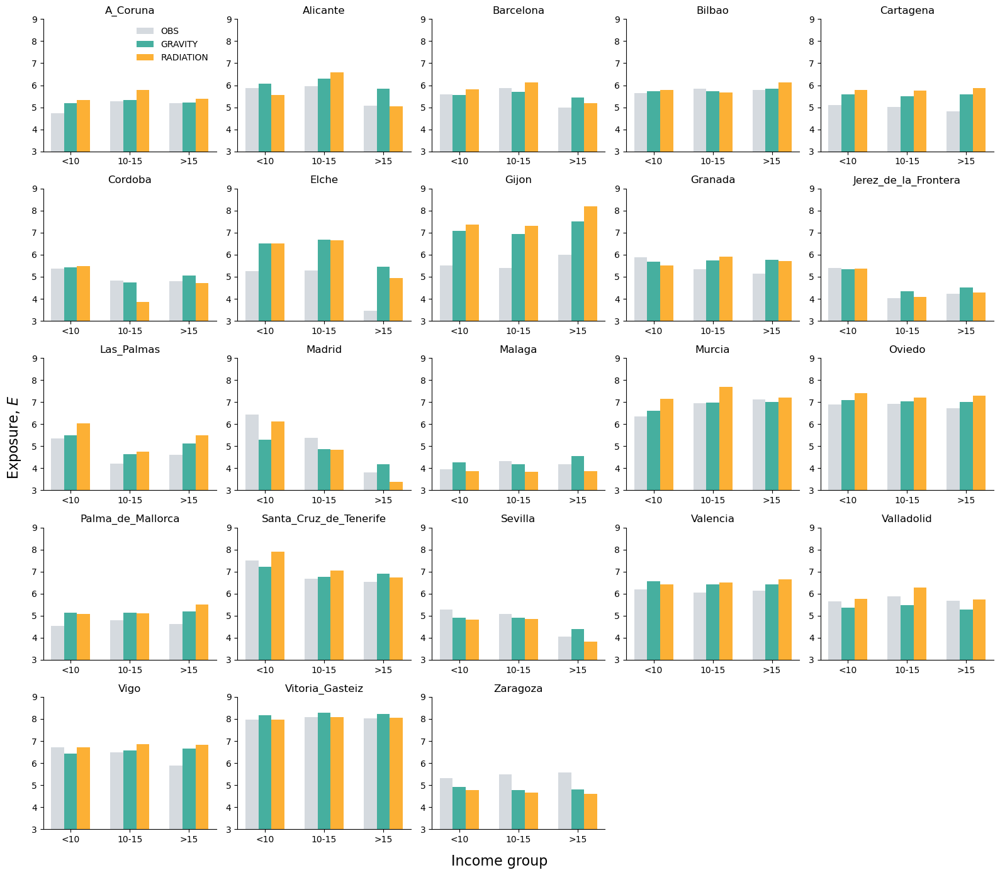

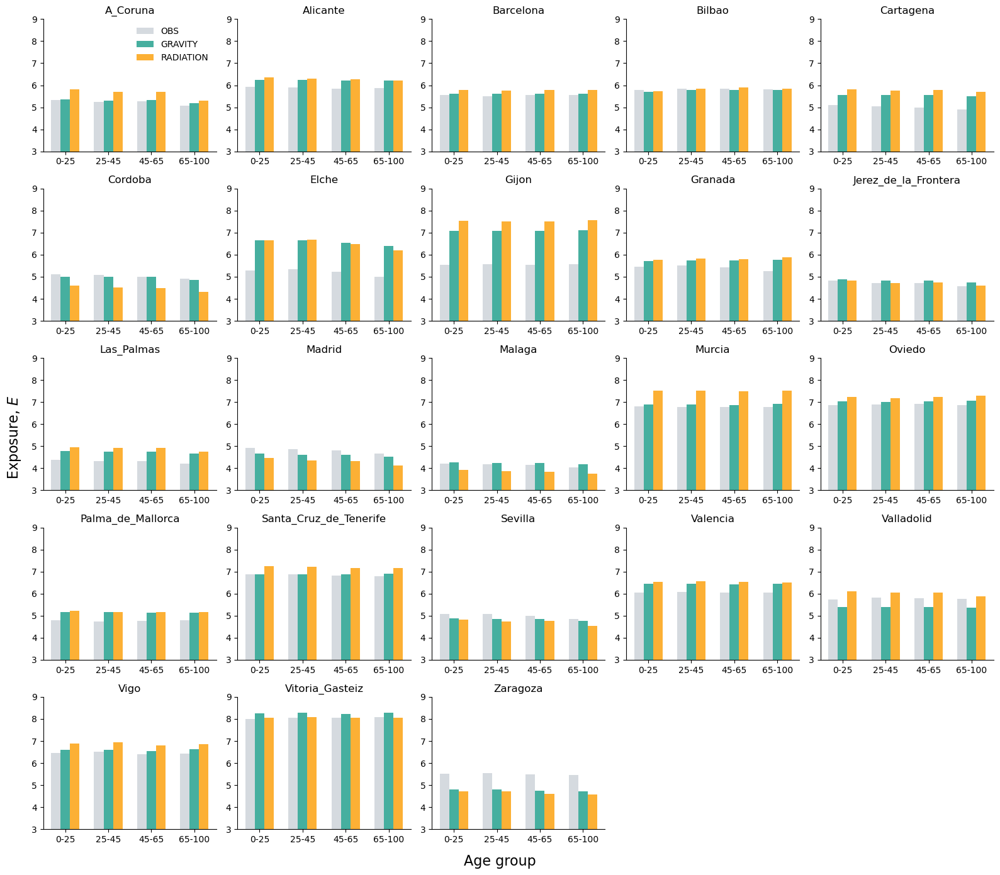

In [76]:
plot_metric_bar_city_grid(
    comparison_tbl = comparison_income,
    metric_name='E_T',
    group_col='renta',
    group_label='Income group',
    group_order=['<10','10-15','>15'],
    ylabel=r'Exposure, $E$',
    ylim=(3, 9),
    ncols=5,
    legend_mode='once'
)

plot_metric_bar_city_grid(
    comparison_tbl = comparison_age,
    metric_name='E_T',
    group_col='edad',
    group_label='Age group',
    group_order=['0-25', '25-45', '45-65', '65-100'],
    ylabel=r'Exposure, $E$',
    ylim=(3, 9),
    ncols=5,
    legend_mode='once'
)


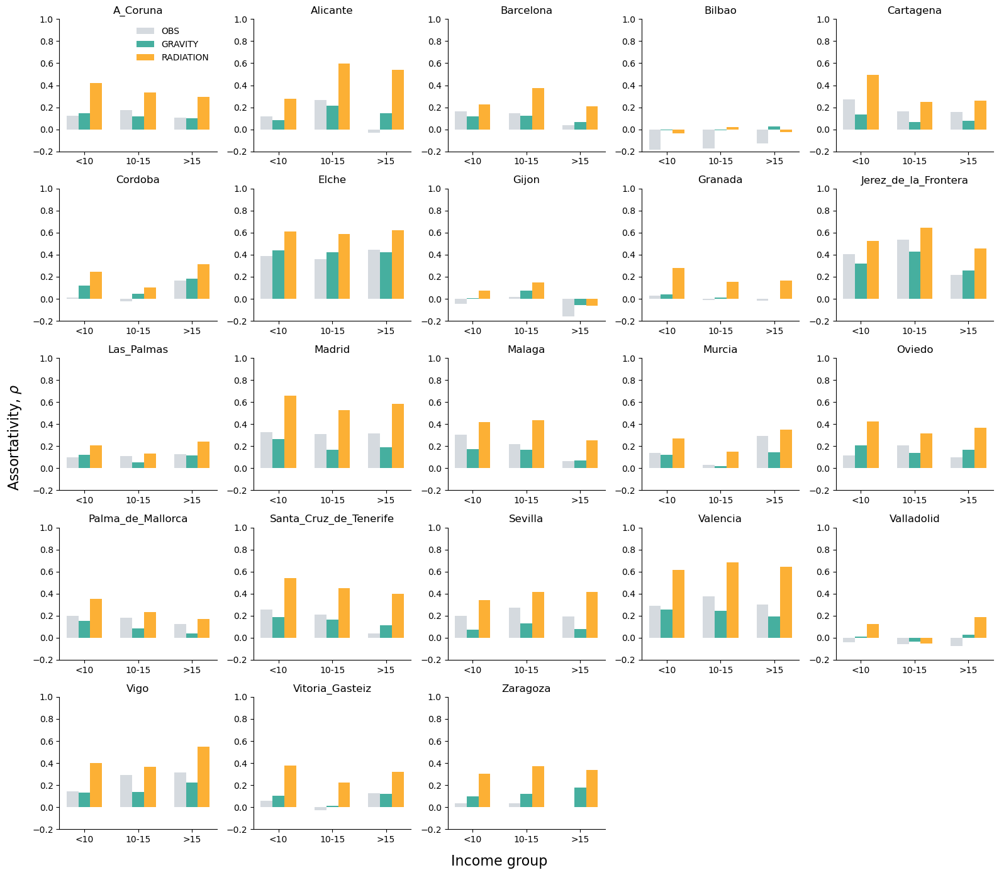

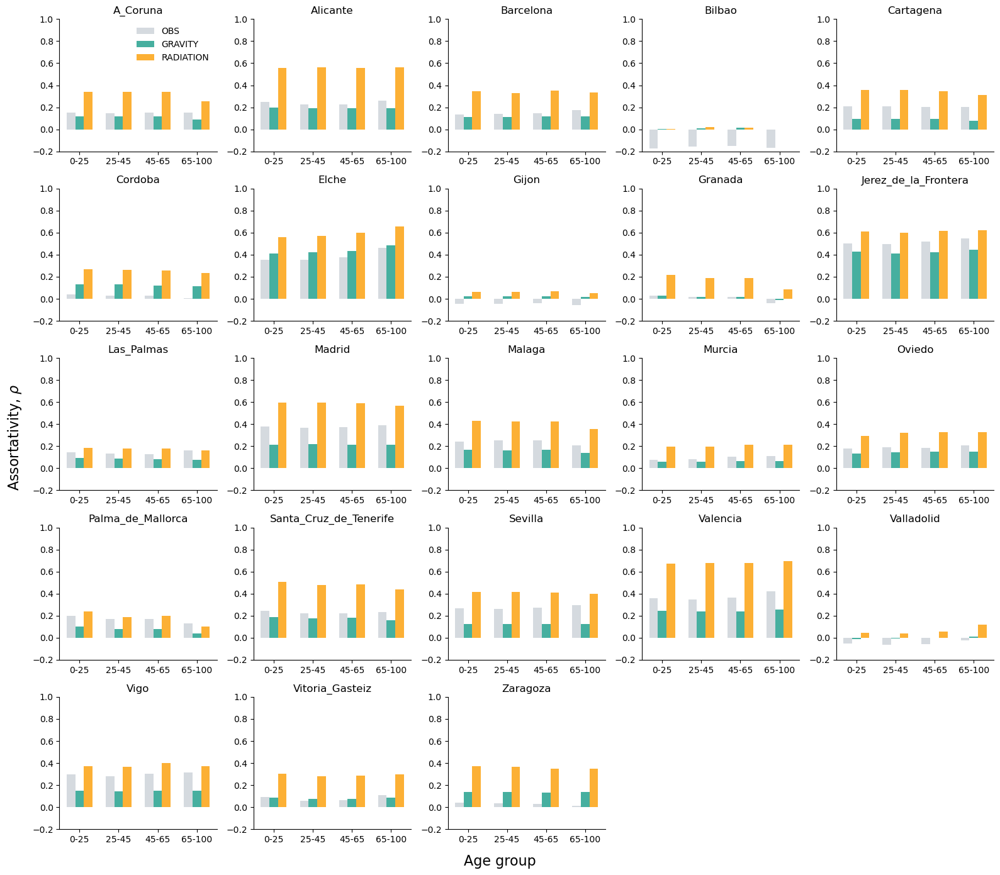

In [77]:
plot_metric_bar_city_grid(
    comparison_tbl = comparison_income,
    metric_name='rho_T',
    group_col='renta',
    group_label='Income group',
    group_order=['<10','10-15','>15'],
    ylabel=r'Assortativity, $\rho$',
    ylim=(-0.2, 1),
    ncols=5,
    legend_mode='once'
)

plot_metric_bar_city_grid(
    comparison_tbl = comparison_age,
    metric_name='rho_T',
    group_col='edad',
    group_label='Age group',
    group_order=['0-25', '25-45', '45-65', '65-100'],
    ylabel=r'Assortativity, $\rho$',
    ylim=(-0.2, 1),
    ncols=5,
    legend_mode='once'
)


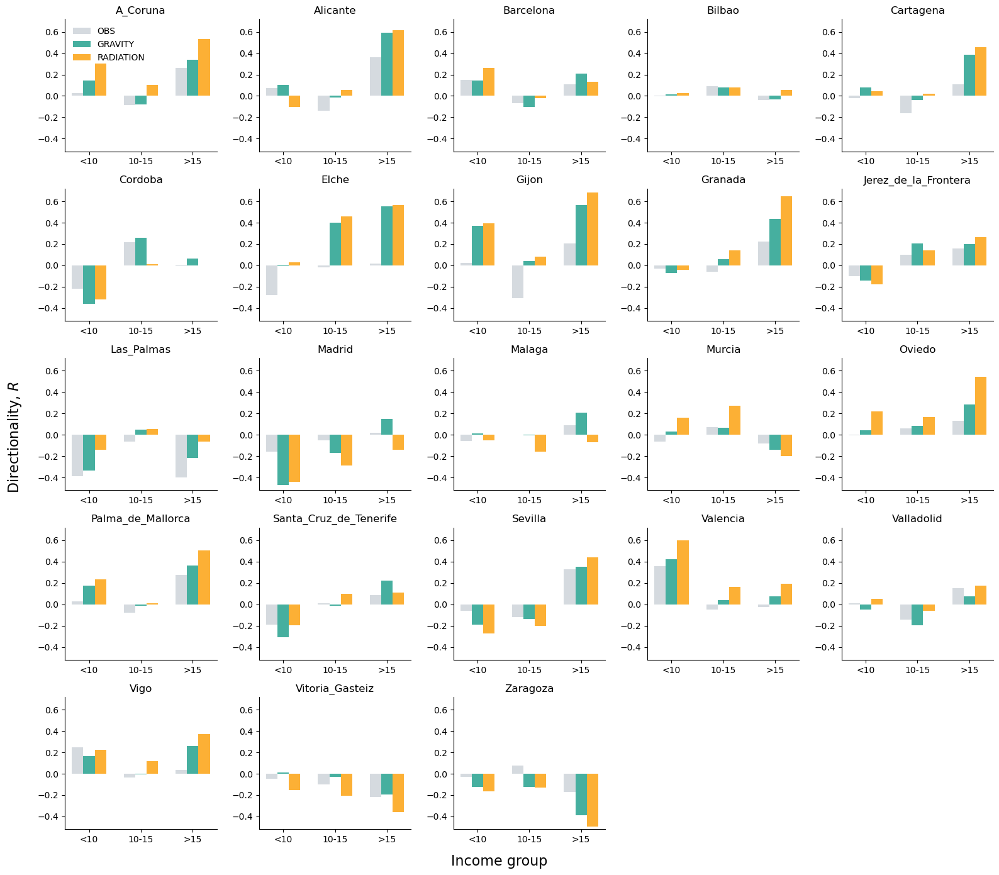

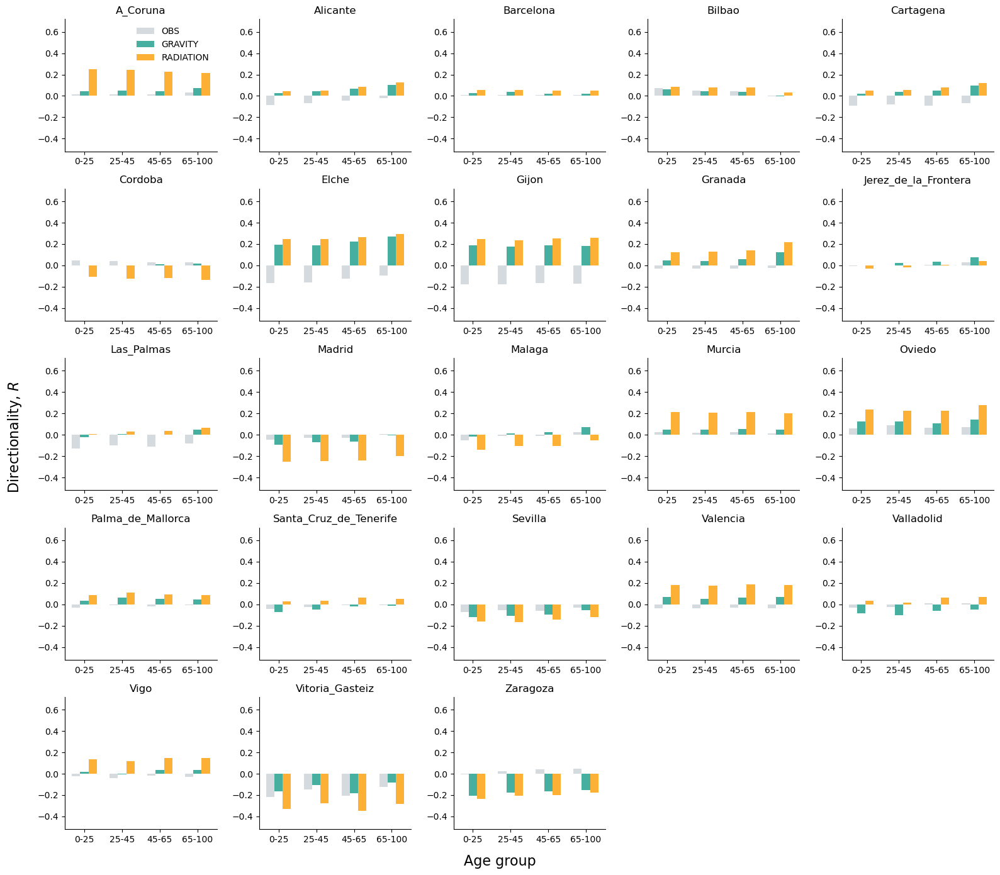

In [78]:
plot_metric_bar_city_grid(
    comparison_tbl = comparison_income,
    metric_name='R_T',
    group_col='renta',
    group_label='Income group',
    group_order=['<10','10-15','>15'],
    ylabel=r'Directionality, $R$',
    ylim=(-0.52, 0.72),
    ncols=5,
    legend_mode='once'
)

plot_metric_bar_city_grid(
    comparison_tbl = comparison_age,
    metric_name='R_T',
    group_col='edad',
    group_label='Age group',
    group_order=['0-25', '25-45', '45-65', '65-100'],
    ylabel=r'Directionality, $R$',
    ylim=(-0.52, 0.72),
    ncols=5,
    legend_mode='once'
)


## dE assessment

In [78]:
def build_gap_table(comparison, group_col, low_group, high_group,
                    metric_name='E_T'):
    """
    comparison: tabla ancha ['city', group_col, 'metric','OBS','GRAVITY',...]
    group_col: 'income'
    low_group, high_group: ej. '<10', '>15'
    """
    sub = comparison[comparison['metric'] == metric_name].copy()

    # pivot: index=city, cols=[(model,group)]
    piv = sub.pivot_table(index='city',
                          columns=[group_col],
                          values=['OBS','GRAVITY','RADIATION'])
    # modelos presentes
    models = piv.columns.get_level_values(0).unique().tolist()
    assert (low_group in piv.columns.get_level_values(1) and
            high_group in piv.columns.get_level_values(1)), \
        "Need both low_group and high_group in data"

    gap = {}
    for m in models:
        gap[m] = piv[(m, low_group)] - piv[(m, high_group)]
    gap_df = pd.DataFrame(gap).reset_index().rename(columns={'index':'city'})
    return gap_df

def _finite_xy(obs, pred):
    x = np.asarray(obs, float)
    y = np.asarray(pred, float)
    m = np.isfinite(x) & np.isfinite(y)
    return x[m], y[m]

def safe_best_fit_slope(obs, pred):
    x, y = _finite_xy(obs, pred)
    if x.size < 2:
        return np.nan
    x_std = float(x.std(ddof=1))
    if x_std == 0 or not np.isfinite(x_std):
        return np.nan
    x_mean = float(x.mean())
    xs = (x - x_mean) / x_std
    X = np.column_stack([np.ones_like(xs), xs])
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    b1 = float(beta[1]) / x_std
    return b1

def safe_r2(obs, pred):
    x, y = _finite_xy(obs, pred)
    if x.size < 2:
        return np.nan
    r = np.corrcoef(x, y)[0, 1]
    return float(r*r) if np.isfinite(r) else np.nan

def safe_err_stats(obs, pred):
    x, y = _finite_xy(obs, pred)
    if x.size == 0:
        return dict(bias=np.nan, MAE=np.nan, RMSE=np.nan)
    e = y - x
    return dict(
        bias = float(np.mean(e)),
        MAE  = float(np.mean(np.abs(e))),
        RMSE = float(np.sqrt(np.mean(e**2))),
    )

def summarize_gap_fit(gap_df):
    out = []
    models = [c for c in gap_df.columns if c not in ['city','OBS']]
    for m in models:
        obs, pred = gap_df['OBS'], gap_df[m]
        stats = safe_err_stats(obs, pred)
        out.append({
            'model': m,
            'slope': safe_best_fit_slope(obs, pred),
            'bias' : stats['bias'],
            'MAE'  : stats['MAE'],
            'RMSE' : stats['RMSE'],
            'R2'   : safe_r2(obs, pred),
            'n'    : int(np.isfinite(obs).sum())
        })
    return pd.DataFrame(out).sort_values('model')

# here we report intercept as well
def safe_ols_with_intercept(obs, pred):
    """
    OLS regression:
        pred = intercept + slope * obs
    Returns (slope, intercept)
    """
    x, y = _finite_xy(obs, pred)

    if x.size < 2:
        return np.nan, np.nan

    # Design matrix with intercept
    X = np.column_stack([np.ones_like(x), x])

    beta, *_ = np.linalg.lstsq(X, y, rcond=None)

    intercept = float(beta[0])
    slope     = float(beta[1])

    return slope, intercept

def summarize_gap_fit(gap_df):
    out = []
    models = [c for c in gap_df.columns if c not in ['city','OBS']]

    for m in models:
        obs, pred = gap_df['OBS'], gap_df[m]

        slope, intercept = safe_ols_with_intercept(obs, pred)
        stats = safe_err_stats(obs, pred)

        out.append({
            'model'    : m,
            'slope'    : slope,
            'intercept': intercept,
            'bias'     : stats['bias'],
            'MAE'      : stats['MAE'],
            'RMSE'     : stats['RMSE'],
            'R2'       : safe_r2(obs, pred),
            'n'        : int(np.isfinite(obs).sum())
        })

    return pd.DataFrame(out).sort_values('model')

In [79]:
gap_df_income = build_gap_table(
    comparison_income,
    group_col='renta',
    low_group='<10',
    high_group='>15',
    metric_name='E_T'
)

gap_fit_income = summarize_gap_fit(gap_df_income)
print(gap_fit_income)

       model     slope  intercept      bias       MAE      RMSE        R2   n
0    GRAVITY  0.451462  -0.042156 -0.284348  0.405130  0.551564  0.749967  23
1  RADIATION  0.863785  -0.037988 -0.098130  0.303609  0.391502  0.773373  23


In [80]:
gap_df_income

,city,GRAVITY,OBS,RADIATION
0,A_Coruna,-0.053,-0.432,-0.059
1,Alicante,0.207,0.808,0.520
2,Barcelona,0.133,0.583,0.627
3,Bilbao,-0.103,-0.164,-0.346
4,Cartagena,0.016,0.279,-0.070
5,Cordoba,0.369,0.566,0.769
6,Elche,1.076,1.801,1.570
7,Gijon,-0.420,-0.479,-0.835
8,Granada,-0.107,0.745,-0.192
9,Jerez_de_la_Frontera,0.829,1.186,1.070


In [81]:
gap_df_age = build_gap_table(
    comparison_age,
    group_col='edad',
    low_group='0-25',
    high_group='65-100',
    metric_name='E_T'
)

gap_fit_age = summarize_gap_fit(gap_df_age)
print(gap_fit_age)

       model     slope  intercept      bias       MAE      RMSE        R2   n
0    GRAVITY  0.569147  -0.009698 -0.052652  0.069000  0.088109  0.635277  23
1  RADIATION  1.084735   0.021552  0.030000  0.083739  0.116947  0.554823  23


In [82]:
gap_df_age

,city,GRAVITY,OBS,RADIATION
0,A_Coruna,0.191,0.267,0.519
1,Alicante,0.028,0.062,0.146
2,Barcelona,0.005,-0.006,0.012
3,Bilbao,-0.064,-0.017,-0.133
4,Cartagena,0.057,0.213,0.134
5,Cordoba,0.141,0.206,0.284
6,Elche,0.244,0.283,0.469
7,Gijon,-0.045,-0.036,-0.049
8,Granada,-0.057,0.198,-0.102
9,Jerez_de_la_Frontera,0.146,0.254,0.210


In [85]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def model_color_gap(m):
    # Colores consistentes con el barplot ponderado
    return {
        'GRAVITY'  : '#25a18e',
        'RADIATION': '#fca311'
    }.get(m, '#444444')


def plot_gap_scatter(
    gap_df,
    fit_df=None,   # dataframe con columnas al menos ['model','slope','R2']
    title='Inequality gap: Observed vs Predicted (per city)',
    xticks=None,
    yticks=None,
    kind='age',
    save_path=None 
):
    """
    gap_df: dataframe con columnas ['city', 'OBS', 'GRAVITY', 'RADIATION', ...]
    fit_df: dataframe con columnas ['model', 'slope', 'R2'] (opcional)
    xticks, yticks: listas con posiciones concretas de los ticks.
    """

    # --- delete a city ---
    # gap_df = gap_df[gap_df['city'] != 'Vigo']

    models = [c for c in gap_df.columns if c not in ['city', 'OBS']]
    # models = ['RADIATION','GRAVITY']

    if kind == 'age':
        fig, ax = plt.subplots(figsize=(5.2, 3.65))
    else:
        fig, ax = plt.subplots(figsize=(5.3, 4))
        
    # --- puntos de cada modelo ---
    for m in models:
        ax.scatter(
            gap_df['OBS'], gap_df[m],
            s=180,
            alpha=0.5,
            edgecolor='none',
            linewidth=1.5,
            color=model_color_gap(m)
        )

    # --- rango base (para fallback de límites automáticos) ---
    if xticks is not None and yticks is not None:
        lo = min(min(xticks), min(yticks))
        hi = max(max(xticks), max(yticks))
    else:
        vals = pd.concat([gap_df['OBS']] + [gap_df[m] for m in models])
        lo, hi = vals.min(), vals.max()

    # --- Ticks y límites ---
    if kind == 'age':
        if xticks is not None:
            ax.set_xticks(xticks)
            ax.set_xlim(min(xticks) - 0.025, max(xticks) + 0.025)
        else:
            ax.set_xlim(lo - 0.025, hi + 0.025)
    
        if yticks is not None:
            ax.set_yticks(yticks)
            ax.set_ylim(min(yticks) - 0.025, max(yticks) + 0.025)
        else:
            ax.set_ylim(lo - 0.025, hi + 0.025)
    
        # --- límites reales del eje y pequeño shift hacia dentro ---
        x_min, x_max = ax.get_xlim()
        y_min, y_max = ax.get_ylim()
    
        # Pequeño margen: 5% del rango
        margin_x = 0.1175 * (x_max - x_min)
        margin_y = 0.1175 * (y_max - y_min)

    else: 
        if xticks is not None:
            ax.set_xticks(xticks)
            ax.set_xlim(min(xticks) - 0.5, max(xticks) + 0.5)
        else:
            ax.set_xlim(lo - 0.5, hi + 0.5)
    
        if yticks is not None:
            ax.set_yticks(yticks)
            ax.set_ylim(min(yticks) - 0.5, max(yticks) + 0.5)
        else:
            ax.set_ylim(lo - 0.5, hi + 0.5)
    
        # --- límites reales del eje y pequeño shift hacia dentro ---
        x_min, x_max = ax.get_xlim()
        y_min, y_max = ax.get_ylim()
    
        # Pequeño margen: 5% del rango
        margin_x = 0.086 * (x_max - x_min)
        margin_y = 0.086 * (y_max - y_min)
        
    # Usamos límites "encogidos" para dibujar las líneas
    x0 = x_min + margin_x
    x1 = x_max - margin_x
    # Para y=x no necesitamos usar y0/y1 explícitamente: el eje recorta

    # --- línea gris y = x ---
    ax.plot(
        [x0, x1],
        [x0, x1],
        ls='--', c='gray', lw=2.5
    )

    # --- líneas de ajuste por modelo ---
    if fit_df is not None:
        fit_df_local = fit_df.copy()
        fit_df_local['model'] = fit_df_local['model'].astype(str)

        for m in models:
            row = fit_df_local[fit_df_local['model'] == m]
            if row.empty:
                continue

            slope = float(row['slope'].iloc[0])
            r2 = float(row['R2'].iloc[0]) if 'R2' in row.columns else np.nan

            # Línea de ajuste desde x0 a x1 (ligeramente dentro de los límites)
            x_vals = np.array([x0, x1])
            y_vals = slope * x_vals

            label = f"{m}"

            ax.plot(
                x_vals, y_vals,
                color=model_color_gap(m),
                lw=2.5,
                label=label
            )

    if kind == 'age':
        ax.set_xlabel(r'Observed $\Delta E^{age}$', fontsize=19.5, labelpad=2)
        ax.set_ylabel(r'Predicted $\Delta E^{age}$', fontsize=19.5, labelpad=2)

        ax.tick_params(axis='both', labelsize=18)
    else:
        ax.set_xlabel(r'Observed $\Delta E^{inc}$', fontsize=21, labelpad=2)
        ax.set_ylabel(r'Predicted $\Delta E^{inc}$', fontsize=21, labelpad=2)

        ax.tick_params(axis='both', labelsize=20)

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.4)

    # ax.legend(
    #     frameon=False,
    #     fontsize=16,
    #     loc='best'
    # )

    plt.tight_layout()

    if save_path is not None:
        fig.savefig(save_path, dpi=300, bbox_inches='tight')

    plt.show()

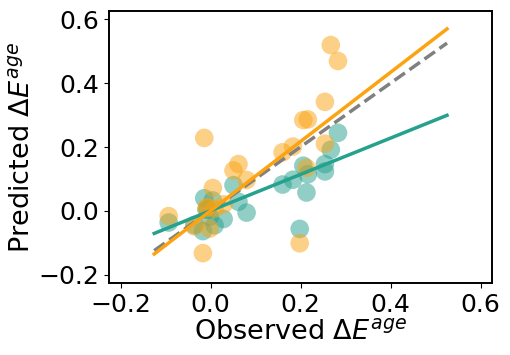

In [86]:
# # Income gap
plot_gap_scatter(
    gap_df_income,
    fit_df=gap_fit_income,
    xticks=[-1, 0, 1, 2, 3],
    yticks=[-1, 0, 1, 2, 3], save_path="heat_E_gap_obs_versus_modeling_income.svg", kind='income'
)

# Age gap
plot_gap_scatter(
    gap_df_age,
    fit_df=gap_fit_age,
    xticks=[-0.2, 0, 0.2, 0.4, 0.6],
    yticks=[-0.2, 0, 0.2, 0.4, 0.6], save_path="heat_E_gap_obs_versus_modeling_age.svg", kind='age'
)


In [86]:
def plot_model_comparison_panel_c(
    gap_fit_income,
    gap_fit_age,
    figsize=(5, 3),
    date_str='',
    fname_prefix='figure4_panelC'
):

    model_colors = {
        'GRAVITY':  '#25a18e',
        'RADIATION': '#fca311',
    }

    models = ['GRAVITY', 'RADIATION']

    inc = gap_fit_income.set_index('model').loc[models]
    age = gap_fit_age.set_index('model').loc[models]

    fig, axes = plt.subplots(2, 2, figsize=figsize)

    metrics = ['slope', 'R2']
    row_titles = ['Slope, b', r'$R^2$']
    col_titles = ['Income', 'Age']

    bar_width = 0.35
    x_center = 0

    for col, group_data in enumerate([inc, age]):
        for row, metric in enumerate(metrics):

            ax = axes[row, col]
            values = group_data[metric].values

            # compressed bars around center
            ax.bar(
                x_center - bar_width/2,
                values[0],
                width=bar_width,
                color=model_colors['GRAVITY'],
                alpha=0.9
            )

            ax.bar(
                x_center + bar_width/2,
                values[1],
                width=bar_width,
                color=model_colors['RADIATION'],
                alpha=0.9
            )
            

            # ---- Fixed y-limits ----
            if metric == 'slope':
                ax.set_ylim(0, 1.25)

                # Línea roja dashed en y = 1
                ax.axhline(
                    y=1,
                    xmin=-bar_width,
                    xmax=2.1*bar_width,
                    color='red',
                    linestyle='--',
                    linewidth=3,
                    zorder=2
                )

            elif metric == 'R2':
                ax.set_ylim(0, 1)
                ax.set_yticks([0, 1])

            # Remove x ticks completely
            ax.set_xticks([])

            ax.tick_params(axis='y', labelsize=14)

            # Column titles
            if row == 0:
                ax.set_title(col_titles[col], fontsize=17)

            # Y labels only on Income column
            if col == 0:
                ax.set_ylabel(row_titles[row], fontsize=16)
            else:
                ax.set_ylabel('')
                ax.set_yticklabels([])
                ax.tick_params(axis='y', left=False)

            # Tight x limits to remove whitespace
            ax.set_xlim(-0.6, 0.6)

    sns.despine()
    plt.tight_layout()

    if date_str:
        fname = f"{fname_prefix}_{date_str}.svg"
        plt.savefig(fname, format='svg', dpi=600, bbox_inches='tight')

    plt.show()

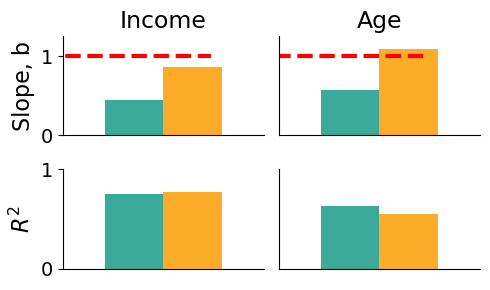

In [87]:
plot_model_comparison_panel_c(
    gap_fit_income,
    gap_fit_age,
    figsize=(5, 3),
    date_str=DATE,
    fname_prefix='figure4_panelC'
)

## E exposure assessment

In [88]:
import numpy as np
import pandas as pd

# ============================================================
# 1) Build table with E_obs and E_pred directly (not gaps)
# ============================================================
def build_level_table(comparison, group_col, groups, metric_name='E_T'):
    """
    comparison: long/wide table with columns like
        ['city', group_col, 'metric', 'OBS', 'GRAVITY', 'RADIATION', ...]
    group_col: e.g. 'renta' or 'edad'
    groups: list of groups to keep, e.g. ['<10','>15'] or ['0-25','65-100']
    metric_name: e.g. 'E_T'

    Returns:
        DataFrame with columns ['city', group_col, 'OBS', 'GRAVITY', 'RADIATION', ...]
        filtered to the selected metric and groups.
    """
    sub = comparison[comparison['metric'] == metric_name].copy()
    sub = sub[sub[group_col].isin(groups)].copy()

    keep_cols = ['city', group_col, 'OBS', 'GRAVITY', 'RADIATION']
    keep_cols = [c for c in keep_cols if c in sub.columns]

    return sub[keep_cols].reset_index(drop=True)


# ============================================================
# 2) Helpers
# ============================================================
def _finite_xy(obs, pred):
    x = np.asarray(obs, float)
    y = np.asarray(pred, float)
    m = np.isfinite(x) & np.isfinite(y)
    return x[m], y[m]

def safe_ols_with_intercept(obs, pred):
    """
    OLS regression:
        pred = intercept + slope * obs
    Returns (slope, intercept)
    """
    x, y = _finite_xy(obs, pred)

    if x.size < 2:
        return np.nan, np.nan

    X = np.column_stack([np.ones_like(x), x])
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)

    intercept = float(beta[0])
    slope     = float(beta[1])

    return slope, intercept

def safe_r2(obs, pred):
    x, y = _finite_xy(obs, pred)
    if x.size < 2:
        return np.nan
    r = np.corrcoef(x, y)[0, 1]
    return float(r*r) if np.isfinite(r) else np.nan

def safe_err_stats(obs, pred):
    x, y = _finite_xy(obs, pred)
    if x.size == 0:
        return dict(bias=np.nan, MAE=np.nan, RMSE=np.nan)
    e = y - x
    return dict(
        bias=float(np.mean(e)),
        MAE=float(np.mean(np.abs(e))),
        RMSE=float(np.sqrt(np.mean(e**2))),
    )


# ============================================================
# 3) Summarize fit by group
# ============================================================
def summarize_level_fit(level_df, group_col):
    """
    For each model and each group, fit:
        E_pred = intercept + slope * E_obs

    Returns one row per (model, group)
    """
    out = []
    models = [c for c in level_df.columns if c not in ['city', group_col, 'OBS']]

    for g in sorted(level_df[group_col].dropna().unique()):
        sub = level_df[level_df[group_col] == g].copy()

        for m in models:
            obs, pred = sub['OBS'], sub[m]
            slope, intercept = safe_ols_with_intercept(obs, pred)
            stats = safe_err_stats(obs, pred)

            out.append({
                'group_col' : group_col,
                'group'     : g,
                'model'     : m,
                'slope'     : slope,
                'intercept' : intercept,
                'bias'      : stats['bias'],
                'MAE'       : stats['MAE'],
                'RMSE'      : stats['RMSE'],
                'R2'        : safe_r2(obs, pred),
                'n'         : int(np.isfinite(obs).sum())
            })

    return pd.DataFrame(out).sort_values(['group', 'model']).reset_index(drop=True)

In [89]:
level_df_income = build_level_table(
    comparison_income,
    group_col='renta',
    groups=['<10','10-15','>15'],
    metric_name='E_T'
)

fit_levels_income = summarize_level_fit(level_df_income, group_col='renta')
print(fit_levels_income)

  group_col  group      model     slope  intercept      bias       MAE  \
0     renta  10-15    GRAVITY  0.941655   0.498167  0.170522  0.369652   
1     renta  10-15  RADIATION  1.075524  -0.146117  0.278000  0.554783   
2     renta    <10    GRAVITY  0.818453   1.181299  0.135130  0.403391   
3     renta    <10  RADIATION  0.940954   0.601514  0.261261  0.445696   
4     renta    >15    GRAVITY  0.834177   1.301824  0.419478  0.527652   
5     renta    >15  RADIATION  1.008824   0.312437  0.359391  0.537391   

       RMSE        R2   n  
0  0.531079  0.760491  23  
1  0.689497  0.724823  23  
2  0.559136  0.671255  23  
3  0.610398  0.705414  23  
4  0.687154  0.758610  23  
5  0.751864  0.735276  23  


In [91]:
level_df_age = build_level_table(
    comparison_age,
    group_col='edad',
    groups=['0-25','25-45','45-65','65-100'],
    metric_name='E_T'
)

fit_levels_age = summarize_level_fit(level_df_age, group_col='edad')
print(fit_levels_age)

  group_col   group      model     slope  intercept      bias       MAE  \
0      edad    0-25    GRAVITY  0.990065   0.240461  0.184478  0.330913   
1      edad    0-25  RADIATION  1.083208  -0.166038  0.302826  0.507783   
2      edad   25-45    GRAVITY  0.975254   0.320681  0.181304  0.334348   
3      edad   25-45  RADIATION  1.079847  -0.171327  0.278391  0.499870   
4      edad   45-65    GRAVITY  0.967943   0.380820  0.201391  0.335739   
5      edad   45-65  RADIATION  1.074650  -0.128960  0.288870  0.500609   
6      edad  65-100    GRAVITY  0.960665   0.454854  0.237130  0.360696   
7      edad  65-100  RADIATION  1.087734  -0.212795  0.272826  0.503696   

       RMSE        R2   n  
0  0.505741  0.771762  23  
1  0.660356  0.725730  23  
2  0.504526  0.777902  23  
3  0.653156  0.734152  23  
4  0.509317  0.777716  23  
5  0.651745  0.736264  23  
6  0.531734  0.788121  23  
7  0.657052  0.753964  23  


In [93]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def model_color_gap(m):
    return {
        'GRAVITY': '#25a18e',
        'RADIATION': '#fca311'
    }.get(m, '#444444')


def plot_level_scatter(
    level_df,
    fit_df=None,
    group_col='renta',
    groups=None,
    kind='income',
    xticks=None,
    yticks=None,
    save_path=None
):
    """
    Scatter plot(s) of E_pred vs E_obs by social group.

    Parameters
    ----------
    level_df : pd.DataFrame
        Must contain columns:
        ['city', group_col, 'OBS', 'GRAVITY', 'RADIATION', ...]
    fit_df : pd.DataFrame or None
        Output of summarize_level_fit(), with columns:
        ['group', 'model', 'slope', 'intercept', 'R2', ...]
    group_col : str
        'renta' or 'edad'
    groups : list
        groups to plot, e.g. ['<10','>15'] or ['0-25','65-100']
    kind : str
        'income' or 'age'
    xticks, yticks : list or None
    save_path : str or None
    """

    if groups is None:
        groups = sorted(level_df[group_col].dropna().unique())

    n_groups = len(groups)
    fig, axes = plt.subplots(1, n_groups, figsize=(5.2 * n_groups, 4), sharex=False, sharey=False)

    if n_groups == 1:
        axes = [axes]

    models = [c for c in level_df.columns if c not in ['city', group_col, 'OBS']]

    for ax, g in zip(axes, groups):
        sub = level_df[level_df[group_col] == g].copy()

        # --- scatter points ---
        for m in models:
            ax.scatter(
                sub['OBS'], sub[m],
                s=140,
                alpha=0.55,
                edgecolor='none',
                color=model_color_gap(m)
            )

        # --- axis range ---
        vals = pd.concat([sub['OBS']] + [sub[m] for m in models])
        lo, hi = vals.min(), vals.max()

        if xticks is not None:
            ax.set_xticks(xticks)
            x_min, x_max = min(xticks), max(xticks)
        else:
            x_min, x_max = lo, hi

        if yticks is not None:
            ax.set_yticks(yticks)
            y_min, y_max = min(yticks), max(yticks)
        else:
            y_min, y_max = lo, hi

        # small padding
        dx = 0.04 * (x_max - x_min) if x_max > x_min else 0.1
        dy = 0.04 * (y_max - y_min) if y_max > y_min else 0.1

        ax.set_xlim(x_min - dx, x_max + dx)
        ax.set_ylim(y_min - dy, y_max + dy)

        # --- y = x line ---
        xx = np.array([x_min, x_max])
        ax.plot(xx, xx, ls='--', c='gray', lw=2.2)

        # --- fitted lines by model ---
        if fit_df is not None:
            fit_sub = fit_df[fit_df['group'] == g].copy()

            for m in models:
                row = fit_sub[fit_sub['model'] == m]
                if row.empty:
                    continue

                slope = float(row['slope'].iloc[0])
                intercept = float(row['intercept'].iloc[0]) if 'intercept' in row.columns else 0.0

                x_vals = np.array([x_min, x_max])
                y_vals = intercept + slope * x_vals

                ax.plot(
                    x_vals, y_vals,
                    color=model_color_gap(m),
                    lw=2.4,
                    label=m
                )

        # --- titles ---
        if kind == 'income':
            title_map = {'<10': 'Low income', '>15': 'High income', '10-15': 'Middle income'}
        else:
            title_map = {'0-25': 'Young', '25-45': '25–45', '45-65': '45–65', '65-100': 'Elderly'}

        ax.set_title(title_map.get(g, str(g)), fontsize=18)

        ax.set_xlabel(r'Observed $E$', fontsize=18)
        ax.tick_params(axis='both', labelsize=16)

        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(1.3)

    axes[0].set_ylabel(r'Predicted $E$', fontsize=18)

    # legend only once
    handles, labels = axes[0].get_legend_handles_labels()
    if handles:
        fig.legend(
            handles, labels,
            frameon=False, fontsize=15,
            loc='center right', bbox_to_anchor=(0.92, 0.35)
        )
        plt.tight_layout(rect=[0, 0, 0.93, 1])
    else:
        plt.tight_layout()

    if save_path is not None:
        fig.savefig(save_path, dpi=300, bbox_inches='tight')

    plt.show()

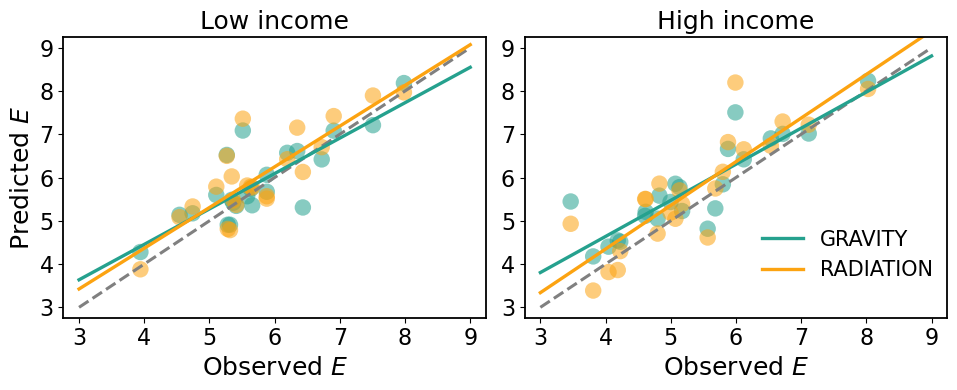

In [94]:
plot_level_scatter(
    level_df_income,
    fit_df=fit_levels_income,
    group_col='renta',
    groups=['<10', '>15'],
    kind='income',
    xticks=[3, 4, 5, 6, 7, 8, 9],
    yticks=[3, 4, 5, 6, 7, 8, 9],
    save_path='heat_E_levels_obs_versus_modeling_income.svg'
)

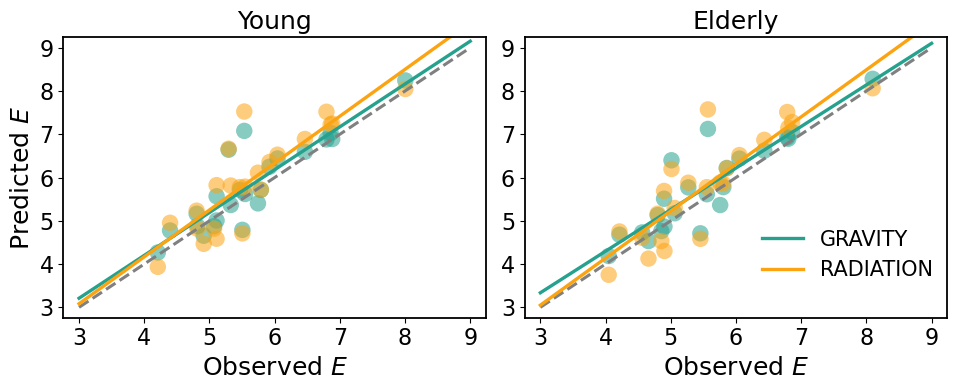

In [95]:
plot_level_scatter(
    level_df_age,
    fit_df=fit_levels_age,
    group_col='edad',
    groups=['0-25', '65-100'],
    kind='age',
    xticks=[3, 4, 5, 6, 7, 8, 9],
    yticks=[3, 4, 5, 6, 7, 8, 9],
    save_path='heat_E_levels_obs_versus_modeling_age.svg'
)